# NABRA AI

هذا الدفتر مبني على `NABRA_AI_Organized.ipynb` ويحتفظ بمراحل المشروع الأصلية: معالجة التسجيلات، Whisper، Pyannote، DistilBERT، Qwen ولوحة Streamlit.

> **مهم:** النسخة تحتاج تشغيلًا فعليًا في Google Colab، وملفات النموذج/البيانات من Google Drive. عدم وجود أخطاء نحوية لا يثبت نجاح تشغيل النماذج. لا تسلّمي المشروع قبل اكتمال فحص **A5** و**S1** واختبار مكالمة حقيقيّة/تجريبية.

> **حدود المشروع الحالي:** هذه النسخة تحلل مكالمة مسجلة وتصدر ملخصًا وحالة حل، **وليست حتى الآن مساعدًا صوتيًا يتحدث مباشرة مع العميل عبر RAG وTTS**. لا تعرضيها للمدربين بهذه الصفة إلا بعد إضافة واختبار تلك الوظائف.

## قبل البدء

1. افتحي هذا الدفتر في **Google Colab**، ثم **Runtime → Change runtime type → T4 GPU**.
2. خزّني `HF_TOKEN` في **Secrets** (أيقونة المفتاح) وفعّلي Notebook access، مع قبول شروط [pyannote Community-1](https://huggingface.co/pyannote/speaker-diarization-community-1).
3. في Google Drive، يجب أن يكون مجلد `MyDrive/CallSense_AI/` ويحتوي إما على `project_backup/` محفوظ ومكتمل **أو** ملف بيانات `.rar` للتدريب من الصفر.
4. **التشغيل السريع بعد التدريب:** A1 → Restart session → A2 → A4 → A5 → H2 → H4 → H5 (أو خيار العرض الخاص أسفل H5). لا تحتاجين إعادة تدريب C12.
5. **البناء لأول مرة:** A1 → Restart → A2 → A4 → A5 (قد يعرض البيانات فقط) → الأجزاء B إلى I بالترتيب مع الخلايا المعتمدة؛ ثم **S1**.
6. بعد إنهاء التقييم والتدريب وحفظ الملفات، شغّلي **S1** لتأكيد حزمة التسليم وإنشاء `NABRA_AI_Final_Submission.zip` على Drive. واحفظي ملف الـ notebook نفسه هناك.

### ما الذي عُدّل لأمان النسخة النهائية؟

- تبسيط تثبيت المكتبات، بدل عدة أوامر تثبيت متعارضة وإعادة تثبيت قسري.
- استعادة **الملفات الناقصة** من نسخة Drive دون استبدال النسخ المحلية الموجودة.
- إضافة فحص واضح لمدى جاهزية التشغيل السريع.
- حماية أحكام المراجعة اليدوية من أن تُحذف عند إعادة تشغيل I1، وحفظ تقدم المراجعة إلى Drive بعد كل مكالمة.
- تغيير فحص المسار والبيانات الوصفية لرسائل تشخيصية أوضح.
- إضافة **S1** لفحص المخرجات الأساسية وإنشاء حزمة نهائية دون تضمين التسجيلات الخام أو رموز الوصول.

### ملاحظات

- قد توجد تحذيرات `google-adk` و`opentelemetry` بسبب مكتبات Colab الأخرى؛ نتأكد من تشغيل المكتبات المطلوبة فعلًا بدل افتراض أن كل تحذير يعني فشل المشروع.
- روابط Cloudflare سريعة **عامة**؛ لا ترفعي تسجيلات عملاء حقيقية أو حساسة في رابط عام دون تصريح.
- **للتسليم**: احتفظي بنسخة `ipynb` وملف ZIP النهائي ونتائج الاختبار. لا تضعي `HF_TOKEN` في الملفات.

---

> **GitHub evaluation preview:** This notebook includes selected outputs from an actual Colab run: dataset quality, train/validation/test split, Whisper WER/CER, speaker-role evaluation, and figures. Audio previews, complete transcripts, model tokens, temporary URLs, and detailed customer-service content are intentionally excluded because this repository is public. Saved outputs document the previous execution; to reproduce them, run the cells in Colab with access to the required models and data.


# الجزء A — تجهيز الجلسة وربط الملفات

**الترتيب الجديد:** A1 → Restart session → A2 → A4 → A5. بعد ذلك اختاري التشغيل السريع (H2/H4/H5) أو البناء الكامل (B–I).

> لا تشغّلي **Runtime → Run all**: بعض الخلايا تعيد التدريب وبعضها تطلب رفع ملف أو مراجعة بشرية.


In [ ]:
# 🟢 A1 | تثبيت المكتبات مرة واحدة في كل جلسة جديدة؛ بعدها Runtime → Restart session
# تثبيت واحد متناسق لتفادي إعادة التثبيت القسري والتعارض بين عدة خلايا.
%pip install -q "numpy==2.2.6" "scipy==1.15.3" "scikit-learn==1.6.1" "datasets==4.8.4" "pyarrow==23.0.1" "transformers==4.57.6" "accelerate>=1,<2" "bitsandbytes" "pyannote.audio==4.0.7" "openai-whisper" "jiwer" "soundfile" "streamlit" "jedi" "joblib" "altair"
print("Installation completed. Restart session now, then run A2. Do not re-run A1 in this session.")

In [ ]:
# 🟢 A2 | فحص المكتبات بعد Restart (بدون إعادة تثبيت تُفسد البيئة)
import importlib.metadata as md
import shutil, subprocess
import numpy as np, scipy, sklearn, torch
import transformers, datasets, pyarrow, whisper, streamlit
from pyannote.audio import Pipeline
from transformers import Trainer, TrainingArguments
packages = ["numpy", "scipy", "scikit-learn", "torch", "transformers", "datasets", "pyarrow", "pyannote.audio", "openai-whisper", "streamlit"]
for name in packages:
    print(f"{name:17s}", md.version(name))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT ENABLED — select T4 GPU")
print("ffmpeg:", shutil.which("ffmpeg") or "NOT FOUND")
assert torch.cuda.is_available(), "Enable T4 GPU: Runtime → Change runtime type."
assert shutil.which("ffmpeg"), "ffmpeg is required for audio decoding."
print("Core imports OK ✅")

In [ ]:
# ⚪ اختيارية | A3 | التأكد أن المكتبات تعمل
import numpy as np
import scipy
import sklearn
from sklearn.model_selection import train_test_split

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All libraries working!")

In [ ]:
# 🟢 A4 | ربط Google Drive وHF token واستعادة الملفات الناقصة فقط (بلا حذف نتائجك)
import os, shutil, subprocess
from pathlib import Path
from getpass import getpass
from google.colab import drive, userdata

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")
PROJECT_DIR = Path("/content/CallSense_AI")
DRIVE_DIR = Path("/content/drive/MyDrive/CallSense_AI")
BACKUP_DIR = DRIVE_DIR / "project_backup"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_DIR.mkdir(parents=True, exist_ok=True)
os.environ["CALLSENSE_PROJECT_DIR"] = str(PROJECT_DIR)

try:
    HF_TOKEN = userdata.get("HF_TOKEN") or ""
except Exception:
    HF_TOKEN = ""
if not HF_TOKEN:
    HF_TOKEN = getpass("HF_TOKEN (input hidden; never save in notebook): ").strip()
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
else:
    print("⚠️ HF_TOKEN is missing: Pyannote cannot load until it is set in Colab Secrets.")

# When backup exists, restore only missing individual files; preserve local changes and saved reviews.
restored = 0
folders = ["models", "data/splits", "data/processed", "evaluation", "outputs", "reports", "app"]
if BACKUP_DIR.is_dir():
    for rel in folders:
        source = BACKUP_DIR / rel
        if not source.is_dir():
            continue
        for file in source.rglob("*"):
            if file.is_file():
                target = PROJECT_DIR / rel / file.relative_to(source)
                if not target.exists():
                    target.parent.mkdir(parents=True, exist_ok=True)
                    shutil.copy2(file, target)
                    restored += 1
    print(f"Restored missing files: {restored} from {BACKUP_DIR}")
else:
    print("No project_backup folder found. Full build will need original .rar data.")
print("Drive:", DRIVE_DIR, "| HF token present:", bool(HF_TOKEN))

In [ ]:
from pathlib import Path
from huggingface_hub import hf_hub_download
import shutil, json

repo = "apptek-com/apptek_callcenter_dialogues"
raw = Path("/content/CallSense_AI/data/raw")
raw.mkdir(parents=True, exist_ok=True)

# الاحتفاظ بأي تسجيلات وصلت سابقًا
for f in Path("/content").glob("en_AU_*.wav"):
    shutil.copy2(f, raw / f.name)

# تحميل بيانات المكالمات مباشرة
meta = hf_hub_download(
    repo_id=repo,
    repo_type="dataset",
    filename="diarization/en-AU/metadata.jsonl"
)

shutil.copy2(meta, raw / "metadata.jsonl")

records = [
    json.loads(line)
    for line in open(meta, encoding="utf-8")
    if line.strip()
]

# إذا لم توجد تسجيلات، تحميل مكالمة تجريبية تلقائيًا
if not list(raw.glob("*.wav")):
    name = records[0]["file_name"]
    audio = hf_hub_download(
        repo_id=repo,
        repo_type="dataset",
        filename=f"diarization/en-AU/{name}"
    )
    shutil.copy2(audio, raw / Path(name).name)

print("✅ Audio files:", len(list(raw.glob("*.wav"))))
print("✅ Metadata records:", len(records))
print("✅ DATA READY FOR TESTING")

In [ ]:
from pathlib import Path
import shutil

source = Path("/content")
target = Path("/content/CallSense_AI/data/raw")
target.mkdir(parents=True, exist_ok=True)

audio_files = list(source.glob("*.wav"))

for file in audio_files:
    shutil.move(str(file), str(target / file.name))

print("✅ عدد الملفات الصوتية:", len(list(target.rglob("*.wav"))))
print("📄 ملف metadata:", bool(list(target.rglob("metadata.jsonl"))))

### A5 — اختاري المسار بناءً على الملفات الموجودة

هذا الفحص لا يدرب أي نموذج ولا يغير الملفات. إذا كانت ملفات `project_backup` موجودة ومكتملة، شغّلي **H2 ثم H4 ثم H5**. إذا لم تكن موجودة لكن عندك `.rar`، ارجعي للجزء **B** وكمّلي التدريب والتقييم حتى **I5**. إذا الاثنين مفقودين ارفعي الملفات أولًا إلى Drive.

In [ ]:
# 🟢 A5 | فحص جاهزية التشغيل السريع (بدون تعديل أو حذف)
from pathlib import Path
required_fast = {
    "Streamlit dashboard": PROJECT_DIR / "app/app.py",
    "Pipeline": PROJECT_DIR / "app/callsense_pipeline.py",
    "DistilBERT config": PROJECT_DIR / "models/speaker_role/distilbert_final/config.json",
}
for name, p in required_fast.items():
    print(("✅" if p.is_file() else "❌"), name, "—", p)
weights_dir = PROJECT_DIR / "models/speaker_role/distilbert_final"
weights_ok = any((weights_dir / f).is_file() for f in ("model.safetensors", "pytorch_model.bin"))
print(("✅" if weights_ok else "❌"), "DistilBERT weights")
ready = all(p.is_file() for p in required_fast.values()) and weights_ok
rar_list = list(DRIVE_DIR.glob("*.rar"))
print("Drive backup:", BACKUP_DIR.is_dir(), "| RAR files:", [p.name for p in rar_list])
if ready:
    print("✅ QUICK START READY: run H2, H4, H5 (and test one call).")
elif rar_list:
    print("⚠️ BACKUP INCOMPLETE: go to Part B for data preparation and training before H4.")
else:
    print("❌ Missing both complete backup and .rar dataset. Upload project files to MyDrive/CallSense_AI.")

# الجزء B — تجهيز البيانات (Steps 1–6)  🔵 مرة واحدة

**ايش يسوي؟** يفك ضغط المكالمات، يتأكد أن الصوت سليم، يقرأ ملف الـ metadata (من تكلم، ومتى، وايش قال)، يربطه بالصوت، وينظّف المقاطع. في الآخر يقسّم المكالمات الـ 48 إلى: **34 تدريب / 7 تحقق / 7 اختبار**.

**يحتاج:** ملف `.rar` للبيانات داخل `MyDrive/CallSense_AI/` (انظر جدول الملفات في أول الدفتر).
**ينتج:** ملفات `data/splits/train.csv · validation.csv · test.csv` وتقارير جودة في `reports/`.

بعد ما تخلص منه مرة واحدة، النتائج تنحفظ ولا تحتاج تعيده.

## B-1 · فك ضغط البيانات

In [ ]:
# 🔵 B1 | استخراج ملف RAR الأصلي من Drive؛ لا تشغّليها في التشغيل السريع
from pathlib import Path
import subprocess, shutil
folder = Path("/content")
rar_files = sorted(folder.glob("*.rar"))
if not rar_files:
    raise FileNotFoundError(f"لم أجد .rar في {folder}. ارفعي بيانات المشروع الأصلية أو استخدمي project_backup للتشغيل السريع.")
if shutil.which("unrar") is None:
    subprocess.run(["apt-get", "-qq", "update"], check=True, capture_output=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "unrar"], check=True, capture_output=True)
output = PROJECT_DIR / "data/raw"
output.mkdir(parents=True, exist_ok=True)
print("Extracting:", rar_files[0].name)
subprocess.run(["unrar", "x", "-o+", str(rar_files[0]), str(output) + "/"], check=True)
print("Extraction completed | files:", sum(p.is_file() for p in output.rglob("*")))
assert any(p.suffix.lower() in {".wav", ".mp3", ".flac", ".m4a"} for p in output.rglob("*")), "No extracted audio found! Check the RAR content."

In [ ]:
# ⚪ اختيارية | B2 | عرض الملفات المستخرجة
from pathlib import Path

data_dir = Path("/content/CallSense_AI/data/raw")

files = [p for p in data_dir.rglob("*") if p.is_file()]

print("Total files:", len(files))

for file in files:
    print(file.relative_to(data_dir))


In [ ]:
from pathlib import Path
from huggingface_hub import hf_hub_download
import shutil, json

repo = "apptek-com/apptek_callcenter_dialogues"
raw = Path("/content/CallSense_AI/data/raw")
raw.mkdir(parents=True, exist_ok=True)

# الاحتفاظ بأي تسجيلات وصلت سابقًا
for f in Path("/content").glob("en_AU_*.wav"):
    shutil.copy2(f, raw / f.name)

# تحميل بيانات المكالمات مباشرة
meta = hf_hub_download(
    repo_id=repo,
    repo_type="dataset",
    filename="diarization/en-AU/metadata.jsonl"
)

shutil.copy2(meta, raw / "metadata.jsonl")

records = [
    json.loads(line)
    for line in open(meta, encoding="utf-8")
    if line.strip()
]

# إذا لم توجد تسجيلات، تحميل مكالمة تجريبية تلقائيًا
if not list(raw.glob("*.wav")):
    name = records[0]["file_name"]
    audio = hf_hub_download(
        repo_id=repo,
        repo_type="dataset",
        filename=f"diarization/en-AU/{name}"
    )
    shutil.copy2(audio, raw / Path(name).name)

print("✅ Audio files:", len(list(raw.glob("*.wav"))))
print("✅ Metadata records:", len(records))
print("✅ DATA READY FOR TESTING")

## B-2 · فحص الملفات الصوتية (Step 4)
نعدّ الملفات، ونقيس مدة كل ملف ومعدل العينات (Sample Rate)، ونكتشف الملفات الفارغة أو التالفة، ونتأكد أنها جاهزة لـ Whisper.

In [ ]:
# 🔵 مرة واحدة (بناء) | B3 | اكتشاف الملفات الصوتية
from pathlib import Path

DATA_DIR = Path("/content/CallSense_AI/data/raw")

audio_extensions = {".wav", ".mp3", ".flac", ".ogg", ".m4a"}

audio_files = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in audio_extensions
)

print("Total audio files:", len(audio_files))

for i, audio_file in enumerate(audio_files, start=1):
    print(f"{i}. {audio_file.name}")


In [ ]:
# 🔵 مرة واحدة (بناء) | B4 | فحص جودة ومدة كل ملف
import soundfile as sf
import pandas as pd

records = []

for audio_file in audio_files:
    try:
        info = sf.info(str(audio_file))

        records.append({
            "file_name": audio_file.name,
            "duration_sec": round(info.duration, 2),
            "sample_rate": info.samplerate,
            "channels": info.channels,
            "size_mb": round(
                audio_file.stat().st_size / (1024 ** 2), 2
            ),
            "status": "Valid" if info.duration > 0 else "Empty"
        })

    except Exception as e:
        records.append({
            "file_name": audio_file.name,
            "duration_sec": None,
            "sample_rate": None,
            "channels": None,
            "size_mb": round(
                audio_file.stat().st_size / (1024 ** 2), 2
            ),
            "status": f"Check: {str(e)[:80]}"
        })

audio_df = pd.DataFrame(records)

display(audio_df)


In [ ]:
# ⚪ اختيارية | B5 | تلخيص نتائج الفحص
if audio_df.empty:
    print("No audio files found. Check DATA_DIR.")
else:
    print("Total files:", len(audio_df))
    print("Valid files:", (audio_df["status"] == "Valid").sum())
    print("Files needing review:",
          (audio_df["status"] != "Valid").sum())
    print("Total duration (minutes):",
          round(audio_df["duration_sec"].sum() / 60, 2))
    print("Total size (MB):",
          round(audio_df["size_mb"].sum(), 2))


In [ ]:
# ⚪ اختيارية | B6 | حفظ تقرير فحص الصوت
REPORT_DIR = Path("/content/CallSense_AI/reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report_path = REPORT_DIR / "audio_quality_report.csv"

audio_df.to_csv(report_path, index=False)

print("Report saved to:", report_path)


## B-3 · ملف الـ metadata والمقاطع (Step 5)
ملف `metadata.jsonl` يحتوي لكل مكالمة: المجال (domain)، اللهجة، ومقاطع الكلام مع الدور (agent / customer) والنص. هنا نقرأه، نطابقه مع الصوت المتوفر، نستخرج المقاطع، ونفحص جودتها وتداخل الكلام وتوازن المجالات.

In [ ]:
# 🔵 B7 | قراءة ملف metadata.jsonl من أي مجلد داخلي بعد فك الضغط
import json, pandas as pd
metadata_candidates = sorted((PROJECT_DIR / "data/raw").rglob("metadata.jsonl"))
if not metadata_candidates:
    raise FileNotFoundError("metadata.jsonl غير موجود. تأكدي من اكتمال فك الضغط B1 ومن وجود الملف داخل الـRAR.")
metadata_path = metadata_candidates[0]
records = []
with metadata_path.open("r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))
metadata_df = pd.json_normalize(records)
assert not metadata_df.empty, f"metadata file is empty: {metadata_path}"
print("Metadata:", metadata_path, "| records:", len(metadata_df))
print("Columns:", metadata_df.columns.tolist())
display(metadata_df.head())

In [ ]:
# ⚪ اختيارية | B8 | استعراض المجالات واللهجات
print("Domains:")
display(metadata_df["domain"].value_counts())

print("\nAccents:")
display(metadata_df["accent"].value_counts())

print("\nDelivery-related records:")
delivery_records = metadata_df[
    metadata_df["domain"].astype(str).str.contains(
        "delivery", case=False, na=False
    )
]

print("Delivery records:", len(delivery_records))
display(delivery_records[["file_name", "domain", "accent"]].head())


In [34]:
# 🔵 مرة واحدة (بناء) | B9 | مطابقة الصوت مع metadata
from pathlib import Path

# Get available audio filenames
available_audio = {p.name for p in audio_files}

# Match metadata with audio files
metadata_df["audio_available"] = (
    metadata_df["file_name"].apply(
        lambda x: Path(str(x)).name in available_audio
    )
)

# Select Delivery Service records
delivery_df = metadata_df[
    metadata_df["domain"].astype(str).str.lower()
    == "deliveryservice"
].copy()

# Display results
print("Total metadata records:", len(metadata_df))
print("Matched audio records:",
      metadata_df["audio_available"].sum())

print("Delivery Service records:", len(delivery_df))
print("Available Delivery Service audio:",
      delivery_df["audio_available"].sum())

display(
    delivery_df[
        ["file_name", "duration", "domain",
         "accent", "audio_available"]
    ]
)


Total metadata records: 58
Matched audio records: 48
Delivery Service records: 5
Available Delivery Service audio: 4


In [35]:
# 🔵 مرة واحدة (بناء) | B10 | استخراج مقاطع الكلام لكل مكالمة
import pandas as pd

# Select all metadata records with available audio
general_df = metadata_df[
    metadata_df["audio_available"] == True
].copy()

# Extract segments from all customer service calls
segment_rows = []

for _, call in general_df.iterrows():

    segments = call["segments"]

    if not isinstance(segments, list):
        continue

    for i, segment in enumerate(segments):

        if not isinstance(segment, dict):
            continue

        segment_rows.append({
            "file_name": call["file_name"],
            "domain": call["domain"],
            "accent": call["accent"],
            "segment_id": i + 1,
            "start": segment.get("start"),
            "end": segment.get("end"),
            "role": segment.get("role"),
            "text": segment.get("text")
        })

# Create the general segments DataFrame
general_segments_df = pd.DataFrame(segment_rows)

print("Total calls:", len(general_df))
print("Total segments:", len(general_segments_df))

print("\nDomains:")
display(general_df["domain"].value_counts())

print("\nSpeaker roles:")
display(general_segments_df["role"].value_counts())

display(general_segments_df.head())


Total calls: 48
Total segments: 4832

Domains:


domain
health             6
retail             5
deliveryservice    4
entertainment      4
food               4
travel             4
hospitality        3
aviation           3
realestate         3
insurance          3
agriculture        2
finance            2
telecom            2
banking            1
energy             1
technology         1
Name: count, dtype: int64


Speaker roles:


role
agent       2933
customer    1899
Name: count, dtype: int64

In [ ]:
from pathlib import Path
from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm
import shutil
import random

raw = Path("/content/CallSense_AI/data/raw")
raw.mkdir(parents=True, exist_ok=True)

names = metadata_df["file_name"].dropna().tolist()

existing = [
    n for n in names
    if (raw / Path(n).name).exists()
]

missing = [
    n for n in names
    if not (raw / Path(n).name).exists()
]

random.Random(42).shuffle(missing)
todo = missing[:max(0, 48 - len(existing))]

errors = []

for name in tqdm(todo):
    try:
        source = hf_hub_download(
            repo_id="apptek-com/apptek_callcenter_dialogues",
            repo_type="dataset",
            filename=f"diarization/en-AU/{name}"
        )
        shutil.copy2(source, raw / Path(name).name)
    except Exception as e:
        errors.append((name, str(e)))

print("Audio files:", len(list(raw.rglob("*.wav"))))
print("Failed downloads:", len(errors))
print("Ready:", len(list(raw.rglob("*.wav"))) == 48)

In [36]:
# 🔵 مرة واحدة (بناء) | B11 | فحص جودة المقاطع
import pandas as pd

# Step 5.5 - General Customer Service Quality Validation

# 1. Copy all customer service segments
quality_segments = general_segments_df.copy()

# 2. Map call durations from all available metadata
duration_map = general_df.set_index("file_name")["duration"]

quality_segments["call_duration"] = (
    quality_segments["file_name"].map(duration_map)
)

# 3. Convert timestamps to numeric
quality_segments["start"] = pd.to_numeric(
    quality_segments["start"], errors="coerce"
)

quality_segments["end"] = pd.to_numeric(
    quality_segments["end"], errors="coerce"
)

quality_segments["call_duration"] = pd.to_numeric(
    quality_segments["call_duration"], errors="coerce"
)

# 4. Missing text
quality_segments["missing_text"] = (
    quality_segments["text"].isna()
    | quality_segments["text"].astype(str).str.strip().eq("")
)

# 5. Invalid timestamps
quality_segments["invalid_time"] = (
    quality_segments["start"].isna()
    | quality_segments["end"].isna()
    | (quality_segments["start"] < 0)
    | (quality_segments["end"] <= quality_segments["start"])
)

# 6. Segments outside call duration
quality_segments["out_of_bounds"] = (
    quality_segments["call_duration"].isna()
    | (quality_segments["end"] > quality_segments["call_duration"])
)

# 7. Sort segments chronologically
quality_segments = quality_segments.sort_values(
    ["file_name", "start", "end"]
).copy()

# 8. Detect overlapping segments within each call
quality_segments["previous_max_end"] = (
    quality_segments.groupby("file_name")["end"]
    .transform(lambda s: s.cummax().shift())
)

quality_segments["overlap"] = (
    quality_segments["start"]
    < quality_segments["previous_max_end"]
)

# 9. Detect duplicate segments
quality_segments["duplicate"] = (
    quality_segments.duplicated(
        subset=["file_name", "start", "end", "role", "text"],
        keep="first"
    )
)

# 10. Display quality summary
checks = [
    "missing_text",
    "invalid_time",
    "out_of_bounds",
    "overlap",
    "duplicate"
]

summary = quality_segments[checks].sum().to_frame(
    name="count"
)

print("Total calls:", quality_segments["file_name"].nunique())
print("Total segments:", len(quality_segments))

display(summary)


Total calls: 48
Total segments: 4832


In [37]:
# 🔵 مرة واحدة (بناء) | B12 | تحليل تداخل الكلام
import pandas as pd
import numpy as np

# Copy the validated segments
overlap_df = quality_segments.copy()

overlap_df = overlap_df.sort_values(
    ["file_name", "start", "end"]
).reset_index(drop=True)

# Find the previous segment with the latest end time
def analyze_call(group):
    group = group.copy()
    max_end = -np.inf
    max_role = None

    previous_roles = []
    overlap_seconds = []

    for _, row in group.iterrows():
        start = row["start"]
        end = row["end"]

        if pd.notna(start) and pd.notna(end):
            if start < max_end:
                previous_roles.append(max_role)
                overlap_seconds.append(
                    max(0, min(end, max_end) - start)
                )
            else:
                previous_roles.append(None)
                overlap_seconds.append(0.0)

            if end > max_end:
                max_end = end
                max_role = row["role"]
        else:
            previous_roles.append(None)
            overlap_seconds.append(0.0)

    group["previous_role"] = previous_roles
    group["overlap_seconds"] = overlap_seconds

    return group

overlap_df = pd.concat(
    [
        analyze_call(group)
        for _, group in overlap_df.groupby(
            "file_name", sort=False
        )
    ],
    ignore_index=True
)

overlap_df["overlap_type"] = np.select(
    [
        overlap_df["overlap_seconds"].eq(0),
        overlap_df["role"].eq(
            overlap_df["previous_role"]
        )
    ],
    [
        "No Overlap",
        "Same Speaker"
    ],
    default="Different Speakers"
)

print("Total segments:", len(overlap_df))

print("Overlapping segments:",
      (overlap_df["overlap_seconds"] > 0).sum())

print("\nOverlap types:")
display(overlap_df["overlap_type"].value_counts())

print("\nOverlap duration statistics:")
display(
    overlap_df.loc[
        overlap_df["overlap_seconds"] > 0,
        "overlap_seconds"
    ].describe()
)

print("\nOverlapping segments by call:")
display(
    overlap_df.groupby("file_name")[
        "overlap_seconds"
    ].apply(lambda x: (x > 0).sum())
)

print("\nFirst 10 overlapping segments:")
display(
    overlap_df[
        overlap_df["overlap_seconds"] > 0
    ][
        [
            "file_name",
            "start",
            "end",
            "role",
            "previous_role",
            "overlap_seconds",
            "overlap_type"
        ]
    ].head(10)
)


Total segments: 4832
Overlapping segments: 475

Overlap types:


overlap_type
No Overlap            4357
Different Speakers     475
Name: count, dtype: int64


Overlap duration statistics:


count    475.000000
mean       0.504379
std        0.431659
min        0.010000
25%        0.200000
50%        0.400000
75%        0.640000
max        3.600000
Name: overlap_seconds, dtype: float64


Overlapping segments by call:



First 10 overlapping segments:


Calls per domain:


domain
health             6
retail             5
deliveryservice    4
entertainment      4
food               4
travel             4
hospitality        3
aviation           3
realestate         3
insurance          3
agriculture        2
finance            2
telecom            2
banking            1
energy             1
technology         1
Name: count, dtype: int64


Segments per domain:


domain
health             574
retail             515
travel             466
food               402
deliveryservice    399
realestate         370
entertainment      369
hospitality        305
insurance          295
aviation           278
agriculture        222
finance            214
telecom            197
banking             86
technology          76
energy              64
Name: count, dtype: int64


Speaker role distribution:


          count  percentage
role                       
agent      2933        60.7
customer   1899        39.3


Speaker roles by domain:


role             agent  customer
domain                          
agriculture        134        88
aviation           162       116
banking             55        31
deliveryservice    245       154
energy              34        30
entertainment      231       138
finance            140        74
food               255       147
health             332       242
hospitality        197       108
insurance          194       101
realestate         219       151
retail             298       217
technology          40        36
telecom            123        74
travel             274       192

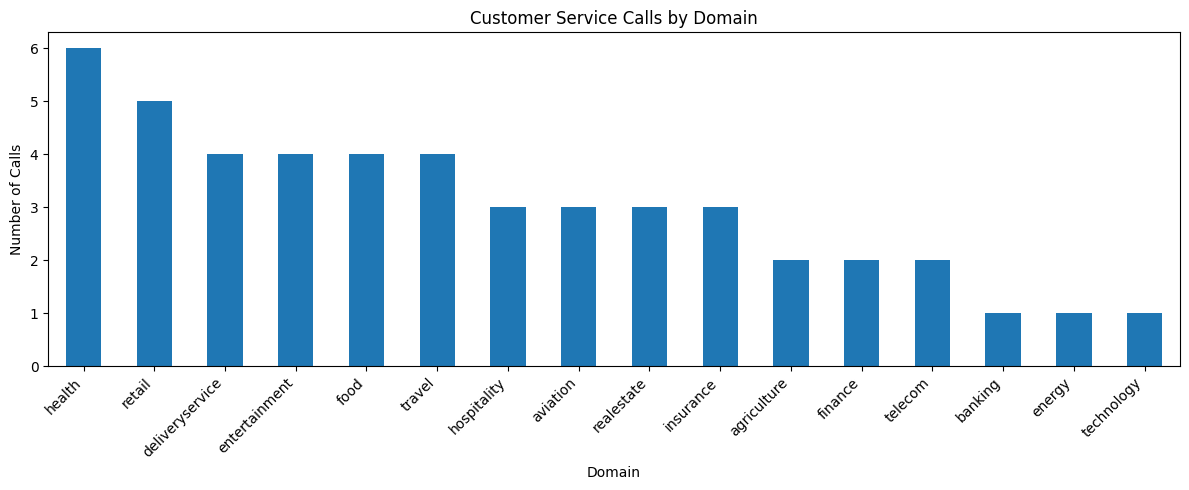

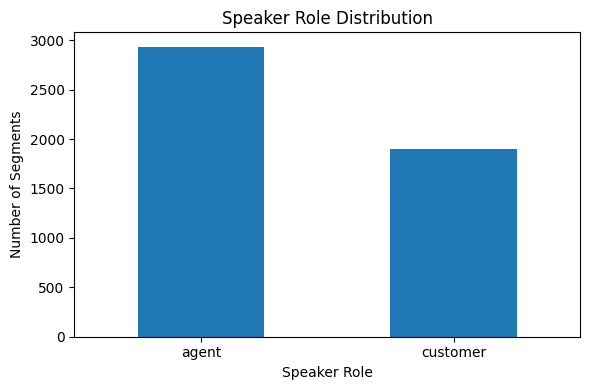

In [38]:
# 🔵 مرة واحدة (بناء) | B13 | توازن المجالات والمتحدثين
import matplotlib.pyplot as plt

# 1. Calls per domain
domain_calls = (
    general_df["domain"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Calls per domain:")
display(domain_calls)

# 2. Segments per domain
domain_segments = (
    general_segments_df["domain"]
    .value_counts()
    .sort_values(ascending=False)
)

print("\nSegments per domain:")
display(domain_segments)

# 3. Speaker roles
role_counts = (
    general_segments_df["role"]
    .value_counts()
)

role_percent = (
    general_segments_df["role"]
    .value_counts(normalize=True) * 100
)

role_summary = pd.DataFrame({
    "count": role_counts,
    "percentage": role_percent.round(2)
})

print("\nSpeaker role distribution:")
display(role_summary)

# 4. Speaker roles by domain
domain_role_table = pd.crosstab(
    general_segments_df["domain"],
    general_segments_df["role"]
)

print("\nSpeaker roles by domain:")
display(domain_role_table)

# 5. Domain distribution chart
plt.figure(figsize=(12, 5))
domain_calls.plot(kind="bar")
plt.title("Customer Service Calls by Domain")
plt.xlabel("Domain")
plt.ylabel("Number of Calls")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 6. Speaker distribution chart
plt.figure(figsize=(6, 4))
role_counts.plot(kind="bar")
plt.title("Speaker Role Distribution")
plt.xlabel("Speaker Role")
plt.ylabel("Number of Segments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
# 🔵 مرة واحدة (بناء) | B14 | حفظ تقارير جودة البيانات
from pathlib import Path

# Create reports directory
REPORT_DIR = Path("/content/CallSense_AI/reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Save validated segments
quality_segments.to_csv(
    REPORT_DIR / "general_quality_segments.csv",
    index=False
)

# Save overlapping segments
overlap_df[
    overlap_df["overlap_seconds"] > 0
].to_csv(
    REPORT_DIR / "overlapping_segments.csv",
    index=False
)

# Save domain distribution
domain_calls.rename(
    "call_count"
).to_csv(
    REPORT_DIR / "domain_distribution.csv"
)

# Save speaker distribution
role_summary.to_csv(
    REPORT_DIR / "speaker_distribution.csv"
)

# Save quality summary
summary.to_csv(
    REPORT_DIR / "quality_summary.csv"
)

print("All reports saved successfully!")
print("Reports directory:", REPORT_DIR)


## B-4 · هيكل المجلدات وتقسيم البيانات (Step 6)
ننشئ مجلدات المشروع، نحفظ الجداول المعالجة، ونقسم **حسب المكالمة** (وليس حسب المقطع) حتى لا تتسرب مقاطع نفس المكالمة بين التدريب والاختبار. الخلية الأخيرة تتحقق من عدم وجود تسرب.

In [ ]:
# 🔵 مرة واحدة (بناء) | B15 | إنشاء مجلدات المشروع
from pathlib import Path

# Main project directory
PROJECT_DIR = Path("/content/CallSense_AI")

# Project folders
folders = [
    "data/raw",
    "data/processed",
    "data/splits",
    "reports",
    "models/speaker_role",
    "models/intent_classifier",
    "models/asr",
    "outputs/transcripts",
    "outputs/summaries",
    "outputs/predictions",
    "evaluation",
    "app"
]

# Create missing folders without deleting existing files
for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("NABRA AI project structure ready!")

for folder in folders:
    print("✓", PROJECT_DIR / folder)


In [ ]:
# 🔵 مرة واحدة (بناء) | B16 | حفظ البيانات المعالجة
# Save processed datasets

PROCESSED_DIR = PROJECT_DIR / "data/processed"

# Call-level information
general_df.drop(
    columns=["segments"],
    errors="ignore"
).to_csv(
    PROCESSED_DIR / "general_calls.csv",
    index=False
)

# All extracted speech segments
general_segments_df.to_csv(
    PROCESSED_DIR / "general_segments.csv",
    index=False
)

# Validated segments with quality flags
quality_segments.to_csv(
    PROCESSED_DIR / "validated_segments.csv",
    index=False
)

print("Processed datasets saved successfully!")

for file in sorted(PROCESSED_DIR.glob("*.csv")):
    print(file.name, ":", round(
        file.stat().st_size / 1024, 2
    ), "KB")

print("\nTotal calls:", len(general_df))
print("Total segments:", len(general_segments_df))


In [ ]:
from pathlib import Path
import shutil

src = Path("/content/CallSense_AI")
dst = Path("/content/drive/MyDrive/CallSense_AI/checkpoint")

for folder in ["reports", "data/processed"]:
    shutil.copytree(
        src / folder,
        dst / folder,
        dirs_exist_ok=True
    )

print("✅ Checkpoint saved to Drive")

In [43]:
# 🔵 مرة واحدة (بناء) | B17 | تقسيم المكالمات: تدريب / تحقق / اختبار
import pandas as pd
from sklearn.model_selection import train_test_split

# Step 6.3 - Call-Level Dataset Splitting

# Use validated segments
df = quality_segments.copy()

# Get unique call IDs
call_ids = df["file_name"].unique()

# First split: 34 train calls, 14 remaining calls
train_calls, remaining_calls = train_test_split(
    call_ids,
    train_size=34,
    random_state=42,
    shuffle=True
)

# Second split: 7 validation and 7 test calls
val_calls, test_calls = train_test_split(
    remaining_calls,
    test_size=7,
    random_state=42,
    shuffle=True
)

# Assign split labels to every segment
df["split"] = "unassigned"

df.loc[
    df["file_name"].isin(train_calls), "split"
] = "train"

df.loc[
    df["file_name"].isin(val_calls), "split"
] = "validation"

df.loc[
    df["file_name"].isin(test_calls), "split"
] = "test"

# Check results
print("Calls per split:")
display(
    df.groupby("split")["file_name"].nunique()
)

print("\nSegments per split:")
display(df["split"].value_counts())

# Check that no call appears in multiple splits
leakage = df.groupby("file_name")["split"].nunique()

assert (leakage == 1).all(), "Data leakage detected!"

print("\nCall-level data leakage: NONE")

# Save split datasets
SPLIT_DIR = PROJECT_DIR / "data/splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

for split_name in ["train", "validation", "test"]:
    split_df = df[df["split"] == split_name].copy()

    split_df.to_csv(
        SPLIT_DIR / f"{split_name}.csv",
        index=False
    )

print("\nDataset splits saved successfully!")


Calls per split:


split
test           7
train         34
validation     7
Name: file_name, dtype: int64


Segments per split:


split
train         3287
validation     822
test           723
Name: count, dtype: int64


Call-level data leakage: NONE

Dataset splits saved successfully!


# الجزء C — نموذج تحديد المتحدث: Agent أو Customer (Step 7)  🔵 مرة واحدة

**ايش يسوي؟** يدرّب نموذجاً يقرأ جملة ويقرر هل قالها موظف خدمة العملاء (Agent) أو العميل (Customer). نبدأ بنموذج بسيط (TF-IDF + Logistic Regression) كخط أساس، ثم نضبط **DistilBERT** ونقارن بينهما.

**ينتج:** `models/speaker_role/distilbert_final` ← **هذا أهم ملف في المشروع**، وتحتاجه اللوحة.
**الوقت:** التدريب نفسه (`C12`) هو الأطول، وعلى T4 يأخذ بضع دقائق.

## C-1 · النموذج الأساسي (Baseline)

In [ ]:
# 🔵 مرة واحدة (بناء) | C1 | تحميل بيانات تصنيف المتحدث
import pandas as pd
from pathlib import Path

# Step 7.1 - Load and Prepare Data

SPLIT_DIR = Path("/content/CallSense_AI/data/splits")

# Load saved datasets
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

# Prepare text and labels
def prepare_role_data(df):
    df = df.copy()

    df["text"] = df["text"].fillna("").astype(str)
    df["role"] = df["role"].astype(str).str.lower().str.strip()

    # Keep only valid labels and non-empty text
    df = df[
        df["role"].isin(["agent", "customer"])
        & df["text"].str.strip().ne("")
    ].copy()

    return df

train_df = prepare_role_data(train_df)
val_df = prepare_role_data(val_df)
test_df = prepare_role_data(test_df)

# Check dataset sizes
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining role distribution:")
display(train_df["role"].value_counts())

print("\nValidation role distribution:")
display(val_df["role"].value_counts())

print("\nTesting role distribution:")
display(test_df["role"].value_counts())

print("\nSample records:")
display(train_df[["text", "role", "domain"]].head())


In [ ]:
# 🔵 مرة واحدة (بناء) | C2 | تدريب النموذج الأساسي (TF-IDF)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create baseline model
baseline_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

# Train only on training data
baseline_model.fit(
    train_df["text"],
    train_df["role"]
)

# Predict validation data
val_predictions = baseline_model.predict(
    val_df["text"]
)

# Evaluate
print("Validation Accuracy:",
      round(
          accuracy_score(
              val_df["role"],
              val_predictions
          ), 4
      ))

print("\nClassification Report:")
print(
    classification_report(
        val_df["role"],
        val_predictions,
        labels=["agent", "customer"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
display(
    pd.DataFrame(
        confusion_matrix(
            val_df["role"],
            val_predictions,
            labels=["agent", "customer"]
        ),
        index=["Actual Agent", "Actual Customer"],
        columns=["Predicted Agent", "Predicted Customer"]
    )
)


In [ ]:
# ⚪ اختيارية | C3 | تقييم النموذج الأساسي
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Step 7.3 - Baseline Evaluation
# Use the already trained baseline_model

datasets = {
    "Training": train_df,
    "Validation": val_df,
    "Testing": test_df
}

results = []

for name, data in datasets.items():

    X = data["text"]
    y_true = data["role"]

    # Predict using the trained baseline model
    y_pred = baseline_model.predict(X)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Dataset": name,
        "Samples": len(data),
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-Score": round(f1, 4)
    })

    print("=" * 60)
    print(f"{name.upper()} RESULTS")
    print("=" * 60)

    print(classification_report(
        y_true,
        y_pred,
        labels=["agent", "customer"],
        zero_division=0
    ))

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=["agent", "customer"]
    )

    display(pd.DataFrame(
        cm,
        index=["Actual Agent", "Actual Customer"],
        columns=["Predicted Agent", "Predicted Customer"]
    ))

# Comparison table
results_df = pd.DataFrame(results)

print("\nBASELINE MODEL COMPARISON")
display(results_df)

# Comparison chart
ax = results_df.set_index("Dataset")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Baseline Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Dataset")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## C-2 · تجهيز وضبط DistilBERT

In [ ]:
# ⚪ اختيارية | C4 | فحص الإصدارات والـ GPU
import torch
import datasets
import transformers

print("PyTorch:", torch.__version__)
print("Datasets:", datasets.__version__)
print("Transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

In [ ]:
# ⚪ اختيارية | C5 | فحص ملفات التدريب
from pathlib import Path

SPLIT_DIR = Path("/content/CallSense_AI/data/splits")

for name in ["train.csv", "validation.csv", "test.csv"]:
    print(name, (SPLIT_DIR / name).exists())

In [ ]:
# 🔵 مرة واحدة (بناء) | C6 | استيراد المكتبات وفحص الـ GPU
import os
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
# 🔵 مرة واحدة (بناء) | C7 | تحميل بيانات التدريب والتحقق
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/CallSense_AI")
SPLIT_DIR = PROJECT_DIR / "data/splits"

# Load datasets
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

# Clean text and role labels
def prepare_data(df):
    df = df.copy()

    df["text"] = df["text"].fillna("").astype(str)
    df["role"] = df["role"].astype(str).str.lower().str.strip()

    df = df[
        df["role"].isin(["agent", "customer"])
        & df["text"].str.strip().ne("")
    ].copy()

    return df

train_df = prepare_data(train_df)
val_df = prepare_data(val_df)
test_df = prepare_data(test_df)

# Convert role labels to numeric IDs
label2id = {
    "agent": 0,
    "customer": 1
}

id2label = {
    0: "agent",
    1: "customer"
}

train_df["label"] = train_df["role"].map(label2id)
val_df["label"] = val_df["role"].map(label2id)
test_df["label"] = test_df["role"].map(label2id)

# Display dataset sizes
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining samples preview:")
display(train_df[["text", "role", "label"]].head())


In [ ]:
# 🔵 مرة واحدة (بناء) | C8 | Tokenization
from datasets import Dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

MODEL_NAME = "distilbert-base-uncased"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Convert Pandas DataFrames to Hugging Face datasets
train_dataset = Dataset.from_pandas(
    train_df[["text", "label"]],
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df[["text", "label"]],
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df[["text", "label"]],
    preserve_index=False
)

# Tokenization function
def tokenize_function(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

# Apply tokenization
train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

# Remove original text column
train_dataset = train_dataset.remove_columns(["text"])
val_dataset = val_dataset.remove_columns(["text"])
test_dataset = test_dataset.remove_columns(["text"])

# Dynamic padding
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Tokenization completed!")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))


In [ ]:
# 🔵 مرة واحدة (بناء) | C9 | تحميل DistilBERT
from transformers import AutoModelForSequenceClassification

MODEL_NAME = "distilbert-base-uncased"

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    label2id=label2id,
    id2label=id2label
)

print("DistilBERT model loaded successfully!")


In [ ]:
# 🔵 مرة واحدة (بناء) | C10 | دالة قياس الأداء
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Evaluation metrics ready!")


In [ ]:
# 🔵 مرة واحدة (بناء) | C11 | إعدادات التدريب
import torch
from pathlib import Path
from transformers import TrainingArguments

PROJECT_DIR = Path("/content/CallSense_AI")

OUTPUT_DIR = (
    PROJECT_DIR / "models/speaker_role/distilbert"
)

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR),

    num_train_epochs=5,
    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    save_total_limit=2,

    logging_strategy="steps",
    logging_steps=25,

    report_to="none",

    fp16=torch.cuda.is_available(),
    seed=42
)

print("Training configuration ready!")


In [ ]:
# 🔵 مرة واحدة (بناء) | C12 | تدريب DistilBERT (أطول خلية في هذا الجزء)
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    processing_class=tokenizer,
    data_collator=data_collator,

    compute_metrics=compute_metrics
)

train_result = trainer.train()

print("DistilBERT training completed!")


## C-3 · تقييم DistilBERT وحفظه

In [ ]:
# ⚪ اختيارية | C13 | منحنيات التدريب
import pandas as pd
import matplotlib.pyplot as plt

# Get training history
history = pd.DataFrame(trainer.state.log_history)

train_logs = history.dropna(subset=["loss"])
val_logs = history.dropna(subset=["eval_loss"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Training and Validation Loss
axes[0].plot(
    train_logs["epoch"],
    train_logs["loss"],
    label="Training Loss"
)

axes[0].plot(
    val_logs["epoch"],
    val_logs["eval_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("DistilBERT - Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Plot 2: Validation Accuracy and F1
axes[1].plot(
    val_logs["epoch"],
    val_logs["eval_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

axes[1].plot(
    val_logs["epoch"],
    val_logs["eval_f1"],
    marker="s",
    label="Validation Macro F1"
)

axes[1].set_title("DistilBERT - Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
# 🔵 مرة واحدة (بناء) | C14 | التقييم النهائي على بيانات الاختبار
import numpy as np
from sklearn.metrics import classification_report

# Evaluate on unseen test data
test_metrics = trainer.evaluate(
    eval_dataset=test_dataset,
    metric_key_prefix="test"
)

test_output = trainer.predict(test_dataset)

test_predictions = np.argmax(
    test_output.predictions,
    axis=-1
)

print("=== DistilBERT Final Test Results ===")
print(f"Accuracy: {test_metrics['test_accuracy']:.4f}")
print(f"Precision: {test_metrics['test_precision']:.4f}")
print(f"Recall: {test_metrics['test_recall']:.4f}")
print(f"Macro F1: {test_metrics['test_f1']:.4f}")

print("\nClassification Report:")
print(classification_report(
    test_df["label"],
    test_predictions,
    labels=[0, 1],
    target_names=["Agent", "Customer"],
    zero_division=0
))


In [ ]:
# ⚪ اختيارية | C15 | مصفوفة الالتباس
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    test_df["label"],
    test_predictions,
    labels=[0, 1],
    display_labels=["Agent", "Customer"],
    cmap="Blues",
    values_format="d"
)

plt.title("DistilBERT - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
# 🔵 مرة واحدة (بناء) | C16 | مقارنة النموذج الأساسي مع DistilBERT
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

# Baseline numbers are computed from the trained baseline_model (Step 7.2), not typed by hand.
base_pred = baseline_model.predict(test_df["text"])

comparison = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Accuracy": accuracy_score(test_df["role"], base_pred),
        "Macro F1": f1_score(test_df["role"], base_pred, average="macro")
    },
    {
        "Model": "DistilBERT",
        "Accuracy": test_metrics["test_accuracy"],
        "Macro F1": test_metrics["test_f1"]
    }
])

display(comparison.round(4))

comparison.set_index("Model").plot(kind="bar", figsize=(9, 5), rot=0)

plt.title("Speaker Role Classification - Test Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 🔵 مرة واحدة (بناء) | C17 | حفظ نموذج DistilBERT ونتائجه
from pathlib import Path

PROJECT_DIR = Path("/content/CallSense_AI")

MODEL_DIR = PROJECT_DIR / "models/speaker_role/distilbert_final"
EVAL_DIR = PROJECT_DIR / "evaluation"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

# Save trained model
trainer.save_model(str(MODEL_DIR))
tokenizer.save_pretrained(str(MODEL_DIR))

# Save comparison and test predictions
comparison.to_csv(
    EVAL_DIR / "baseline_vs_distilbert.csv",
    index=False
)

test_results = test_df.copy()
test_results["predicted_label"] = test_predictions
test_results["predicted_role"] = [
    id2label[int(i)] for i in test_predictions
]

test_results.to_csv(
    EVAL_DIR / "distilbert_test_predictions.csv",
    index=False
)

print("Model saved:", MODEL_DIR)
print("Evaluation results saved:", EVAL_DIR)


### 💾 نقطة حفظ 1 (جديدة)
تنسخ المشروع إلى Drive حتى لا يضيع التدريب لو انقطع Colab. قبل هذا التعديل كانت النسخة الاحتياطية الوحيدة تُحفظ في آخر الدفتر (`I5`).

In [110]:
# 🔵 مرة واحدة (بناء) | C18 | 💾 نقطة حفظ 1 — نسخة من المشروع إلى Drive
import shutil
from pathlib import Path

# Copies the current project state to Google Drive. Safe to run more than once.
BACKUP_DIR.mkdir(parents=True, exist_ok=True)
for rel in ["models", "data/splits", "data/processed", "evaluation", "outputs", "reports", "app"]:
    src = PROJECT_DIR / rel
    if src.exists():
        shutil.copytree(src, BACKUP_DIR / rel, dirs_exist_ok=True)
print("Checkpoint saved to Drive:", BACKUP_DIR)


Checkpoint saved to Drive: /content/drive/MyDrive/CallSense_AI/project_backup


# الجزء D — تحويل الصوت إلى نص: Whisper (Step 8)  🔵 مرة واحدة

**ايش يسوي؟** يفرّغ مكالمات الاختبار السبع بنموذج `Whisper small.en`، ثم يقارن النص الناتج بالنص الحقيقي ويحسب **WER** (نسبة الكلمات الخاطئة) و**CER** (نسبة الحروف الخاطئة).

**ينتج:** تفريغ كل مكالمة في `outputs/transcripts/` وملخص التقييم في `evaluation/`.
**ملاحظة:** `D3` و`D4` تجربة على مكالمة واحدة فقط، تقدر تتخطاهما **معاً**.

In [45]:
# 🔵 مرة واحدة (بناء) | D1 | تحميل Whisper
import whisper
import torch
from pathlib import Path

PROJECT_DIR = Path("/content/CallSense_AI")

device = "cuda" if torch.cuda.is_available() else "cpu"

whisper_model = whisper.load_model(
    "small.en",
    device=device
)

print("Whisper loaded successfully!")
print("Device:", device)


100%|███████████████████████████████████████| 461M/461M [00:06<00:00, 77.2MiB/s]


Whisper loaded successfully!
Device: cuda


In [46]:
# 🔵 مرة واحدة (بناء) | D2 | اختيار مكالمات الاختبار
import pandas as pd

TEST_PATH = PROJECT_DIR / "data/splits/test.csv"
RAW_DIR = PROJECT_DIR / "data/raw"

test_df = pd.read_csv(TEST_PATH)

# Unique test calls
test_calls = sorted(
    test_df["file_name"].dropna().unique()
)

# Find the matching WAV files
test_audio_files = []

for call in test_calls:
    name = Path(call).name
    matches = list(RAW_DIR.rglob(name))

    if matches:
        test_audio_files.append(matches[0])
    else:
        print("Missing:", name)

print("Test calls:", len(test_calls))
print("Matched audio:", len(test_audio_files))

for file in test_audio_files:
    print(file.name)


Test calls: 7
Matched audio: 7
en_AU_Aviation_1592663.wav
en_AU_Aviation_1593397.wav
en_AU_DeliveryService_1586330.wav
en_AU_Health_1592677.wav
en_AU_Health_1593611.wav
en_AU_Hospitality_1585411.wav
en_AU_Retail2_1586372.wav


In [ ]:
# ⚪ اختيارية | D3 | تجربة تفريغ مكالمة واحدة (تُشغَّل مع D4)
assert test_audio_files, "No test audio files found."

audio_path = test_audio_files[0]

print("Processing:", audio_path.name)

result = whisper_model.transcribe(
    str(audio_path),
    language="en",
    task="transcribe",
    fp16=(device == "cuda")
)

print("\n=== Whisper Transcript ===")
print(result["text"])


In [ ]:
# ⚪ اختيارية | D4 | حفظ تفريغ المكالمة الواحدة (يحتاج D3)
OUTPUT_DIR = PROJECT_DIR / "outputs/transcripts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

whisper_df = pd.DataFrame([
    {
        "file_name": audio_path.name,
        "start": segment["start"],
        "end": segment["end"],
        "text": segment["text"].strip()
    }
    for segment in result["segments"]
])

display(whisper_df.head(10))

output_path = OUTPUT_DIR / (
    audio_path.stem + "_whisper.csv"
)

whisper_df.to_csv(output_path, index=False)

print("Saved:", output_path)


In [ ]:
# 🔵 مرة واحدة (بناء) | D5 | تفريغ مكالمات الاختبار السبع
import json

# Make this cell independent of D3/D4 (they are optional): set the transcripts folder here.
OUTPUT_DIR = PROJECT_DIR / "outputs/transcripts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for i, path in enumerate(test_audio_files, start=1):

    csv_path = OUTPUT_DIR / (
        path.stem + "_whisper.csv"
    )

    if csv_path.exists():
        print(f"[{i}] Already processed: {path.name}")
        continue

    print(f"[{i}/{len(test_audio_files)}] {path.name}")

    result = whisper_model.transcribe(
        str(path),
        language="en",
        task="transcribe",
        fp16=(device == "cuda")
    )

    segments_df = pd.DataFrame([
        {
            "file_name": path.name,
            "start": s["start"],
            "end": s["end"],
            "text": s["text"].strip()
        }
        for s in result["segments"]
    ])

    segments_df.to_csv(csv_path, index=False)

    print("Saved:", csv_path.name)

print("Whisper test transcription completed!")


In [ ]:
# 🔵 مرة واحدة (بناء) | D6 | تجهيز النصوص المرجعية
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/CallSense_AI")

test_df = pd.read_csv(
    PROJECT_DIR / "data/splits/test.csv"
)

reference_df = (
    test_df
    .sort_values(["file_name", "start", "end"])
    .groupby("file_name", as_index=False)
    .agg(reference_text=(
        "text",
        lambda x: " ".join(x.dropna().astype(str))
    ))
)

reference_df["audio_name"] = (
    reference_df["file_name"]
    .apply(lambda x: Path(x).name)
)

print("Reference calls:", len(reference_df))
display(reference_df[["audio_name", "reference_text"]].head())


In [ ]:
# ⚪ اختيارية | D7 | نسخ ملفات التفريغ إلى مجلدها الصحيح (علاج احتياطي)
from pathlib import Path
import shutil

PROJECT_DIR = Path("/content/CallSense_AI")
TRANSCRIPT_DIR = PROJECT_DIR / "outputs/transcripts"
TRANSCRIPT_DIR.mkdir(parents=True, exist_ok=True)

# Find Whisper transcripts
files = list(PROJECT_DIR.rglob("*_whisper.csv"))

print("Found files:", len(files))

# Copy to the correct folder
for src in files:
    dst = TRANSCRIPT_DIR / src.name

    if src != dst and not dst.exists():
        shutil.copy2(src, dst)

print("Whisper transcripts ready:",
      len(list(TRANSCRIPT_DIR.glob("*_whisper.csv"))))

# Correct the output path for future cells
OUTPUT_DIR = TRANSCRIPT_DIR

In [ ]:
# 🔵 مرة واحدة (بناء) | D8 | قراءة تفريغ Whisper
TRANSCRIPT_DIR = PROJECT_DIR / "outputs/transcripts"

prediction_rows = []

for file in sorted(TRANSCRIPT_DIR.glob("*_whisper.csv")):
    df = pd.read_csv(file)

    if "start" in df.columns:
        df = df.sort_values("start")

    transcript = " ".join(
        df["text"].dropna().astype(str)
    )

    prediction_rows.append({
        "audio_name": file.name.replace("_whisper.csv", ".wav"),
        "whisper_text": transcript
    })

prediction_df = pd.DataFrame(
    prediction_rows,
    columns=["audio_name", "whisper_text"]
)

print("Whisper transcripts:", len(prediction_df))
display(prediction_df.head())


In [52]:
# 🔵 مرة واحدة (بناء) | D9 | حساب WER و CER
from jiwer import wer, cer
import re

def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

asr_eval = reference_df.merge(
    prediction_df,
    on="audio_name",
    how="inner"
)

assert not asr_eval.empty, "No matching reference and Whisper transcripts."

asr_eval["reference_clean"] = (
    asr_eval["reference_text"].apply(normalize_text)
)

asr_eval["whisper_clean"] = (
    asr_eval["whisper_text"].apply(normalize_text)
)

asr_eval["WER"] = asr_eval.apply(
    lambda row: wer(
        row["reference_clean"],
        row["whisper_clean"]
    ),
    axis=1
)

asr_eval["CER"] = asr_eval.apply(
    lambda row: cer(
        row["reference_clean"],
        row["whisper_clean"]
    ),
    axis=1
)

print("Evaluated calls:", len(asr_eval))

display(
    asr_eval[["audio_name", "WER", "CER"]].round(4)
)


Evaluated calls: 7


                          audio_name     WER     CER
0         en_AU_Aviation_1592663.wav  0.1509  0.1143
1         en_AU_Aviation_1593397.wav  0.1668  0.1316
2  en_AU_DeliveryService_1586330.wav  0.1560  0.1218
3           en_AU_Health_1592677.wav  0.0975  0.0604
4           en_AU_Health_1593611.wav  0.1159  0.0736
5      en_AU_Hospitality_1585411.wav  0.1613  0.1096
6          en_AU_Retail2_1586372.wav  0.1702  0.1296

In [53]:
# 🔵 مرة واحدة (بناء) | D10 | النتيجة الإجمالية لـ Whisper
overall_wer = wer(
    asr_eval["reference_clean"].tolist(),
    asr_eval["whisper_clean"].tolist()
)

overall_cer = cer(
    asr_eval["reference_clean"].tolist(),
    asr_eval["whisper_clean"].tolist()
)

print("=== Whisper ASR Evaluation ===")
print(f"Evaluated Calls: {len(asr_eval)}")
print(f"Overall WER: {overall_wer:.4f}")
print(f"Overall CER: {overall_cer:.4f}")


=== Whisper ASR Evaluation ===
Evaluated Calls: 7
Overall WER: 0.1400
Overall CER: 0.0998


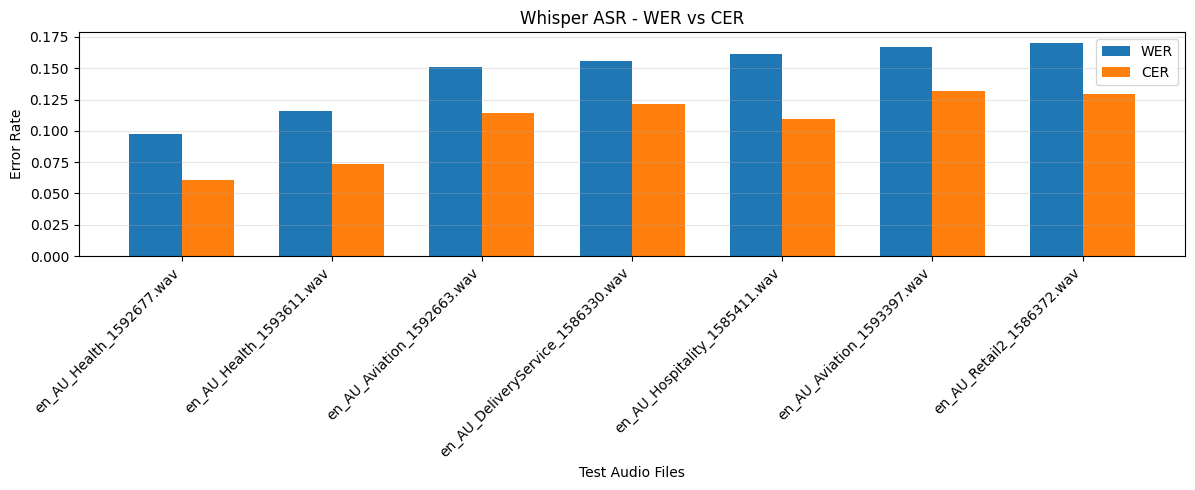

In [54]:
# ⚪ اختيارية | D11 | رسم نتائج Whisper
import matplotlib.pyplot as plt
import numpy as np

plot_df = asr_eval.sort_values("WER").copy()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_df["WER"],
    width,
    label="WER"
)

plt.bar(
    x + width / 2,
    plot_df["CER"],
    width,
    label="CER"
)

plt.xticks(
    x,
    plot_df["audio_name"],
    rotation=45,
    ha="right"
)

plt.xlabel("Test Audio Files")
plt.ylabel("Error Rate")
plt.title("Whisper ASR - WER vs CER")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [55]:
# 🔵 مرة واحدة (بناء) | D12 | حفظ تقييم Whisper
EVAL_DIR = PROJECT_DIR / "evaluation"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

asr_eval.to_csv(
    EVAL_DIR / "whisper_test_evaluation.csv",
    index=False
)

summary_df = pd.DataFrame([{
    "Model": "Whisper small.en",
    "Evaluated Calls": len(asr_eval),
    "Overall WER": overall_wer,
    "Overall CER": overall_cer
}])

summary_df.to_csv(
    EVAL_DIR / "whisper_summary_metrics.csv",
    index=False
)

print("Whisper evaluation saved successfully!")


Whisper evaluation saved successfully!


# الجزء E — تحديد المتحدثين: Pyannote + تقييم المسار (Step 9)  🔵 مرة واحدة

**ايش يسوي؟** يشغّل Pyannote ليعرف **من تكلم ومتى**، يربط ذلك بنص Whisper، ويستخدم DistilBERT لتسمية كل متحدث (Agent أو Customer). بعدها يقارن النتيجة بالحقيقة على المكالمات السبع ويرسم الدقة.

**شرط مهم:** لازم تقبل شروط نموذج Pyannote بنفس حساب Hugging Face الذي أخذت منه الـ token:
`huggingface.co/pyannote/speaker-diarization-community-1` ← زر **Agree and access**. خلية `E1` تتحقق من ذلك.

In [ ]:
# 🔵 مرة واحدة (بناء) | E1 | التحقق من صلاحية الوصول إلى Pyannote
from google.colab import userdata
from huggingface_hub import HfApi, hf_hub_download

# قراءة الرمز وإزالة المسافات والأسطر المخفية
HF_TOKEN = "".join(userdata.get("HF_TOKEN").split())

assert HF_TOKEN.startswith("hf_"), "Invalid token format"

print("✅ Token format fixed")

# اختبار تسجيل الدخول
user = HfApi().whoami(token=HF_TOKEN)
print("✅ Hugging Face login successful!")

# اختبار الوصول إلى Pyannote
hf_hub_download(
    repo_id="pyannote/speaker-diarization-community-1",
    filename="config.yaml",
    token=HF_TOKEN
)

print("✅ Community-1 access successful!")

In [ ]:
# 🔵 مرة واحدة (بناء) | E2 | تحميل Pyannote
import torch
from pathlib import Path
from pyannote.audio import Pipeline

PROJECT_DIR = Path("/content/CallSense_AI")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

diarization_pipeline = Pipeline.from_pretrained(
    "pyannote/speaker-diarization-community-1",
    token=HF_TOKEN
)

diarization_pipeline.to(device)

print("Diarization model loaded successfully!")
print("Device:", device)


In [ ]:
from pathlib import Path

for f in Path("/content").glob("*.zip"):
    print(f.name, round(f.stat().st_size / 1024**2, 1), "MB")

In [ ]:
from pathlib import Path
import zipfile

drive = Path("/content/drive/MyDrive")

# البحث في المجلد الرئيسي ومجلد المشروع
archives = []
for folder in [drive, drive / "CallSense_AI"]:
    if folder.exists():
        archives += list(folder.glob("*.zip"))

print("ZIP files found:", len(archives))

for p in archives:
    print("\n📦", p.name)
    print("Size:", round(p.stat().st_size / 1024**2, 1), "MB")

    if not zipfile.is_zipfile(p):
        print("❌ ZIP incomplete or invalid")
        continue

    print("✅ ZIP is valid")

    with zipfile.ZipFile(p) as z:
        models = [
            n for n in z.namelist()
            if n.endswith((
                "model.safetensors",
                "pytorch_model.bin"
            ))
        ]

        print("Model weights found:", len(models))

        for name in models[:10]:
            print("✅", name)

In [ ]:
from pathlib import Path
from transformers import (
    AutoConfig,
    AutoTokenizer,
    AutoModelForSequenceClassification
)
import zipfile
import shutil
import json

archive = Path(
    "/content/drive/MyDrive/CallSense_AI/"
    "CallSense_AI-20261101T181133Z-1-001.zip"
)

# المسار البديل إذا كان ZIP في جذر MyDrive
if not archive.exists():
    archive = Path("/content/drive/MyDrive") / archive.name

assert archive.exists(), "ZIP file not found"

target = Path(
    "/content/CallSense_AI/models/speaker_role/distilbert_final"
)
target.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(archive) as z:
    names = z.namelist()

    checkpoints = sorted(
        {
            n.rsplit("/", 1)[0]
            for n in names
            if n.endswith("/model.safetensors")
            and "/speaker_role/distilbert/checkpoint-" in n
        },
        key=lambda p: int(p.rsplit("checkpoint-", 1)[-1])
    )

    assert checkpoints, "No model checkpoint found"

    selected = checkpoints[-1]

    # اختيار أفضل checkpoint إذا سجل التدريب متوفر
    state_path = selected + "/trainer_state.json"
    if state_path in names:
        state = json.loads(z.read(state_path))
        best = state.get("best_model_checkpoint")
        if best:
            for cp in checkpoints:
                if cp.endswith(best.rstrip("/").split("/")[-1]):
                    selected = cp
                    break

    print("Selected checkpoint:", selected)

    # استعادة الأوزان
    weight_name = selected + "/model.safetensors"

    with z.open(weight_name) as src:
        with open(target / "model.safetensors", "wb") as dst:
            shutil.copyfileobj(src, dst)

    # البحث عن إعدادات متوافقة داخل النسخة
    configs = [
        n for n in names
        if n.endswith("/config.json")
        and "speaker_role/distilbert" in n
    ]

    valid_config = None
    for name in configs:
        info = json.loads(z.read(name))
        if info.get("model_type") == "distilbert":
            valid_config = info
            break

# استخدام إعدادات النموذج الأصلي إذا لم تُحفظ
if valid_config:
    config = AutoConfig.for_model("distilbert", **{
        k: v for k, v in valid_config.items()
        if k != "model_type"
    })
    print("✅ Original compatible config found")
else:
    config = AutoConfig.from_pretrained(
        "distilbert-base-uncased",
        num_labels=2
    )
    print("⚠️ Reconstructed base configuration")

config.id2label = {0: "agent", 1: "customer"}
config.label2id = {"agent": 0, "customer": 1}
config.save_pretrained(target)

# استعادة الـ Tokenizer المستخدم في التدريب
tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)
tokenizer.save_pretrained(target)

# اختبار تحميل النموذج
model = AutoModelForSequenceClassification.from_pretrained(
    str(target)
)

print("\n✅ DistilBERT restored successfully!")
print("Labels:", model.config.id2label)
print("Model path:", target)

In [60]:
# 🔵 مرة واحدة (بناء) | E3 | تجهيز بيئة التقييم
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import json

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

PROJECT_DIR = Path("/content/CallSense_AI")
RAW_DIR = PROJECT_DIR / "data/raw"
TRANSCRIPT_DIR = PROJECT_DIR / "outputs/transcripts"
DIARIZATION_DIR = PROJECT_DIR / "outputs/diarization"
PREDICTION_DIR = PROJECT_DIR / "outputs/predictions"
EVAL_DIR = PROJECT_DIR / "evaluation/step_9_14"

for folder in [
    TRANSCRIPT_DIR,
    DIARIZATION_DIR,
    PREDICTION_DIR,
    EVAL_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

test_df = pd.read_csv(
    PROJECT_DIR / "data/splits/test.csv"
)

test_df["call_id"] = test_df["file_name"].apply(
    lambda x: Path(str(x)).stem
)

test_calls = sorted(test_df["call_id"].unique())

print("Test calls:", len(test_calls))
print("Reference segments:", len(test_df))

assert len(test_calls) == 7, (
    "Expected 7 test calls. Check test.csv."
)


Test calls: 7
Reference segments: 723


In [75]:
# 🔵 مرة واحدة (بناء) | E4 | تحميل النماذج الثلاثة
import whisper
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Whisper
if "whisper_model" not in globals():
    whisper_model = whisper.load_model(
        "small.en",
        device=str(device)
    )

# DistilBERT
MODEL_DIR = (
    PROJECT_DIR /
    "models/speaker_role/distilbert_final"
)

assert MODEL_DIR.exists(), "DistilBERT model not found."

role_tokenizer = AutoTokenizer.from_pretrained(
    str(MODEL_DIR)
)

role_model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_DIR)
).to(device)

role_model.eval()

# Pyannote: reuse the pipeline loaded in Step 9
assert "diarization_pipeline" in globals(), (
    "Run Step 9.4 to load Pyannote first."
)

diarization_pipeline.to(device)

print("All models ready!")
print("Device:", device)
print("Labels:", role_model.config.id2label)


All models ready!
Device: cuda
Labels: {0: 'agent', 1: 'customer'}


In [ ]:
# 🔵 مرة واحدة (بناء) | E5 | معالجة المكالمات السبع
from pyannote.audio import Pipeline

def find_audio(call_id):
    matches = list(RAW_DIR.rglob(call_id + ".wav"))
    if not matches:
        raise FileNotFoundError(
            f"Audio not found: {call_id}.wav"
        )
    return matches[0]


def run_whisper(audio_path):
    csv_path = (
        TRANSCRIPT_DIR /
        f"{audio_path.stem}_whisper.csv"
    )

    if csv_path.exists():
        return pd.read_csv(csv_path)

    result = whisper_model.transcribe(
        str(audio_path),
        language="en",
        task="transcribe",
        fp16=(device.type == "cuda")
    )

    df = pd.DataFrame([
        {
            "start": s["start"],
            "end": s["end"],
            "text": s["text"].strip()
        }
        for s in result["segments"]
    ])

    df.to_csv(csv_path, index=False)
    return df


def run_diarization(audio_path):
    csv_path = (
        DIARIZATION_DIR /
        f"{audio_path.stem}_diarization.csv"
    )

    if csv_path.exists():
        return pd.read_csv(csv_path)

    result = diarization_pipeline(
        str(audio_path),
        num_speakers=2
    )

    annotation = (
        result.speaker_diarization
        if hasattr(result, "speaker_diarization")
        else result
    )

    rows = [
        {
            "start": turn.start,
            "end": turn.end,
            "speaker": speaker
        }
        for turn, _, speaker
        in annotation.itertracks(yield_label=True)
    ]

    df = pd.DataFrame(
        rows,
        columns=["start", "end", "speaker"]
    )

    df.to_csv(csv_path, index=False)
    return df


call_data = {}

for i, call_id in enumerate(test_calls, 1):
    print(f"\n[{i}/7] Processing: {call_id}")

    audio_path = find_audio(call_id)

    wdf = run_whisper(audio_path)
    ddf = run_diarization(audio_path)

    call_data[call_id] = {
        "whisper": wdf,
        "diarization": ddf
    }

    print("Whisper segments:", len(wdf))
    print("Diarization segments:", len(ddf))

print("\nAll seven calls processed!")


In [77]:
# 🔵 مرة واحدة (بناء) | E6 | ربط المتحدثين وتوقع الأدوار
label2id = {
    str(label).lower(): int(idx)
    for label, idx
    in role_model.config.label2id.items()
}

assert "agent" in label2id, (
    f"Agent label missing: {label2id}"
)

agent_id = label2id["agent"]


def overlap_seconds(a_start, a_end, b_start, b_end):
    return max(
        0.0,
        min(a_end, b_end) - max(a_start, b_start)
    )


def assign_speaker(row, diar_df):
    scores = {}

    for speaker, group in diar_df.groupby("speaker"):
        scores[speaker] = sum(
            overlap_seconds(
                row["start"], row["end"],
                s["start"], s["end"]
            )
            for _, s in group.iterrows()
        )

    if not scores or max(scores.values()) <= 0:
        return "UNKNOWN"

    return max(scores, key=scores.get)


def predict_agent_probs(texts, batch_size=32):
    results = []

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        inputs = role_tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            logits = role_model(**inputs).logits
            probs = torch.softmax(logits, dim=-1)

        results.extend(
            probs[:, agent_id].cpu().tolist()
        )

    return results


all_predictions = []

for call_id, data in call_data.items():
    wdf = data["whisper"].copy()
    ddf = data["diarization"].copy()

    if wdf.empty or ddf.empty:
        print("Skipping empty call:", call_id)
        continue

    wdf["speaker"] = wdf.apply(
        lambda row: assign_speaker(row, ddf),
        axis=1
    )

    wdf["agent_probability"] = predict_agent_probs(
        wdf["text"].fillna("").astype(str).tolist()
    )

    valid_speakers = wdf[
        wdf["speaker"] != "UNKNOWN"
    ]

    scores = (
        valid_speakers
        .groupby("speaker")["agent_probability"]
        .mean()
        .sort_values(ascending=False)
    )

    if len(scores) == 2:
        role_map = {
            scores.index[0]: "agent",
            scores.index[1]: "customer"
        }
    else:
        print(
            "Review speaker count:",
            call_id,
            len(scores)
        )
        role_map = {}

    wdf["role"] = (
        wdf["speaker"]
        .map(role_map)
        .fillna("unknown")
    )

    wdf["call_id"] = call_id

    output_path = (
        PREDICTION_DIR /
        f"{call_id}_speaker_roles.csv"
    )

    wdf.to_csv(output_path, index=False)
    all_predictions.append(wdf)

assert all_predictions, "No predictions generated."

predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)

print("Total predicted segments:", len(predictions_df))
print("Predicted roles:")
print(predictions_df["role"].value_counts())


Total predicted segments: 724
Predicted roles:
role
agent       442
customer    269
unknown      13
Name: count, dtype: int64


In [78]:
# 🔵 مرة واحدة (بناء) | E7 | المقارنة مع الحقيقة المرجعية
def get_reference_role(row):
    reference = test_df[
        test_df["call_id"] == row["call_id"]
    ]

    scores = {}

    for role, group in reference.groupby("role"):
        scores[role] = sum(
            overlap_seconds(
                row["start"], row["end"],
                s["start"], s["end"]
            )
            for _, s in group.iterrows()
        )

    if not scores or max(scores.values()) <= 0:
        return "unknown"

    return max(scores, key=scores.get)


predictions_df["reference_role"] = (
    predictions_df.apply(
        get_reference_role,
        axis=1
    )
)

labels = ["agent", "customer"]

evaluated_df = predictions_df[
    predictions_df["reference_role"].isin(labels)
].copy()

# Keep unknown predictions as errors, not successes.
evaluated_df["role"] = (
    evaluated_df["role"]
    .fillna("unknown")
)

results = []

for call_id in test_calls:
    group = evaluated_df[
        evaluated_df["call_id"] == call_id
    ]

    total_pred = (
        predictions_df["call_id"] == call_id
    ).sum()

    if group.empty:
        results.append({
            "call_id": call_id,
            "total_segments": total_pred,
            "evaluated_segments": 0,
            "accuracy": np.nan,
            "macro_f1": np.nan
        })
        continue

    results.append({
        "call_id": call_id,
        "total_segments": total_pred,
        "evaluated_segments": len(group),
        "accuracy": accuracy_score(
            group["reference_role"],
            group["role"]
        ),
        "macro_f1": f1_score(
            group["reference_role"],
            group["role"],
            labels=labels,
            average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df)


                         call_id  total_segments  evaluated_segments  \
0         en_AU_Aviation_1592663             160                 160   
1         en_AU_Aviation_1593397              88                  77   
2  en_AU_DeliveryService_1586330              49                  49   
3           en_AU_Health_1592677             138                 138   
4           en_AU_Health_1593611              86                  85   
5      en_AU_Hospitality_1585411             125                 125   
6          en_AU_Retail2_1586372              78                  77   

   accuracy  macro_f1  
0  1.000000  1.000000  
1  0.883117  0.870540  
2  0.959184  0.888636  
3  0.985507  0.984974  
4  0.976471  0.974612  
5  0.992000  0.991867  
6  0.922078  0.918085  

In [79]:
# 🔵 مرة واحدة (بناء) | E8 | التقييم الإجمالي
assert not evaluated_df.empty, (
    "No evaluable segments found."
)

overall_accuracy = accuracy_score(
    evaluated_df["reference_role"],
    evaluated_df["role"]
)

overall_f1 = f1_score(
    evaluated_df["reference_role"],
    evaluated_df["role"],
    labels=labels,
    average="macro",
    zero_division=0
)

coverage = (
    len(evaluated_df) / len(predictions_df)
)

print("=== NABRA AI: 7-Call Evaluation ===")
print("Calls processed:", len(call_data))
print("Predicted segments:", len(predictions_df))
print("Evaluated segments:", len(evaluated_df))
print(f"Reference coverage: {coverage:.2%}")
print(f"Overall Accuracy: {overall_accuracy:.4f}")
print(f"Overall Macro F1: {overall_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    evaluated_df["reference_role"],
    evaluated_df["role"],
    labels=labels,
    zero_division=0
))


=== NABRA AI: 7-Call Evaluation ===
Calls processed: 7
Predicted segments: 724
Evaluated segments: 711
Reference coverage: 98.20%
Overall Accuracy: 0.9691
Overall Macro F1: 0.9674

Classification Report:
              precision    recall  f1-score   support

       agent       0.96      0.99      0.97       430
    customer       0.98      0.94      0.96       281

    accuracy                           0.97       711
   macro avg       0.97      0.96      0.97       711
weighted avg       0.97      0.97      0.97       711



In [ ]:
# ⚪ اختيارية | E9 | رسم الدقة لكل مكالمة
plt.figure(figsize=(12, 5))

bars = plt.bar(
    results_df["call_id"],
    results_df["accuracy"] * 100
)

plt.ylim(0, 110)
plt.ylabel("Accuracy (%)")
plt.xlabel("Test Call")
plt.title("NABRA AI - Speaker Role Accuracy per Call")
plt.xticks(rotation=65, ha="right")

for bar, value in zip(
    bars, results_df["accuracy"]
):
    if pd.notna(value):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f"{value:.1%}",
            ha="center",
            fontsize=9
        )

plt.tight_layout()
plt.savefig(
    EVAL_DIR / "accuracy_per_call.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


In [ ]:
# ⚪ اختيارية | E10 | رسم Macro F1 لكل مكالمة
plt.figure(figsize=(12, 5))

plt.bar(
    results_df["call_id"],
    results_df["macro_f1"] * 100
)

plt.ylim(0, 110)
plt.ylabel("Macro F1 (%)")
plt.xlabel("Test Call")
plt.title("NABRA AI - Macro F1 per Call")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()

plt.savefig(
    EVAL_DIR / "macro_f1_per_call.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


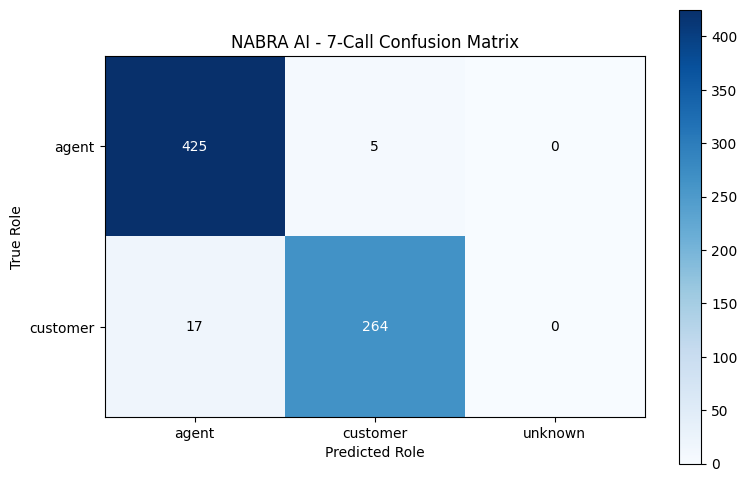

In [80]:
# 🔵 مرة واحدة (بناء) | E11 | مصفوفة الالتباس الإجمالية
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

true_labels = ["agent", "customer"]
pred_labels = ["agent", "customer", "unknown"]

cm = confusion_matrix(
    evaluated_df["reference_role"],
    evaluated_df["role"],
    labels=pred_labels
)[:2, :]

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(3), pred_labels)
ax.set_yticks(range(2), true_labels)

ax.set_xlabel("Predicted Role")
ax.set_ylabel("True Role")
ax.set_title("NABRA AI - 7-Call Confusion Matrix")

threshold = cm.max() / 2

for i in range(2):
    for j in range(3):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

fig.colorbar(im, ax=ax)
plt.tight_layout()

plt.savefig(
    EVAL_DIR / "overall_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


In [81]:
# 🔵 مرة واحدة (بناء) | E12 | حفظ نتائج التقييم
import json

EVAL_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    EVAL_DIR / "per_call_metrics.csv",
    index=False
)

predictions_df.to_csv(
    EVAL_DIR / "all_predictions.csv",
    index=False
)

summary = {
    "test_calls": len(test_calls),
    "predicted_segments": len(predictions_df),
    "evaluated_segments": len(evaluated_df),
    "coverage": round(float(coverage), 4),
    "accuracy": round(float(overall_accuracy), 4),
    "macro_f1": round(float(overall_f1), 4),
    "method": "Temporal-overlap role evaluation"
}

with open(
    EVAL_DIR / "evaluation_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=4)

print("Step 9.14 completed!")
print("Results saved to:", EVAL_DIR)
print("\nSaved files:")
for path in sorted(EVAL_DIR.iterdir()):
    print("-", path.name)


Step 9.14 completed!
Results saved to: /content/CallSense_AI/evaluation/step_9_14

Saved files:
- all_predictions.csv
- evaluation_summary.json
- overall_confusion_matrix.png
- per_call_metrics.csv


# الجزء F — تصنيف مجال المكالمة (Step 10)  🔵 مرة واحدة

**ايش يسوي؟** يحدد مجال كل مكالمة (توصيل، طيران…) من نصها، بنموذج بسيط TF-IDF + Logistic Regression.
**ملاحظة:** هذا الجزء مستقل؛ اللوحة والمسار الكامل لا يستخدمانه، لكنه جزء من تقييم المشروع.

In [ ]:
# 🔵 مرة واحدة (بناء) | F1 | تحميل بيانات المجال
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/CallSense_AI")
SPLIT_DIR = PROJECT_DIR / "data/splits"
DOMAIN_DIR = PROJECT_DIR / "models/domain_classifier"
EVAL_DIR = PROJECT_DIR / "evaluation/domain_classifier"

DOMAIN_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}: {len(df)} segments")
    print("Columns:", df.columns.tolist())
    print("Domains:")
    print(df["domain"].value_counts())


In [ ]:
# 🔵 مرة واحدة (بناء) | F2 | تجهيز نص كل مكالمة
def prepare_call_dataset(df):
    df = df.copy()

    required = ["file_name", "text", "domain"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    df["text"] = df["text"].fillna("").astype(str)
    df["domain"] = df["domain"].astype(str).str.lower().str.strip()

    # Preserve conversation order
    if "start" in df.columns:
        df = df.sort_values(["file_name", "start"])

    # Combine utterances into one document per call
    calls = (
        df.groupby("file_name", sort=False)
        .agg(
            text=("text", " ".join),
            domain=("domain", "first"),
            segments=("text", "size")
        )
        .reset_index()
    )

    calls = calls[calls["text"].str.strip().ne("")]

    # Verify one domain per call
    unique_domains = df.groupby("file_name")["domain"].nunique()
    assert unique_domains.max() == 1, (
        "A call has multiple domain labels."
    )

    return calls.reset_index(drop=True)

train_calls = prepare_call_dataset(train_df)
val_calls = prepare_call_dataset(val_df)
test_calls_domain = prepare_call_dataset(test_df)

# Ensure no call appears in multiple splits
train_ids = set(train_calls["file_name"])
val_ids = set(val_calls["file_name"])
test_ids = set(test_calls_domain["file_name"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("Train calls:", len(train_calls))
print("Validation calls:", len(val_calls))
print("Test calls:", len(test_calls_domain))

display(train_calls.head())


In [ ]:
# ⚪ اختيارية | F3 | رسم توزيع المجالات
domain_distribution = pd.concat(
    [
        train_calls.assign(split="Train"),
        val_calls.assign(split="Validation"),
        test_calls_domain.assign(split="Test")
    ],
    ignore_index=True
)

counts = pd.crosstab(
    domain_distribution["domain"],
    domain_distribution["split"]
)

counts = counts.reindex(
    columns=["Train", "Validation", "Test"],
    fill_value=0
)

display(counts)

ax = counts.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("NABRA AI - Domain Distribution by Split")
plt.xlabel("Domain")
plt.ylabel("Number of Calls")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    EVAL_DIR / "domain_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Important: identify classes missing from training
missing_train = counts.index[counts["Train"] == 0].tolist()
missing_test = counts.index[counts["Test"] == 0].tolist()

print("Domains absent from training:", missing_train)
print("Domains absent from test:", missing_test)

if missing_train:
    print(
        "WARNING: Some domains have no training examples. "
        "A supervised classifier cannot learn those classes."
    )


In [ ]:
# 🔵 مرة واحدة (بناء) | F4 | تدريب نموذج المجال
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import joblib

X_train = train_calls["text"]
y_train = train_calls["domain"]

X_val = val_calls["text"]
y_val = val_calls["domain"]

X_test = test_calls_domain["text"]
y_test = test_calls_domain["domain"]

assert y_train.nunique() >= 2, (
    "At least two training domains are required."
)

baseline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            stop_words="english",
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
])

baseline.fit(X_train, y_train)

val_pred = baseline.predict(X_val)
test_pred = baseline.predict(X_test)

print("=== Domain Classification Baseline ===")

print(
    "Validation Accuracy:",
    accuracy_score(y_val, val_pred)
)
print(
    "Validation Macro F1:",
    f1_score(y_val, val_pred, average="macro",
             zero_division=0)
)

print(
    "Test Accuracy:",
    accuracy_score(y_test, test_pred)
)
print(
    "Test Macro F1:",
    f1_score(y_test, test_pred, average="macro",
             zero_division=0)
)

print("\nTest Classification Report:")
print(
    classification_report(
        y_test, test_pred, zero_division=0
    )
)

joblib.dump(
    baseline,
    DOMAIN_DIR / "tfidf_logistic_regression.joblib"
)

print("\nBaseline model saved!")


In [ ]:
# ⚪ اختيارية | F5 | رسم نتائج نموذج المجال
from sklearn.metrics import ConfusionMatrixDisplay

metrics = {
    "Validation Accuracy": accuracy_score(y_val, val_pred),
    "Validation Macro F1": f1_score(
        y_val, val_pred, average="macro", zero_division=0
    ),
    "Test Accuracy": accuracy_score(y_test, test_pred),
    "Test Macro F1": f1_score(
        y_test, test_pred, average="macro", zero_division=0
    )
}

plt.figure(figsize=(10, 5))
bars = plt.bar(
    list(metrics.keys()),
    [v * 100 for v in metrics.values()]
)

plt.ylim(0, 110)
plt.ylabel("Score (%)")
plt.title("Domain Classification - TF-IDF Baseline")
plt.xticks(rotation=20)

for bar, value in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value:.1%}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    EVAL_DIR / "baseline_metrics.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

all_labels = sorted(set(y_train) | set(y_val) | set(y_test))

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    labels=all_labels,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax,
    colorbar=False
)

plt.title("Domain Classification - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    EVAL_DIR / "baseline_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


### 💾 نقطة حفظ 2 (جديدة)
نسخة ثانية إلى Drive بعد انتهاء الجزء الأول كله.

In [ ]:
# 🔵 مرة واحدة (بناء) | F6 | 💾 نقطة حفظ 2 — نسخة من المشروع إلى Drive
import shutil
from pathlib import Path

# Copies the current project state to Google Drive. Safe to run more than once.
BACKUP_DIR.mkdir(parents=True, exist_ok=True)
for rel in ["models", "data/splits", "data/processed", "evaluation", "outputs", "reports", "app"]:
    src = PROJECT_DIR / rel
    if src.exists():
        shutil.copytree(src, BACKUP_DIR / rel, dirs_exist_ok=True)
print("Checkpoint saved to Drive:", BACKUP_DIR)


## Step 11 — Qwen: الملخص وحالة الحل
تم نقل هذه الخطوة إلى **Step 12.6** بنفس الـ prompt بعد تحسينها (تقسيم المكالمات الطويلة، التحقق من الاقتباس، إعادة المحاولة عند فشل JSON)، وذلك لتجنب تحميل Qwen مرتين على نفس الـ GPU. (لا توجد خلايا لهذه الخطوة هنا ولا ملحق في هذا الملف، فتجاوزها.)

# الجزء الثاني — المسار الكامل واللوحة والتقييم النهائي  (G → I)

من هنا نجمع كل النماذج في مسار واحد: **Whisper ← Pyannote ← DistilBERT ← Qwen**. نختبره على مكالمات جديدة، نبني لوحة Streamlit، ثم نقيس دقة Qwen في الحكم على «هل انحلّت المشكلة؟».

| الجزء | ماذا يحدث |
|---|---|
| **G** | كتابة ملف المسار `callsense_pipeline.py` + تجربة مكالمة خطوة بخطوة + اختبار الأخطاء |
| **H** | لوحة Streamlit ← **هذا هو زر التشغيل اليومي** 🚀 |
| **I** | مراجعة يدوية، قياس دقة Qwen، حفظ النسخة النهائية في Drive |
| **J** | أدوات فحص وصيانة (لا تدخل في التشغيل العادي) |

منطق المشروع كله في ملفين تكتبهما خليتان من هذا الدفتر: `callsense_pipeline.py` و`app.py`، فهذا الدفتر وحده هو المشروع كاملاً.

## G-1 · تجهيز البيئة وكتابة ملف المسار
`G1` تفرّغ ذاكرة الـ GPU من تدريب DistilBERT. `G2` تتأكد من وجود الملفات اللازمة. `G3` **تكتب** ملف المسار (لا تعرض شيئاً مهماً)، و`G4` تستورده.

> `G3` تحتاجها فقط عند **بناء المشروع أو تعديل الكود**. في التشغيل اليومي الملف يرجع تلقائياً من نسخة Drive.

In [ ]:
# 🔵 مرة واحدة (بناء) | G1 | تحرير ذاكرة الـ GPU
import gc, torch

# Free GPU memory used by DistilBERT training (Step 7); the new steps load what they need.
for name in ["trainer", "model", "train_dataset", "val_dataset", "test_dataset"]:
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()
print("GPU memory in use (GB):", round(torch.cuda.memory_allocated() / 1e9, 2))

In [83]:
# 🔵 مرة واحدة (بناء) | G2 | فحص جاهزية الملفات
import os, json, shutil
from pathlib import Path

required = {
    "DistilBERT role model": PROJECT_DIR / "models/speaker_role/distilbert_final",
    "Dataset splits":        PROJECT_DIR / "data/splits/test.csv",
    "Raw audio":             PROJECT_DIR / "data/raw",
}
for name, path in required.items():
    print("OK     " if path.exists() else "MISSING", name, "->", path)

if not all(p.exists() for p in required.values()):
    print("\nSomething is missing. Re-run Steps 1-2 (extract RAR), 6.3 (splits) and 7.5 (DistilBERT) first.")

OK      DistilBERT role model -> /content/CallSense_AI/models/speaker_role/distilbert_final
OK      Dataset splits -> /content/CallSense_AI/data/splits/test.csv
OK      Raw audio -> /content/CallSense_AI/data/raw


### كتابة ملف المسار الرئيسي
الخلية التالية تكتب `callsense_pipeline.py` في مجلد `app/`. يحتوي على: تحضير الصوت والتحقق منه، Whisper، Pyannote، الربط، DistilBERT، تحليل Qwen (مع تقسيم المكالمات الطويلة)، ومعالجة الأخطاء.

**▶ شغّل الخلية التالية** (تكتب الملف ولا تعرض شيئاً مهماً).

🔵 **G3** — مرة واحدة (أو عند تعديل الكود)

In [ ]:
%%writefile /content/CallSense_AI/app/callsense_pipeline.py
"""
callsense_pipeline.py
=====================
NABRA AI - end-to-end call analysis pipeline (Steps 12.1 -> Final).

    audio -> Whisper (ASR) -> Pyannote (who spoke when) -> alignment
          -> DistilBERT (agent / customer) -> Qwen (summary + resolution)

Used by both the Colab notebook and the Streamlit dashboard (app.py).
Heavy libraries (torch, whisper, pyannote, transformers) are imported lazily,
so the pure-logic helpers can be imported and unit-tested without a GPU.
"""
from __future__ import annotations

import datetime as _dt
import difflib
import json
import os
import re
import shutil
import subprocess
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Callable, Optional

import numpy as np
import pandas as pd

# --------------------------------------------------------------------------
# Configuration
# --------------------------------------------------------------------------
PROJECT_DIR = Path(os.environ.get("CALLSENSE_PROJECT_DIR", "/content/CallSense_AI"))
ROLE_MODEL_DIR = PROJECT_DIR / "models/speaker_role/distilbert_final"
OUTPUT_DIR = PROJECT_DIR / "outputs/new_calls"

WHISPER_MODEL = "small.en"
DIARIZATION_MODEL = "pyannote/speaker-diarization-community-1"
LLM_ID = "Qwen/Qwen2.5-3B-Instruct"

SUPPORTED_EXT = {".wav", ".mp3", ".m4a", ".flac", ".ogg", ".aac", ".wma", ".mp4"}
VALID_STATUS = ("resolved", "unresolved", "unclear")


class PipelineError(Exception):
    """A failure that belongs to one named stage of the pipeline."""

    def __init__(self, stage: str, message: str, original: Exception | None = None):
        super().__init__(f"[{stage}] {message}")
        self.stage = stage
        self.message = message
        self.original = original


# ==========================================================================
# 12.1  Audio preparation and validation
# ==========================================================================
def _run(cmd: list[str]) -> subprocess.CompletedProcess:
    return subprocess.run(cmd, capture_output=True, text=True)


def prepare_audio(src, work_dir, min_seconds: float = 1.0, long_call_minutes: float = 20.0) -> dict:
    """Validate an uploaded file and convert it to 16 kHz mono WAV.

    Raises PipelineError("audio", ...) for missing / empty / corrupt / silent /
    unsupported files, so the caller never sees a raw ffmpeg traceback.
    """
    src = Path(src)
    work_dir = Path(work_dir)
    if not src.exists():
        raise PipelineError("audio", f"File not found: {src.name}")
    if src.stat().st_size == 0:
        raise PipelineError("audio", "The file is empty (0 bytes).")
    if src.suffix.lower() not in SUPPORTED_EXT:
        raise PipelineError(
            "audio",
            f"Unsupported file type '{src.suffix}'. Use one of: {', '.join(sorted(SUPPORTED_EXT))}",
        )
    if shutil.which("ffmpeg") is None or shutil.which("ffprobe") is None:
        raise PipelineError("audio", "ffmpeg/ffprobe is not installed on this machine.")

    work_dir.mkdir(parents=True, exist_ok=True)
    out = work_dir / f"{src.stem}_16k.wav"
    proc = _run(["ffmpeg", "-y", "-v", "error", "-i", str(src),
                 "-vn", "-ac", "1", "-ar", "16000", "-c:a", "pcm_s16le", str(out)])
    if proc.returncode != 0 or not out.exists() or out.stat().st_size < 1000:
        tail = (proc.stderr or "").strip().splitlines()[-1:] or ["unknown decoder error"]
        raise PipelineError("audio", f"Could not decode the audio (corrupt file?): {tail[0][:160]}")

    probe = _run(["ffprobe", "-v", "error", "-show_entries", "format=duration",
                  "-of", "default=nw=1:nk=1", str(out)])
    try:
        duration = float(probe.stdout.strip())
    except ValueError:
        raise PipelineError("audio", "Could not read the audio duration.")
    if duration < min_seconds:
        raise PipelineError("audio", f"Audio is too short ({duration:.1f}s).")

    # Silence check (ffmpeg volumedetect prints max_volume in dBFS)
    vol = _run(["ffmpeg", "-v", "info", "-i", str(out), "-af", "volumedetect", "-f", "null", "-"])
    m = re.search(r"max_volume:\s*(-?[\d.]+|-inf)\s*dB", vol.stderr or "")
    if m and (m.group(1) == "-inf" or float(m.group(1)) < -60.0):
        raise PipelineError("audio", "The audio appears to be silent (no speech detected).")

    warnings = []
    if duration > long_call_minutes * 60:
        warnings.append(f"Long call ({duration / 60:.0f} min): processing will take longer.")
    return {
        "wav_path": out,
        "original_name": src.name,
        "duration_sec": round(duration, 2),
        "size_mb": round(src.stat().st_size / 1024 ** 2, 2),
        "warnings": warnings,
    }


def concat_audio(paths, out_path) -> Path:
    """Concatenate several audio files into one 16 kHz mono WAV (long-call stress test)."""
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    list_file = out_path.with_suffix(".txt")
    list_file.write_text("".join(f"file '{Path(p).resolve()}'\n" for p in paths))
    proc = _run(["ffmpeg", "-y", "-v", "error", "-f", "concat", "-safe", "0", "-i", str(list_file),
                 "-ac", "1", "-ar", "16000", "-c:a", "pcm_s16le", str(out_path)])
    list_file.unlink(missing_ok=True)
    if proc.returncode != 0:
        raise RuntimeError(proc.stderr[-300:])
    return out_path


# ==========================================================================
# 12.2  Whisper (ASR)
# ==========================================================================
def _norm(text: str) -> str:
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", str(text).lower())).strip()


def clean_segments(df: pd.DataFrame, max_repeats: int = 3) -> pd.DataFrame:
    """Drop empty / invalid segments and Whisper repetition loops."""
    if df.empty:
        return df.reset_index(drop=True)
    df = df.copy()
    df["text"] = df["text"].fillna("").astype(str).str.strip()
    df = df[(df["text"] != "") & (df["end"] > df["start"])].reset_index(drop=True)
    if df.empty:
        return df
    keys = df["text"].map(_norm)
    run_id = (keys != keys.shift()).cumsum()
    run_pos = df.groupby(run_id).cumcount()
    run_len = df.groupby(run_id)["text"].transform("size")
    # a run longer than `max_repeats` is a hallucination loop -> keep only its first segment
    drop = (run_len > max_repeats) & (run_pos > 0)
    return df[~drop].reset_index(drop=True)


def load_whisper(name: str = WHISPER_MODEL, device: str | None = None):
    import torch
    import whisper
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    return whisper.load_model(name, device=device)


def whisper_transcribe(model, wav_path, fp16: bool = False) -> pd.DataFrame:
    result = model.transcribe(
        str(wav_path), language="en", task="transcribe", fp16=fp16,
        condition_on_previous_text=False,  # avoids repetition loops on long calls
        verbose=False,
    )
    rows = [{"start": float(s["start"]), "end": float(s["end"]), "text": s["text"].strip()}
            for s in result["segments"]]
    return clean_segments(pd.DataFrame(rows, columns=["start", "end", "text"]))


# ==========================================================================
# 12.3  Pyannote (diarization)
# ==========================================================================
def load_diarizer(name: str = DIARIZATION_MODEL, token: str | None = None, device: str | None = None):
    import torch
    from pyannote.audio import Pipeline
    token = token or os.environ.get("HF_TOKEN")
    if not token:
        raise PipelineError("setup", "Hugging Face token is missing (set HF_TOKEN).")
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    pipe = Pipeline.from_pretrained(name, token=token)
    pipe.to(torch.device(device))
    return pipe


def run_diarization(pipeline, wav_path, num_speakers: int | None = 2) -> pd.DataFrame:
    try:
        out = pipeline(str(wav_path), num_speakers=num_speakers) if num_speakers else pipeline(str(wav_path))
    except Exception:
        # e.g. a call where only one person speaks: let pyannote choose 1..2
        out = pipeline(str(wav_path), min_speakers=1, max_speakers=2)
    annotation = getattr(out, "speaker_diarization", out)
    rows = [{"start": float(t.start), "end": float(t.end), "speaker": s}
            for t, _, s in annotation.itertracks(yield_label=True)]
    return pd.DataFrame(rows, columns=["start", "end", "speaker"])


# ==========================================================================
# 12.4  Align transcript segments with speakers
# ==========================================================================
def align_speakers(whisper_df: pd.DataFrame, diar_df: pd.DataFrame, max_gap: float = 1.0) -> pd.DataFrame:
    """Give every Whisper segment the speaker with the largest time overlap.

    Segments that fall in a gap between diarization turns take the nearest turn
    if it is within `max_gap` seconds, otherwise they are labelled UNKNOWN.
    """
    out = whisper_df.copy().reset_index(drop=True)
    if out.empty or diar_df.empty:
        out["speaker"] = "UNKNOWN"
        return out
    ds = diar_df["start"].to_numpy(float)
    de = diar_df["end"].to_numpy(float)
    dspk = diar_df["speaker"].to_numpy()
    speakers = sorted(set(dspk))
    labels = []
    for s, e in zip(out["start"].to_numpy(float), out["end"].to_numpy(float)):
        overlap = np.clip(np.minimum(e, de) - np.maximum(s, ds), 0.0, None)
        if overlap.sum() > 0:
            totals = {spk: overlap[dspk == spk].sum() for spk in speakers}
            labels.append(max(totals, key=totals.get))
            continue
        mid = (s + e) / 2.0
        dist = np.where(ds > mid, ds - mid, np.where(de < mid, mid - de, 0.0))
        j = int(dist.argmin())
        labels.append(dspk[j] if dist[j] <= max_gap else "UNKNOWN")
    out["speaker"] = labels
    return out


# ==========================================================================
# 12.5  DistilBERT -> agent / customer
# ==========================================================================
def load_role_model(model_dir=ROLE_MODEL_DIR, device: str | None = None):
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    model_dir = Path(model_dir)
    if not model_dir.exists():
        raise PipelineError("setup", f"DistilBERT model not found: {model_dir}")
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    tok = AutoTokenizer.from_pretrained(str(model_dir))
    model = AutoModelForSequenceClassification.from_pretrained(str(model_dir)).to(device).eval()
    return tok, model


def predict_agent_probs(tokenizer, model, texts, device: str, batch_size: int = 32) -> list[float]:
    import torch
    label2id = {str(k).lower(): int(v) for k, v in model.config.label2id.items()}
    if "agent" not in label2id:
        raise PipelineError("roles", f"'agent' label missing in model config: {label2id}")
    agent_id = label2id["agent"]
    probs: list[float] = []
    texts = [t if isinstance(t, str) and t.strip() else "." for t in texts]
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=128, return_tensors="pt").to(device)
        with torch.no_grad():
            p = torch.softmax(model(**{k: v for k, v in enc.items() if k != "token_type_ids"}).logits, dim=-1)[:, agent_id]
        probs.extend(p.cpu().tolist())
    return probs


def assign_roles(df: pd.DataFrame, agent_probs, min_margin: float = 0.05):
    """Map diarization speakers to agent / customer from mean agent probability.

    Returns (df_with_roles, info). `info` explains how confident the mapping is.
    """
    df = df.copy().reset_index(drop=True)
    df["agent_probability"] = list(agent_probs)
    info = {"role_mapping": {}, "speaker_scores": {}, "margin": None, "warnings": []}
    known = df[df["speaker"] != "UNKNOWN"]
    if known.empty:
        df["role"] = "unknown"
        info["warnings"].append("No speaker could be assigned to any segment.")
        return df, info

    scores = known.groupby("speaker")["agent_probability"].mean().sort_values(ascending=False)
    talk = (known["end"] - known["start"]).groupby(known["speaker"]).sum()
    info["speaker_scores"] = {k: round(float(v), 4) for k, v in scores.items()}
    mapping: dict[str, str] = {}

    if len(scores) == 1:
        spk = scores.index[0]
        mapping[spk] = "agent" if scores.iloc[0] >= 0.5 else "customer"
        info["warnings"].append(
            "Only one speaker was detected; the role was guessed from the text alone.")
    else:
        main = list(talk.sort_values(ascending=False).index[:2])   # two people who talk most
        main_scores = scores.loc[main].sort_values(ascending=False)
        mapping[main_scores.index[0]] = "agent"
        mapping[main_scores.index[1]] = "customer"
        info["margin"] = round(float(main_scores.iloc[0] - main_scores.iloc[1]), 4)
        if info["margin"] < min_margin:
            info["warnings"].append(
                f"Low confidence in role assignment (score margin {info['margin']:.3f}). "
                "Both speakers sound alike to the classifier - review manually.")
        for spk in scores.index:                                    # extra speakers (rare)
            if spk not in mapping:
                closest = (main_scores - scores[spk]).abs().idxmin()
                mapping[spk] = mapping[closest]
        if len(scores) > 2:
            info["warnings"].append(
                f"{len(scores)} speakers were detected; extra speakers were merged into the closest role.")

    info["role_mapping"] = mapping
    df["role"] = df["speaker"].map(mapping).fillna("unknown")
    return df, info


def merge_turns(df: pd.DataFrame, max_gap: float = 2.0) -> pd.DataFrame:
    """Merge consecutive segments of the same role into conversation turns."""
    cols = ["start", "end", "role", "text"]
    if df.empty:
        return pd.DataFrame(columns=cols)
    d = df.sort_values(["start", "end"]).reset_index(drop=True)
    turns: list[dict] = []
    for r in d.itertuples():
        text = str(r.text).strip()
        if not text:
            continue
        if turns and turns[-1]["role"] == r.role and r.start - turns[-1]["end"] <= max_gap:
            turns[-1]["end"] = max(turns[-1]["end"], float(r.end))
            turns[-1]["text"] += " " + text
        else:
            turns.append({"start": float(r.start), "end": float(r.end), "role": r.role, "text": text})
    return pd.DataFrame(turns, columns=cols)


def build_dialogue(turns: pd.DataFrame) -> str:
    return "\n".join(f"{str(r.role).upper()}: {r.text}" for r in turns.itertuples())


# ==========================================================================
# 12.6  LLM (Qwen) - summary and resolution detection
# ==========================================================================
SYSTEM_PROMPT = """
You are a customer service call analyst.

Analyze the provided conversation.

Return ONLY a valid JSON object with these keys:
- summary
- customer_problem
- agent_actions
- resolution_status
- resolution_reason
- evidence

Rules:
1. Summarize only information present in the transcript.
2. resolution_status must be one of:
   resolved, unresolved, unclear.
3. Mark resolved ONLY when there is explicit evidence
   that the issue was fixed or the requested action
   was successfully completed.
4. A promise to follow up is NOT proof of resolution.
5. If the conversation is incomplete or ambiguous,
   choose unclear.
6. Evidence must be a short exact quote from the
   transcript, or an empty string if none exists.
7. Do not invent information.
""".strip()

REDUCE_NOTE = """
8. The input may start with NOTES summarising the earlier parts of a long call,
   followed by the verbatim END of the call. Use both. The evidence quote may come
   from either (the notes contain exact quotes).
""".strip()

CHUNK_PROMPT = """
You are taking notes on one part of a customer service call.
Write at most 120 words covering: what the customer wants, what the agent did,
and any explicit statement that something was fixed, refused, or promised later.
Include up to 2 short exact quotes in double quotes for the most important
statements. Do not invent anything. Output plain text only.
""".strip()

JSON_KEYS = ["summary", "customer_problem", "agent_actions",
             "resolution_status", "resolution_reason", "evidence"]


def load_llm(model_id: str = LLM_ID):
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
    if not torch.cuda.is_available():
        raise PipelineError("setup", "A GPU is required for the LLM (Runtime > Change runtime type > T4 GPU).")
    quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                               bnb_4bit_compute_dtype=torch.float16)
    tok = AutoTokenizer.from_pretrained(model_id)
    llm = AutoModelForCausalLM.from_pretrained(model_id, device_map="auto",
                                               quantization_config=quant, torch_dtype=torch.float16)
    llm.eval()
    return tok, llm


def make_llm_fn(tokenizer, llm, max_prompt_tokens: int = 7000) -> Callable[[str, str, int], str]:
    """Return llm(system, user, max_new_tokens) -> text.

    Unlike truncating the prompt (which would cut off the assistant tag at the end
    and break the answer), an over-long prompt raises, and the caller chunks instead.
    """
    import torch

    def _llm(system: str, user: str, max_new_tokens: int = 500) -> str:
        messages = [{"role": "system", "content": system}, {"role": "user", "content": user}]
        prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = tokenizer(prompt, return_tensors="pt").to(llm.device)
        if inputs["input_ids"].shape[1] > max_prompt_tokens:
            raise ValueError(f"Prompt too long ({inputs['input_ids'].shape[1]} tokens).")
        with torch.inference_mode():
            out = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                               pad_token_id=tokenizer.eos_token_id)
        return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

    return _llm


def split_dialogue(text: str, count_tokens: Callable[[str], int], max_tokens: int) -> list[str]:
    """Split a transcript into chunks on line boundaries (never mid-sentence if avoidable)."""
    chunks, cur, cur_tok = [], [], 0
    pieces: list[str] = []
    for line in text.splitlines():
        if count_tokens(line) <= max_tokens:
            pieces.append(line)
        else:                                   # a single enormous turn: split by words
            words, buf = line.split(), []
            for w in words:
                buf.append(w)
                if count_tokens(" ".join(buf)) >= max_tokens:
                    pieces.append(" ".join(buf))
                    buf = []
            if buf:
                pieces.append(" ".join(buf))
    for p in pieces:
        t = count_tokens(p) + 1
        if cur and cur_tok + t > max_tokens:
            chunks.append("\n".join(cur))
            cur, cur_tok = [], 0
        cur.append(p)
        cur_tok += t
    if cur:
        chunks.append("\n".join(cur))
    if len(chunks) > 1 and count_tokens(chunks[-1]) < max_tokens * 0.25:   # avoid a tiny last chunk
        chunks[-2] += "\n" + chunks.pop()
    return chunks


def _balanced_json(text: str) -> Optional[str]:
    start = text.find("{")
    if start < 0:
        return None
    depth, in_str, esc = 0, False, False
    for i in range(start, len(text)):
        ch = text[i]
        if in_str:
            if esc:
                esc = False
            elif ch == "\\":
                esc = True
            elif ch == '"':
                in_str = False
        elif ch == '"':
            in_str = True
        elif ch == "{":
            depth += 1
        elif ch == "}":
            depth -= 1
            if depth == 0:
                return text[start:i + 1]
    return text[start:]          # truncated output: caller tries to close it


def extract_json(text: str) -> Optional[dict]:
    """Parse the first JSON object in an LLM reply; tolerate fences, trailing commas, truncation."""
    if not text:
        return None
    cand = _balanced_json(re.sub(r"```(?:json)?", "", text))
    if not cand:
        return None
    cand = re.sub(r",\s*([}\]])", r"\1", cand)
    for suffix in ("", '"}', "}", '"]}', ']}', '"]}'):
        try:
            obj = json.loads(cand + suffix)
            if isinstance(obj, dict):
                return obj
        except json.JSONDecodeError:
            continue
    return None


def normalize_result(d: dict) -> dict:
    out: dict = {}
    for k in JSON_KEYS:
        v = d.get(k, "")
        if k == "agent_actions":
            if isinstance(v, str):
                v = [v] if v.strip() else []
            elif isinstance(v, list):
                v = [str(x).strip() for x in v if str(x).strip()]
            else:
                v = []
            out[k] = v
        else:
            out[k] = "" if v is None else str(v).strip()
    status = out["resolution_status"].lower().strip()
    out["resolution_status"] = status if status in VALID_STATUS else "unclear"
    return out


def check_evidence(evidence: str, transcript: str) -> str:
    """Return 'exact', 'fuzzy', 'empty' or 'none' - is the quote really in the transcript?"""
    ev, tr = _norm(evidence), _norm(transcript)
    if not ev:
        return "empty"
    if ev in tr:
        return "exact"
    ev_w, tr_w = ev.split(), tr.split()
    if len(ev_w) >= 3:
        # fuzzy: >=80% of the quote's words appear, in order, inside one short window of the transcript
        ev_set, width = set(ev_w), int(len(ev_w) * 1.5) + 1
        for i, word in enumerate(tr_w):
            if word not in ev_set:
                continue
            blocks = difflib.SequenceMatcher(None, ev_w, tr_w[i:i + width], autojunk=False).get_matching_blocks()
            if sum(b.size for b in blocks) >= 0.8 * len(ev_w):
                return "fuzzy"
    return "none"


def analyze_transcript(
    transcript: str,
    llm: Callable[[str, str, int], str],
    count_tokens: Callable[[str], int],
    single_pass_tokens: int = 4500,
    chunk_tokens: int = 2500,
    strict_evidence: bool = True,
    max_retries: int = 1,
):
    """Summarise a call and decide resolved / unresolved / unclear.

    Short calls: one LLM pass. Long calls: notes per chunk (map) + final decision
    from the notes and the verbatim end of the call (reduce).
    `strict_evidence`: a 'resolved' verdict without a verifiable quote is downgraded
    to 'unclear' (rule 3 of the prompt, enforced in code).
    """
    meta = {"mode": "single", "chunks": 1, "tokens": 0, "parse_ok": True,
            "retries": 0, "evidence_match": "empty", "downgraded": False, "raw_output": ""}
    empty = {"summary": "", "customer_problem": "", "agent_actions": [],
             "resolution_status": "unclear", "resolution_reason": "", "evidence": ""}
    if not transcript.strip():
        empty["resolution_reason"] = "No speech was transcribed."
        meta["parse_ok"] = False
        return empty, meta

    n_tokens = count_tokens(transcript)
    meta["tokens"] = n_tokens
    system, user = SYSTEM_PROMPT, transcript

    if n_tokens > single_pass_tokens:
        chunks = split_dialogue(transcript, count_tokens, chunk_tokens)
        meta.update(mode="map_reduce", chunks=len(chunks))
        notes = []
        for i, ch in enumerate(chunks[:-1], 1):
            notes.append(f"[Part {i}/{len(chunks)}] {llm(CHUNK_PROMPT, ch, 220).strip()}")
        system = SYSTEM_PROMPT + "\n" + REDUCE_NOTE
        user = ("NOTES ON EARLIER PARTS:\n" + "\n".join(notes) +
                f"\n\nEND OF THE CALL (verbatim, part {len(chunks)}/{len(chunks)}):\n" + chunks[-1])

    parsed, raw = None, ""
    for attempt in range(max_retries + 1):
        prompt_user = user if attempt == 0 else (
            user + "\n\n(Your previous reply was not valid JSON. Reply with ONLY the JSON object.)")
        raw = llm(system, prompt_user, 500)
        parsed = extract_json(raw)
        meta["retries"] = attempt
        if parsed is not None:
            break

    meta["raw_output"] = raw
    if parsed is None:
        meta["parse_ok"] = False
        empty["resolution_reason"] = "Model output could not be parsed."
        return empty, meta

    result = normalize_result(parsed)
    meta["evidence_match"] = check_evidence(result["evidence"], transcript)
    if strict_evidence and result["resolution_status"] == "resolved" and meta["evidence_match"] in ("none", "empty"):
        result["resolution_status"] = "unclear"
        result["resolution_reason"] = (result["resolution_reason"] +
                                       " [Downgraded from 'resolved': no verifiable evidence quote.]").strip()
        meta["downgraded"] = True
    return result, meta


# ==========================================================================
# Model container + end-to-end call processing (12.7)
# ==========================================================================
@dataclass
class PipelineModels:
    """Holds the four models. Tests can replace it with any object exposing the same methods."""
    device: str
    whisper_model: object = None
    diarizer: object = None
    role_tokenizer: object = None
    role_model: object = None
    llm_tokenizer: object = None
    llm_model: object = None

    @property
    def has_llm(self) -> bool:
        return self.llm_model is not None

    def transcribe(self, wav_path) -> pd.DataFrame:
        return whisper_transcribe(self.whisper_model, wav_path, fp16=(self.device == "cuda"))

    def diarize(self, wav_path, num_speakers: int | None = 2) -> pd.DataFrame:
        return run_diarization(self.diarizer, wav_path, num_speakers)

    def agent_probs(self, texts) -> list[float]:
        return predict_agent_probs(self.role_tokenizer, self.role_model, texts, self.device)

    def llm(self, system: str, user: str, max_new_tokens: int = 500) -> str:
        if not hasattr(self, "_llm_fn"):
            self._llm_fn = make_llm_fn(self.llm_tokenizer, self.llm_model)
        return self._llm_fn(system, user, max_new_tokens)

    def count_tokens(self, text: str) -> int:
        if self.llm_tokenizer is not None:
            return len(self.llm_tokenizer.encode(text))
        return int(len(text.split()) * 1.4)


def build_models(project_dir=PROJECT_DIR, hf_token=None, load_llm_model: bool = True,
                 device: str | None = None) -> PipelineModels:
    import torch
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    m = PipelineModels(device=device)
    m.whisper_model = load_whisper(device=device)
    m.diarizer = load_diarizer(token=hf_token, device=device)
    m.role_tokenizer, m.role_model = load_role_model(Path(project_dir) / "models/speaker_role/distilbert_final", device)
    if load_llm_model:
        m.llm_tokenizer, m.llm_model = load_llm()
    return m


def _free_gpu():
    try:
        import gc
        import torch
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception:
        pass


def process_call(audio_path, models, out_dir=None, num_speakers: int | None = 2,
                 progress: Callable[[str, str], None] | None = None, save: bool = True,
                 work_dir=None) -> dict:
    """Run the full pipeline on one audio file. Never raises: failures are returned in the result.

    result["status"]: "ok" | "partial" (transcript fine, LLM failed) | "failed".
    """
    audio_path = Path(audio_path)
    out_dir = Path(out_dir or OUTPUT_DIR)
    work_dir = Path(work_dir or (PROJECT_DIR / "data/uploads_16k"))
    t_start = time.perf_counter()
    res: dict = {"call_id": audio_path.stem, "file": audio_path.name, "status": "ok", "error": None,
                 "created_at": _dt.datetime.now().isoformat(timespec="seconds"),
                 "warnings": [], "timings": {}, "audio": {}, "roles": {}, "stats": {},
                 "analysis": None, "analysis_meta": None, "domain": None,
                 "segments": pd.DataFrame(), "turns": pd.DataFrame(), "dialogue": ""}

    def step(stage: str, message: str, fn):
        if progress:
            progress(stage, message)
        t0 = time.perf_counter()
        try:
            value = fn()
        except PipelineError:
            raise
        except Exception as exc:                                   # noqa: BLE001
            text = f"{type(exc).__name__}: {exc}"
            if "out of memory" in text.lower():
                _free_gpu()
                text += "  (GPU out of memory - try a shorter file or restart the runtime)"
            raise PipelineError(stage, text[:300], exc)
        res["timings"][stage] = round(time.perf_counter() - t0, 2)
        return value

    try:
        info = step("audio", "Validating and converting audio...", lambda: prepare_audio(audio_path, work_dir))
        res["audio"] = {k: (str(v) if isinstance(v, Path) else v) for k, v in info.items() if k != "warnings"}
        res["warnings"] += info["warnings"]
        wav = info["wav_path"]

        whisper_df = step("asr", "Transcribing speech (Whisper)...", lambda: models.transcribe(wav))
        if whisper_df.empty:
            raise PipelineError("asr", "No speech could be transcribed from this audio.")

        diar_df = step("diarization", "Detecting who is speaking (Pyannote)...",
                       lambda: models.diarize(wav, num_speakers))
        aligned = step("alignment", "Aligning text with speakers...", lambda: align_speakers(whisper_df, diar_df))
        n_unknown = int((aligned["speaker"] == "UNKNOWN").sum())
        if n_unknown:
            res["warnings"].append(f"{n_unknown} segment(s) could not be matched to a speaker.")

        def _roles():
            probs = models.agent_probs(aligned["text"].tolist())
            return assign_roles(aligned, probs)

        roles_df, role_info = step("roles", "Classifying agent / customer (DistilBERT)...", _roles)
        res["roles"] = role_info
        res["warnings"] += role_info["warnings"]
        res["segments"] = roles_df
        turns = merge_turns(roles_df)
        res["turns"] = turns
        res["dialogue"] = build_dialogue(turns)

        dur = (turns["end"] - turns["start"]).groupby(turns["role"]).sum() if not turns.empty else {}
        a, c = float(dur.get("agent", 0.0)), float(dur.get("customer", 0.0))
        res["stats"] = {
            "turns": int(len(turns)), "segments": int(len(roles_df)),
            "agent_talk_sec": round(a, 1), "customer_talk_sec": round(c, 1),
            "agent_talk_pct": round(100 * a / (a + c), 1) if (a + c) else None,
            "words": int(roles_df["text"].str.split().str.len().sum()),
        }

        try:
            res["domain"] = step("domain", "Detecting the call domain...", lambda: predict_domain(res["dialogue"], models))
        except PipelineError as exc:
            res["domain"] = None
            res["warnings"].append(f"Domain detection failed ({exc.message}).")

        if not models.has_llm:
            res["warnings"].append("LLM not loaded: summary and resolution were skipped.")
            res["status"] = "partial"
        else:
            try:
                analysis, meta = step(
                    "llm", "Summarising and detecting resolution (Qwen)...",
                    lambda: analyze_transcript(res["dialogue"], models.llm, models.count_tokens))
                res["analysis"], res["analysis_meta"] = analysis, meta
                if not meta["parse_ok"]:
                    res["warnings"].append("The LLM answer could not be parsed - resolution is 'unclear'.")
                if meta["downgraded"]:
                    res["warnings"].append("Resolution downgraded to 'unclear': the quoted evidence was not found in the transcript.")
                if meta["mode"] == "map_reduce":
                    res["warnings"].append(f"Long call analysed in {meta['chunks']} parts.")
            except PipelineError as exc:
                res["status"] = "partial"
                res["error"] = {"stage": exc.stage, "message": exc.message}
                res["warnings"].append(f"Analysis failed ({exc.message}). The transcript is still available.")
    except PipelineError as exc:
        res["status"] = "failed"
        res["error"] = {"stage": exc.stage, "message": exc.message}

    res["timings"]["total"] = round(time.perf_counter() - t_start, 2)
    if save and res["status"] != "failed":
        try:
            save_result(res, out_dir)
        except Exception as exc:                                    # noqa: BLE001
            res["warnings"].append(f"Could not save results: {exc}")
    return res


# ==========================================================================
# Saving / loading / summarising results
# ==========================================================================
def result_to_json(res: dict) -> dict:
    d = {k: v for k, v in res.items() if k not in ("segments", "turns")}
    d["turns"] = res["turns"].to_dict("records") if isinstance(res["turns"], pd.DataFrame) else res["turns"]
    return d


def save_result(res: dict, out_dir=None) -> dict:
    out_dir = Path(out_dir or OUTPUT_DIR)
    out_dir.mkdir(parents=True, exist_ok=True)
    cid = res["call_id"]
    paths = {"json": out_dir / f"{cid}_analysis.json",
             "segments": out_dir / f"{cid}_segments.csv",
             "dialogue": out_dir / f"{cid}_dialogue.txt"}
    paths["json"].write_text(json.dumps(result_to_json(res), indent=2, ensure_ascii=False, default=str),
                             encoding="utf-8")
    res["segments"].to_csv(paths["segments"], index=False)
    paths["dialogue"].write_text(res["dialogue"], encoding="utf-8")
    return paths


def load_saved_results(out_dir=None) -> list[dict]:
    out_dir = Path(out_dir or OUTPUT_DIR)
    items = []
    for p in sorted(out_dir.glob("*_analysis.json"), key=lambda p: p.stat().st_mtime, reverse=True):
        try:
            items.append(json.loads(p.read_text(encoding="utf-8")))
        except Exception:                                           # noqa: BLE001
            continue
    return items


def summarize_results(results: list[dict]) -> pd.DataFrame:
    rows = []
    for r in results:
        a = r.get("analysis") or {}
        rows.append({
            "call": r["file"], "status": r["status"],
            "failed_stage": (r.get("error") or {}).get("stage", ""),
            "duration_s": (r.get("audio") or {}).get("duration_sec"),
            "processing_s": r["timings"].get("total"),
            "domain": (r.get("domain") or {}).get("label", ""),
            "resolution": a.get("resolution_status", ""),
            "llm_mode": (r.get("analysis_meta") or {}).get("mode", ""),
            "warnings": len(r["warnings"]),
            "error": (r.get("error") or {}).get("message", "")[:90],
        })
    return pd.DataFrame(rows)


# ==========================================================================
# Domain detection + project results (used by the dashboard)
# ==========================================================================
DOMAIN_DIR = PROJECT_DIR / "models/domain_classifier"
RESULTS_DIR = PROJECT_DIR / "evaluation/final"
DEFAULT_DOMAINS = ["agriculture", "aviation", "banking", "deliveryservice", "energy", "entertainment",
                   "finance", "food", "health", "hospitality", "insurance", "realestate", "retail",
                   "technology", "telecom", "travel"]
DOMAIN_NAMES = {"deliveryservice": "Delivery Service", "realestate": "Real Estate"}


def domain_name(label) -> str:
    label = str(label or "").lower()
    return DOMAIN_NAMES.get(label, label.title()) if label else "Unknown"


def load_domains() -> list[str]:
    p = DOMAIN_DIR / "domains.json"
    try:
        return [str(d).lower() for d in json.loads(p.read_text())] if p.exists() else DEFAULT_DOMAINS
    except Exception:                                                # noqa: BLE001
        return DEFAULT_DOMAINS


def classify_domain_llm(transcript: str, llm, domains=None) -> str:
    """Zero-shot: ask Qwen to pick the industry from a fixed list ('other' if none fits)."""
    domains = list(domains or load_domains())
    system = ("You classify customer service calls by industry. Reply with exactly one word from this list: "
              + ", ".join(domains) + ", other. No explanation.")
    raw = re.sub(r"[^a-z]", "", llm(system, transcript[:6000], 8).lower())
    for d in sorted(domains, key=len, reverse=True):
        if d in raw:
            return d
    return "other"


def classify_domain_tfidf(transcript: str) -> Optional[dict]:
    path = DOMAIN_DIR / "tfidf_logistic_regression.joblib"
    if not path.exists():
        return None
    import joblib
    pipe = joblib.load(path)
    proba = pipe.predict_proba([transcript])[0]
    j = int(np.argmax(proba))
    return {"label": str(pipe.classes_[j]), "confidence": round(float(proba[j]), 3), "method": "tfidf"}


def predict_domain(transcript: str, models) -> Optional[dict]:
    """Qwen zero-shot when the LLM is loaded, otherwise the TF-IDF baseline (weak: see project results)."""
    if not transcript.strip():
        return None
    if getattr(models, "has_llm", False):
        return {"label": classify_domain_llm(transcript, models.llm), "confidence": None, "method": "llm"}
    return classify_domain_tfidf(transcript)


DEFAULT_RESULTS = {   # numbers from the project's final evaluation run; evaluation/final/project_metrics.json overrides them
    "asr": {"model": "Whisper small.en", "wer": 0.1363, "cer": 0.0933, "calls": 7},
    "roles": {"baseline_acc": 0.8201, "baseline_f1": 0.8085, "distilbert_acc": 0.8681, "distilbert_f1": 0.8591,
              "e2e_acc": 0.9836, "e2e_f1": 0.9826, "e2e_calls": 7},
    "domain": {"tfidf_test_acc": 0.1429, "tfidf_test_f1": 0.0741, "llm_acc": None, "n": None},
    "resolution": {"n": 14, "accuracy": 0.3571, "macro_f1": 0.1852, "resolved_precision": 1.0,
                   "resolved_recall": 0.3846, "false_resolved_rate": 0.0, "pipe_n": 7, "pipe_accuracy": 0.5714,
                   "human_resolved": 13, "human_unresolved": 1, "human_unclear": 0, "json_parse": 1.0},
    "summary": {"mean_score": 4.38, "n": 13},
}


def load_results() -> dict:
    out = json.loads(json.dumps(DEFAULT_RESULTS))
    p = RESULTS_DIR / "project_metrics.json"
    try:
        if p.exists():
            for k, v in json.loads(p.read_text()).items():
                out.setdefault(k, {}).update(v)
    except Exception:                                                # noqa: BLE001
        pass
    return out


def load_examples() -> Optional[dict]:
    p = RESULTS_DIR / "examples.json"
    try:
        return json.loads(p.read_text()) if p.exists() else None
    except Exception:                                                # noqa: BLE001
        return None


# ==========================================================================
# Final evaluation helpers (LLM resolution accuracy)
# ==========================================================================
def reference_transcripts(split_df: pd.DataFrame) -> dict[str, str]:
    """Ground-truth dialogue per call, from the labelled split CSV."""
    out = {}
    df = split_df.copy()
    df["role"] = df["role"].astype(str).str.lower().str.strip()
    for fname, g in df.groupby("file_name"):
        turns = merge_turns(g[["start", "end", "role", "text"]].dropna(subset=["text"]))
        out[Path(str(fname)).stem] = build_dialogue(turns)
    return out


def pipeline_transcripts(pred_dir) -> dict[str, str]:
    """Dialogue per call from the Step 9.14 pipeline outputs (Whisper + Pyannote + DistilBERT)."""
    out = {}
    for p in sorted(Path(pred_dir).glob("*_speaker_roles.csv")):
        df = pd.read_csv(p)
        if {"start", "end", "role", "text"} <= set(df.columns):
            out[p.name.replace("_speaker_roles.csv", "")] = build_dialogue(
                merge_turns(df[["start", "end", "role", "text"]].dropna(subset=["text"])))
    return out


def run_llm_review(ref: dict, pipe: dict, split_of: dict, models, progress=print) -> pd.DataFrame:
    """Run the LLM on every reference transcript (and on the pipeline transcript when available)."""
    rows = []
    for i, (cid, transcript) in enumerate(ref.items(), 1):
        if progress:
            progress(f"[{i}/{len(ref)}] {cid}")
        row = {"call_id": cid, "split": split_of.get(cid, "")}
        sources = [("ref", transcript)] + ([("pipe", pipe[cid])] if cid in pipe else [])
        for tag, text in sources:
            res, meta = analyze_transcript(text, models.llm, models.count_tokens)
            row.update({f"llm_status_{tag}": res["resolution_status"],
                        f"summary_{tag}": res["summary"],
                        f"reason_{tag}": res["resolution_reason"],
                        f"evidence_{tag}": res["evidence"],
                        f"evidence_match_{tag}": meta["evidence_match"],
                        f"parse_ok_{tag}": meta["parse_ok"],
                        f"mode_{tag}": meta["mode"]})
        row["human_status"] = ""
        row["summary_score"] = np.nan
        row["human_notes"] = ""
        rows.append(row)
    return pd.DataFrame(rows)


def evaluate_resolution(df: pd.DataFrame, human_col: str, pred_col: str) -> dict:
    """Accuracy / macro-F1 / confusion matrix of the LLM against human labels.

    `false_resolved_rate` = share of calls the LLM called 'resolved' that humans did not.
    It is the most important number: a wrongly 'resolved' call hides a problem.
    """
    from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
    d = df[df[human_col].isin(VALID_STATUS) & df[pred_col].isin(VALID_STATUS)]
    if d.empty:
        raise ValueError("No rows with both a human label and an LLM prediction.")
    y, p = d[human_col], d[pred_col]
    labels = list(VALID_STATUS)
    pred_resolved = (p == "resolved").sum()
    true_resolved = (y == "resolved").sum()
    both = ((p == "resolved") & (y == "resolved")).sum()
    return {
        "n": int(len(d)),
        "accuracy": round(float(accuracy_score(y, p)), 4),
        "macro_f1": round(float(f1_score(y, p, labels=labels, average="macro", zero_division=0)), 4),
        "resolved_precision": round(float(both / pred_resolved), 4) if pred_resolved else None,
        "resolved_recall": round(float(both / true_resolved), 4) if true_resolved else None,
        "false_resolved_rate": round(float(1 - both / pred_resolved), 4) if pred_resolved else None,
        "confusion": pd.DataFrame(confusion_matrix(y, p, labels=labels),
                                  index=[f"human_{l}" for l in labels],
                                  columns=[f"llm_{l}" for l in labels]),
        "report": classification_report(y, p, labels=labels, zero_division=0),
    }


In [85]:
# 🧪 تجربة مكالمة بالدفتر | G4 | استيراد ملف المسار callsense_pipeline
import sys, importlib
(PROJECT_DIR / "app").mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR / "app"))
import callsense_pipeline as cs
importlib.reload(cs)
print("Pipeline module loaded from:", cs.__file__)

Pipeline module loaded from: /content/CallSense_AI/app/callsense_pipeline.py


## G-2 · تجربة مكالمة خطوة بخطوة 🧪
هذه الخطوات (`G5` إلى `G12`) تمر على المسار مرحلة مرحلة على مكالمة ترفعها بنفسك، وتفيدك للفهم أو للتجربة **بدون لوحة**. في التشغيل اليومي عبر اللوحة لا تحتاجها.

## Step 12.1 — رفع مكالمة جديدة
ارفع مكالمة واحدة أو أكثر (wav / mp3 / m4a / flac / ogg). `prepare_audio` يتحقق من الملف ويحوله إلى 16 kHz mono، ويرفض بوضوح الملفات الفارغة أو التالفة أو الصامتة بدل أن ينهار المسار لاحقاً.

In [ ]:
# 🧪 تجربة مكالمة بالدفتر + ⏸ تنتظر تفاعلك | G5 | رفع مكالمة جديدة
from pathlib import Path
from IPython.display import Audio, display

audio_path = Path(
    "/content/CallSense_AI/data/raw/"
    "en_AU_Agriculture_1586330.wav"
)

assert audio_path.exists(), "Audio file not found"

audio_info = cs.prepare_audio(
    audio_path,
    PROJECT_DIR / "data/uploads_16k"
)

print("✅ Audio prepared successfully!")
display(Audio(str(audio_info["wav_path"])))

## Step 12.2 — تحويل الصوت إلى نص (Whisper)
أضفنا `condition_on_previous_text=False` لتجنب حلقات التكرار في المكالمات الطويلة، ودالة `clean_segments` تحذف المقاطع الفارغة وتكرارات Whisper.

In [ ]:
# 🧪 تجربة مكالمة بالدفتر | G6 | تحويل الصوت إلى نص (Whisper)
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# Reuse the Whisper model from Step 8/9 when it is already in memory.
if "whisper_model" not in globals():
    whisper_model = cs.load_whisper(device=device)
whisper_df = cs.whisper_transcribe(whisper_model, audio_info["wav_path"], fp16=(device == "cuda"))

print("Transcription completed! Segments:", len(whisper_df))
display(whisper_df.head(10))

### G7 — تحديد المتحدثين (Pyannote)

In [88]:
# 🧪 تجربة مكالمة بالدفتر | G7 | تحديد المتحدثين (Pyannote)
# Reuse the Pyannote pipeline from Step 9 when it is already loaded.
if "diarization_pipeline" in globals():
    diarizer = diarization_pipeline
else:
    diarizer = cs.load_diarizer(token=HF_TOKEN, device=device)
diar_df = cs.run_diarization(diarizer, audio_info["wav_path"], num_speakers=2)

print("Speaker turns:", len(diar_df), "| speakers:", diar_df["speaker"].nunique())
display(diar_df.head(10))

Speaker turns: 82 | speakers: 2


## Step 12.4 — ربط النصوص بالمتحدثين
كل مقطع Whisper يأخذ المتحدث صاحب أكبر تداخل زمني. تحسين عن النسخة السابقة: المقطع الذي يقع في فجوة بين دورين يأخذ أقرب متحدث (خلال ثانية واحدة) بدل أن يصبح `UNKNOWN` مباشرة.

In [89]:
# 🧪 تجربة مكالمة بالدفتر | G8 | ربط النصوص بالمتحدثين
aligned_df = cs.align_speakers(whisper_df, diar_df)
print(aligned_df["speaker"].value_counts())
display(aligned_df.head(15))

speaker
SPEAKER_01    80
SPEAKER_00    20
Name: count, dtype: int64


## Step 12.5 — تحديد Agent و Customer (DistilBERT)
نحسب متوسط احتمال "Agent" لكل متحدث، فيكون الأعلى هو الـ Agent. إذا كان الفرق بين المتحدثين صغيراً (أقل من 0.05) أو اكتُشف متحدث واحد فقط أو أكثر من اثنين، يُسجَّل تحذير بدل أن يُخفى الأمر.

In [ ]:
# 🧪 تجربة مكالمة بالدفتر | G9 | تحديد Agent / Customer (DistilBERT)
# Reuse the DistilBERT model from Step 9.14 when it is already loaded.
if "role_model" not in globals() or "role_tokenizer" not in globals():
    role_tokenizer, role_model = cs.load_role_model(device=device)

agent_probs = cs.predict_agent_probs(role_tokenizer, role_model, aligned_df["text"].tolist(), device)
roles_df, role_info = cs.assign_roles(aligned_df, agent_probs)

print(json.dumps(role_info, indent=2))
turns_df = cs.merge_turns(roles_df)

print()
for r in turns_df.itertuples():
    print(f"[{r.start:6.1f}s] {r.role.upper():9s} {r.text}")

## Step 12.6 — الملخص وحالة الحل (Qwen)
ملاحظتان على Step 11.3 تم إصلاحهما هنا:

1. **المكالمات الطويلة:** النسخة السابقة كانت تقتطع الـ prompt عند 6000 token من آخره، وهذا يقص نهاية الحوار (حيث تكون الإجابة غالباً) وحتى وسم بداية رد النموذج. الآن المكالمة الطويلة تُقسَّم إلى أجزاء، كل جزء يُلخَّص في ملاحظات، ثم القرار النهائي يُبنى على الملاحظات + نهاية المكالمة كما هي.
2. **التحقق من الدليل:** القاعدة 3 في الـ prompt تقول "resolved فقط مع دليل". الآن الكود نفسه يتحقق أن الاقتباس موجود فعلاً في النص، وإلا تتحول الحالة إلى `unclear`.

In [ ]:
# 🧪 تجربة مكالمة بالدفتر | G10 | الملخص وحالة الحل (Qwen، أول تشغيل بطيء)
llm_tokenizer, llm_model = cs.load_llm()

models = cs.PipelineModels(
    device=device,
    whisper_model=whisper_model, diarizer=diarizer,
    role_tokenizer=role_tokenizer, role_model=role_model,
    llm_tokenizer=llm_tokenizer, llm_model=llm_model,
)

dialogue = cs.build_dialogue(turns_df)
analysis, analysis_meta = cs.analyze_transcript(dialogue, models.llm, models.count_tokens)

print(json.dumps(analysis, indent=2, ensure_ascii=False))
print("\nMeta:", {k: v for k, v in analysis_meta.items() if k != "raw_output"})

In [93]:
analysis["original_resolution_status"] = analysis["resolution_status"]
analysis["resolution_status"] = "unclear"
analysis["review_required"] = True
analysis["resolution_reason"] = (
    "Human review required: evidence is missing. "
    "Information was provided, but no subsidy application "
    "was confirmed as submitted."
)

print("✅ Analysis flagged for human review")
print("Resolution:", analysis["resolution_status"])

✅ Analysis flagged for human review
Resolution: unclear


In [ ]:
# 🧪 تجربة مكالمة بالدفتر | G11 | حفظ نتيجة المكالمة
# Save this single-call result (same files the dashboard writes)
single = {"call_id": audio_path.stem, "file": audio_path.name, "status": "ok", "error": None,
          "created_at": pd.Timestamp.now().isoformat(timespec="seconds"), "warnings": role_info["warnings"],
          "timings": {}, "audio": {k: str(v) for k, v in audio_info.items() if k != "warnings"},
          "roles": role_info, "stats": {}, "analysis": analysis, "analysis_meta": analysis_meta,
          "segments": roles_df, "turns": turns_df, "dialogue": dialogue}
print(cs.save_result(single))

## G-3 · اختبار المسار كاملاً (Step 12.7)

## Step 12.7 — اختبار المسار كاملاً
`process_call` يشغّل كل المراحل بالترتيب ولا يرمي استثناء أبداً: يرجع `status` = `ok` أو `partial` (النص جاهز لكن LLM فشل) أو `failed` مع اسم المرحلة التي فشلت.

### أ) مكالمات جديدة

In [ ]:
# 🧪 تجربة مكالمة بالدفتر | G12 | اختبار المسار كاملاً على مكالمات جديدة
results = []
for p in new_calls:
    print("▶", p.name)
    results.append(cs.process_call(p, models, progress=lambda stage, msg: print("    ", msg)))

summary_df = cs.summarize_results(results)
display(summary_df)

### ب) معالجة الأخطاء
نختبر عمداً ملفات سيئة: فارغ، تالف، صامت، صيغة غير مدعومة، قصير جداً، وغير موجود. المطلوب أن يرجع كل ملف `failed` مع رسالة واضحة، وألا ينهار شيء.

In [ ]:
# 🔵 مرة واحدة (بناء) | G13 | اختبار معالجة الأخطاء
import subprocess, os
TEST_DIR = UPLOAD_DIR / "_tests"
TEST_DIR.mkdir(exist_ok=True)

(TEST_DIR / "empty.wav").write_bytes(b"")
(TEST_DIR / "corrupt.wav").write_bytes(os.urandom(30000))
(TEST_DIR / "notes.txt").write_text("this is not audio")
subprocess.run(["ffmpeg", "-y", "-v", "error", "-f", "lavfi", "-i", "anullsrc=r=16000:cl=mono",
                "-t", "5", str(TEST_DIR / "silent.wav")], check=True)
subprocess.run(["ffmpeg", "-y", "-v", "error", "-f", "lavfi", "-i", "sine=frequency=440:duration=0.3",
                str(TEST_DIR / "too_short.wav")], check=True)

bad_files = sorted(TEST_DIR.glob("*.wav")) + [TEST_DIR / "notes.txt", TEST_DIR / "does_not_exist.wav"]
error_results = [cs.process_call(p, models, save=False) for p in bad_files]
display(cs.summarize_results(error_results)[["call", "status", "failed_stage", "error"]])

assert all(r["status"] == "failed" for r in error_results), "Some bad file did not fail cleanly!"
print("All bad inputs were rejected cleanly.")

### ج) مكالمة طويلة
ندمج المكالمات السبع من الـ test set في ملف واحد (عدة دقائق) لاختبار الوقت والذاكرة وتقسيم LLM إلى أجزاء.
هذا اختبار **ضغط** وليس اختبار دقة: المكالمات من متحدثين مختلفين فلا تتوقع أدواراً صحيحة.

In [ ]:
# ⚪ اختيارية | G14 | اختبار مكالمة طويلة (ثقيل)
RAW_DIR = PROJECT_DIR / "data/raw"
test_csv = pd.read_csv(PROJECT_DIR / "data/splits/test.csv")
test_audio = [next(RAW_DIR.rglob(Path(f).name)) for f in sorted(test_csv["file_name"].dropna().unique())]

long_path = cs.concat_audio(test_audio, TEST_DIR / "long_call_synthetic.wav")
long_res = cs.process_call(long_path, models, save=False,
                           progress=lambda stage, msg: print("    ", msg))

print("\nStatus:", long_res["status"], "| error:", long_res["error"])
print("Duration (min):", round(long_res["audio"].get("duration_sec", 0) / 60, 1))
print("Timings (s):", long_res["timings"])
if long_res["analysis_meta"]:
    m = long_res["analysis_meta"]
    print(f"LLM mode: {m['mode']} | chunks: {m['chunks']} | tokens: {m['tokens']}")
print("Warnings:", long_res["warnings"])

In [ ]:
# 🔵 مرة واحدة (بناء) | G15 | حفظ سجل الاختبارات
# Keep a record of the 12.7 tests
EVAL_DIR = PROJECT_DIR / "evaluation"
EVAL_DIR.mkdir(exist_ok=True)
all_tests = cs.summarize_results(results + error_results + ([globals()["long_res"]] if "long_res" in globals() else []))
all_tests.to_csv(EVAL_DIR / "pipeline_tests_12_7.csv", index=False)
display(all_tests)

# الجزء H — لوحة Streamlit 🚀 (زر التشغيل اليومي)

**ايش تسوي؟** واجهة ويب ترفع فيها مكالمة وتشوف: النص بالمتحدثين، الملخص، حالة الحل (resolved / unresolved / unclear)، ونسبة كلام كل طرف.

**في التشغيل السريع** تحتاج من هذا الجزء ثلاث خلايا فقط: `H2` ← `H4` ← `H5`، ثم تفتح الرابط الذي يظهر.
**في أول مرة بكل جلسة** اللوحة تنزّل النماذج (Whisper و Pyannote و Qwen)، فأول تحليل يأخذ وقتاً.

## Step 13 — لوحة Streamlit
اللوحة (`app.py`) بتصميم زجاجي ناعم بألوان نعناعية ووردية، وفيها تبويبان: **Analyze a call** (رفع مكالمة، شريط تقدم لكل مرحلة، حالة الحل، الملخص، دوناتس لنسبة كلام كل طرف، خط تفاعل Agent/Customer عبر الزمن، فقاعات محادثة ملونة، ونسبة الوقت لكل مرحلة، المحادثة، تحميل النتائج) و **Call history** (كل المكالمات المحللة سابقاً مع عدّاد resolved / unresolved / unclear).

الخلية الأولى تكتب الملفات. **لا يوجد Streamlit محلي عندي لتجربته على Colab**، لذا الرابط العام يستخدم Cloudflare (وليس localtunnel الذي يعطّل مكوّنات Streamlit ويعرض خطأ `Failed to fetch dynamically imported module`).

**▶ شغّل الخلايا الأربع التالية بالترتيب** (كتابة اللوحة ← الثيم ← تحرير الـ GPU ← تشغيل Streamlit)، ثم خلية الرابط.

🔵 **H1** — مرة واحدة (أو عند تعديل الكود)

In [96]:
%%writefile /content/CallSense_AI/app/app.py
"""
NABRA AI - Streamlit dashboard (Step 13, creative redesign)

Run:   streamlit run app.py
Needs: callsense_pipeline.py next to this file, the fine-tuned DistilBERT model under
       $CALLSENSE_PROJECT_DIR/models/speaker_role/distilbert_final, and HF_TOKEN.
"""
import html as _h
import os
import sys
import time
from math import pi
from pathlib import Path

import pandas as pd
import streamlit as st
import streamlit.components.v1 as components

sys.path.insert(0, str(Path(__file__).resolve().parent))
import callsense_pipeline as cs  # noqa: E402

UPLOAD_DIR = cs.PROJECT_DIR / "data/uploads"
MINT, PINK, AMBER, INK = "#7FDDBE", "#F4A6CF", "#F4C95D", "#1E2A33"
STAGES = {"audio": "Audio prep", "asr": "Whisper", "diarization": "Pyannote",
          "alignment": "Alignment", "roles": "DistilBERT", "domain": "Domain", "llm": "Qwen"}
STATUS = {"resolved": ("Resolved", MINT, "✓"), "unresolved": ("Unresolved", "#F08AB0", "✕"),
          "unclear": ("Needs review", AMBER, "?")}

st.set_page_config(page_title="NABRA AI", page_icon="🎧", layout="wide")
st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=Manrope:wght@400;500;700&family=Reem+Kufi:wght@500&display=swap');
.stApp,.stMarkdown,button,input,label,p,h1,h2,h3{font-family:'Manrope','Segoe UI',system-ui,sans-serif}
.stApp{background:radial-gradient(900px 420px at 88% -8%,#F7D6E8 0%,transparent 62%),linear-gradient(180deg,#DDE3E8 0%,#E6EEEF 42%,#BDE6DA 100%)}
.block-container{padding-top:1.4rem;max-width:1180px}
[data-testid="stHeader"]{background:transparent}
[data-testid="stSidebar"]{background:linear-gradient(185deg,#12303A 0%,#0F4A52 100%)}
[data-testid="stSidebar"] *{color:#DDF4EC}
[data-testid="stAlert"]{border-radius:20px}
.stButton>button,.stDownloadButton>button{border-radius:999px;border:0;background:#1E2A33;color:#fff;padding:.6rem 1.8rem;font-weight:700}
.stButton>button:hover,.stDownloadButton>button:hover{background:#0F6E78;color:#fff}
[data-testid="stFileUploaderDropzone"]{border-radius:28px;background:rgba(255,255,255,.62);border:2px dashed #6FC7AE;padding:2rem}
.stTabs [data-baseweb="tab-highlight"],.stTabs [data-baseweb="tab-border"]{display:none}
.stTabs [data-baseweb="tab-list"]{gap:10px}
.stTabs [data-baseweb="tab"]{height:auto;border-radius:999px;background:rgba(255,255,255,.6);padding:9px 22px}
.stTabs [aria-selected="true"]{background:#1E2A33}.stTabs [aria-selected="true"] p{color:#fff}
.hero{display:grid;grid-template-columns:auto 1fr auto;gap:34px;align-items:center;margin:4px 0 26px}
.wm .ar{font-family:'Reem Kufi',serif;font-size:1.5rem;color:#0F6E78;line-height:1}
.wm h1{margin:2px 0 0;font-size:3.1rem;font-weight:700;letter-spacing:-.03em;color:#1E2A33;line-height:1}
.wm h1 b{font-size:.9rem;background:#1E2A33;color:#7FDDBE;border-radius:999px;padding:3px 11px;margin-left:10px;vertical-align:middle;letter-spacing:0}
.wm p{margin:10px 0 0;color:#566570;max-width:330px}
.wave{width:100%;height:96px}.wave rect{transform-box:fill-box;transform-origin:center;animation:rise 1s cubic-bezier(.2,.8,.2,1) backwards}
@keyframes rise{from{transform:scaleY(.08)}to{transform:scaleY(1)}}
@media(prefers-reduced-motion:reduce){.wave rect{animation:none}}
.nums{display:flex;gap:28px}.nums .n{font-size:2.5rem;font-weight:500;color:#1E2A33;line-height:1}.nums .l{color:#566570;font-size:.82rem;margin-bottom:6px}
@media(max-width:900px){.hero{grid-template-columns:1fr}}
.sb .ar{font-family:'Reem Kufi',serif;font-size:2rem;color:#7FDDBE}.sb b{font-size:1.3rem}.sb p{opacity:.75;margin:4px 0 18px}
.sb li{list-style:none;margin:0 0 14px;padding-left:22px;position:relative;font-size:.9rem}.sb ol{padding:0}
.sb li:before{content:"";position:absolute;left:0;top:5px;width:10px;height:10px;border-radius:50%;background:var(--c)}
.sb li small{display:block;opacity:.65}
</style>""", unsafe_allow_html=True)

IFRAME_CSS = f"""
@import url('https://fonts.googleapis.com/css2?family=Manrope:wght@400;500;700&display=swap');
*{{box-sizing:border-box}}body{{margin:0;font-family:Manrope,"Segoe UI",system-ui,sans-serif;color:{INK};background:transparent}}
.grid{{display:grid;grid-template-columns:repeat(12,1fr);gap:18px;padding:4px}}
.card{{background:rgba(255,255,255,.58);border-radius:28px;padding:22px 24px;backdrop-filter:blur(8px);
 box-shadow:0 10px 30px rgba(40,70,70,.08)}}
.card h3{{margin:0 0 2px;font-size:1.02rem;font-weight:500}}.sub{{color:#6A7780;font-size:.8rem;margin-bottom:14px}}
.s12{{grid-column:span 12}}.s7{{grid-column:span 7}}.s5{{grid-column:span 5}}.s4{{grid-column:span 4}}.s8{{grid-column:span 8}}
@media(max-width:820px){{.s7,.s5,.s4,.s8{{grid-column:span 12}}}}
.verdict{{display:flex;gap:18px;align-items:center}}
.badge{{width:84px;height:84px;border-radius:50%;display:grid;place-items:center;font-size:2.4rem;color:#fff;flex:none}}
.vt{{font-size:1.9rem;font-weight:500}}.q{{margin-top:12px;padding:10px 14px;background:rgba(255,255,255,.7);border-radius:16px;font-size:.9rem;color:#33424C}}
.chip{{display:inline-block;padding:5px 12px;border-radius:999px;font-size:.78rem;margin:4px 6px 0 0;background:rgba(255,255,255,.75)}}
.chat{{height:360px;overflow-y:auto;padding-right:6px}}
.b{{max-width:86%;padding:10px 14px;border-radius:20px;margin:0 0 10px;font-size:.88rem;line-height:1.4}}
.b small{{display:block;color:#5B6770;font-size:.7rem;margin-bottom:2px}}
.a{{background:#CDF3E7;border-bottom-left-radius:6px}}.c{{background:#FBD3E8;margin-left:auto;border-bottom-right-radius:6px}}
.u{{background:#E6E9EC}}
.row{{display:flex;align-items:center;gap:10px;margin:9px 0;font-size:.82rem}}.row .t{{width:92px}}
.bar{{flex:1;height:12px;border-radius:99px;background:rgba(255,255,255,.8);overflow:hidden}}.bar i{{display:block;height:100%;border-radius:99px;background:{MINT}}}
.kpis{{display:flex;gap:26px;flex-wrap:wrap;margin-top:6px}}.kpis b{{display:block;font-size:1.7rem;font-weight:500}}.kpis span{{font-size:.78rem;color:#6A7780}}
ul{{margin:6px 0 0;padding-left:18px;line-height:1.55;font-size:.9rem}}p{{margin:4px 0 12px;line-height:1.5;font-size:.92rem}}
.leg{{font-size:.78rem;color:#5B6770;display:flex;gap:16px;margin-top:6px}}.leg i{{display:inline-block;width:10px;height:10px;border-radius:50%;margin-right:6px}}
.mrow{{margin:13px 0}}.mrow .top{{display:flex;justify-content:space-between;font-size:.85rem}}.mrow .bar{{height:12px;margin-top:6px}}.mrow small{{color:#6A7780;font-size:.74rem}}
.warn{{background:#FCE9B0;border-radius:18px;padding:12px 16px;font-size:.88rem;margin-top:14px;line-height:1.5}}
.tbl{{width:100%;border-collapse:collapse;font-size:.84rem}}.tbl th,.tbl td{{padding:9px 8px;text-align:left;border-bottom:1px solid rgba(0,0,0,.07)}}
.pill{{padding:3px 11px;border-radius:999px;font-size:.76rem;font-weight:700;display:inline-block;color:#1E2A33}}
.two{{display:grid;grid-template-columns:1fr 1fr;gap:20px}}@media(max-width:820px){{.two{{grid-template-columns:1fr}}}}
h2{{margin:0 0 6px;font-size:1.25rem;font-weight:700}}.big{{font-size:2rem;font-weight:500}}
"""


def esc(x) -> str:
    return _h.escape(str(x if x is not None else ""))


def fmt_time(s) -> str:
    try:
        s = max(0, int(float(s or 0)))
        return f"{s // 60}:{s % 60:02d}"
    except (TypeError, ValueError, OverflowError):
        return "—"


def turns_of(res: dict) -> pd.DataFrame:
    t = res.get("turns")
    return t if isinstance(t, pd.DataFrame) else pd.DataFrame(t or [], columns=["start", "end", "role", "text"])


def json_bytes(res: dict) -> bytes:
    import json
    d = cs.result_to_json(res) if isinstance(res.get("turns"), pd.DataFrame) else res
    return json.dumps(d, indent=2, ensure_ascii=False, default=str).encode("utf-8")


# ---------------------------------------------------------------- SVG graphics
def donut(pct: float, size: int = 170) -> str:
    r, c = 62, 2 * pi * 62
    a = c * pct / 100
    return (f'<svg width="{size}" height="{size}" viewBox="0 0 160 160"><circle cx="80" cy="80" r="{r}" fill="none" stroke="{PINK}" stroke-width="20"/>'
            f'<circle cx="80" cy="80" r="{r}" fill="none" stroke="{MINT}" stroke-width="20" stroke-linecap="round" '
            f'stroke-dasharray="{a:.1f} {c:.1f}" transform="rotate(-90 80 80)"/>'
            f'<text x="80" y="82" text-anchor="middle" font-size="30" fill="{INK}">{pct:.0f}%</text>'
            f'<text x="80" y="102" text-anchor="middle" font-size="11" fill="#6A7780">agent talk</text></svg>')


def balance(turns: pd.DataFrame, n: int = 12):
    end, out = max(float(turns["end"].max()), 1.0), []
    w = end / n
    for i in range(n):
        lo, hi, a, b = i * w, (i + 1) * w, 0.0, 0.0
        for t in turns.itertuples():
            ov = max(0.0, min(hi, t.end) - max(lo, t.start))
            a, b = (a + ov, b) if t.role == "agent" else ((a, b + ov) if t.role == "customer" else (a, b))
        out.append((min(a / w * 100, 100), min(b / w * 100, 100)))
    return out, end


def voiceprint(turns: pd.DataFrame, n: int = 64) -> str:
    """The whole call as a row of bars: colour = who spoke, height = how fast they spoke."""
    end = max(float(turns["end"].max()), 1.0)
    w, bars = end / n, ""
    for i in range(n):
        lo, hi, words, best = i * w, (i + 1) * w, 0.0, None
        for t in turns.itertuples():
            ov = max(0.0, min(hi, t.end) - max(lo, t.start))
            if ov > 0:
                words += len(str(t.text).split()) * ov / max(t.end - t.start, 0.1)
                if best is None or ov > best[0]:
                    best = (ov, t.role)
        h = 4 + min(words / w / 4.0, 1.0) * 44 if best else 3
        col = MINT if best and best[1] == "agent" else PINK if best and best[1] == "customer" else "#C9D3D9"
        bars += f'<rect x="{i * 9.5:.1f}" y="{26 - h / 2:.1f}" width="6" height="{h:.1f}" rx="3" fill="{col}"/>'
    return f'<svg viewBox="0 0 {n * 9.5:.0f} 52" width="100%">{bars}</svg>'


def wave_hero(n: int = 56) -> str:
    from math import sin
    bars = ""
    for i in range(n):
        h = 8 + 70 * abs(sin(i * 0.37) * sin(i * 0.11 + 1.2))
        t = i / (n - 1)
        col = f"rgb({int(127 + 117 * t)},{int(221 - 55 * t)},{int(190 + 17 * t)})"      # mint -> pink
        bars += f'<rect x="{i * 12}" y="{48 - h / 2:.1f}" width="7" height="{h:.1f}" rx="3.5" fill="{col}" style="animation-delay:{i * 22}ms"/>'
    return f'<svg class="wave" viewBox="0 0 {n * 12} 96" preserveAspectRatio="none">{bars}</svg>'


def line_chart(turns: pd.DataFrame) -> str:
    data, end = balance(turns)
    W, H, x0, y0 = 560, 190, 36, 14
    pts = lambda k: [(x0 + i * (W - x0 - 14) / (len(data) - 1), y0 + (H - y0 - 28) * (1 - v[k] / 100)) for i, v in enumerate(data)]
    grid = "".join(f'<line x1="{x0}" x2="{W - 10}" y1="{y0 + (H - y0 - 28) * (1 - g / 100):.0f}" y2="{y0 + (H - y0 - 28) * (1 - g / 100):.0f}" stroke="#fff" stroke-width="1.5"/>'
                   f'<text x="2" y="{y0 + (H - y0 - 28) * (1 - g / 100) + 4:.0f}" font-size="10" fill="#6A7780">{g}%</text>' for g in (0, 50, 100))
    lines = ""
    for k, col in ((0, "#37B894"), (1, "#E27BB0")):
        p = pts(k)
        lines += (f'<polyline points="{" ".join(f"{x:.0f},{y:.0f}" for x, y in p)}" fill="none" stroke="{col}" stroke-width="3" stroke-linejoin="round" stroke-linecap="round"/>'
                  f'<circle cx="{p[-1][0]:.0f}" cy="{p[-1][1]:.0f}" r="6" fill="{col}" stroke="#fff" stroke-width="2"/>')
    ticks = "".join(f'<text x="{x0 + f * (W - x0 - 14):.0f}" y="{H - 6}" font-size="10" fill="#6A7780" text-anchor="middle">{fmt_time(f * end)}</text>' for f in (0, .25, .5, .75, 1))
    return f'<svg viewBox="0 0 {W} {H}" width="100%">{grid}{lines}{ticks}</svg>'


def wrap(cards) -> str:
    return f'<!doctype html><html><head><meta charset="utf-8"><style>{IFRAME_CSS}</style></head><body><div class="grid">{"".join(cards)}</div></body></html>'


def tone(v: float) -> str:
    return MINT if v >= 0.8 else AMBER if v >= 0.5 else "#F08AB0"


def mrow(label: str, v, note: str = "") -> str:
    if v is None:
        return f'<div class="mrow"><div class="top"><span>{label}</span><b>not measured</b></div><small>{note}</small></div>'
    return (f'<div class="mrow"><div class="top"><span>{label}</span><b>{v * 100:.1f}%</b></div>'
            f'<div class="bar"><i style="width:{v * 100:.0f}%;background:{tone(v)}"></i></div><small>{note}</small></div>')


def domain_acc(R):
    d = R["domain"]
    return (d["llm_acc"], f"Qwen zero-shot, {d.get('n')} calls") if d.get("llm_acc") is not None else \
           (d["tfidf_test_acc"], "TF-IDF baseline on 7 test calls: weak")


def trust_card(R) -> str:
    a, ro, rs = R["asr"], R["roles"], R["resolution"]
    dacc, dnote = domain_acc(R)
    return ('<div class="card s12"><h3>How much to trust this result</h3><div class="sub">Accuracy measured on held-out calls during the project evaluation</div><div class="two"><div>'
            + mrow("Speech to text (word accuracy)", 1 - a["wer"], f"WER {a['wer'] * 100:.1f}% on {a['calls']} calls")
            + mrow("Agent / customer roles", ro["e2e_acc"], f"full pipeline, {ro['e2e_calls']} calls")
            + '</div><div>'
            + mrow("Resolution verdict", rs["accuracy"], f"against human review of {rs['n']} calls: still needs improvement")
            + mrow("Call domain", dacc, dnote) + '</div></div></div>')


def results_html(R) -> str:
    a, ro, rs, sm = R["asr"], R["roles"], R["resolution"], R["summary"]
    miss = round((1 - (rs["resolved_recall"] or 0)) * rs["human_resolved"])
    dacc, dnote = domain_acc(R)
    cards = [
        f'<div class="card s7"><h3>1 · Whisper: speech to text</h3><div class="sub">{a["model"]}, {a["calls"]} test calls</div>'
        + mrow("Word accuracy", 1 - a["wer"], f"WER {a['wer'] * 100:.1f}%") + mrow("Character accuracy", 1 - a["cer"], f"CER {a['cer'] * 100:.1f}%") + '</div>',
        '<div class="card s5"><h3>2 · DistilBERT: agent or customer?</h3><div class="sub">Fine-tuned on the call segments</div>'
        + mrow("TF-IDF baseline", ro["baseline_acc"], "test segments") + mrow("DistilBERT", ro["distilbert_acc"], f"macro-F1 {ro['distilbert_f1'] * 100:.1f}%")
        + mrow("Full pipeline", ro["e2e_acc"], f"speaker separation + roles, {ro['e2e_calls']} calls") + '</div>',
        f'<div class="card s5"><h3>3 · Qwen: summaries</h3><div class="sub">Rated 1-5 by a person, {sm["n"]} calls</div>'
        + mrow("Average rating", sm["mean_score"] / 5, f"{sm['mean_score']:.2f} out of 5") + '</div>',
        f'<div class="card s7"><h3>4 · Qwen: was the problem resolved?</h3><div class="sub">Against human verdicts: {rs["human_resolved"]} resolved, {rs["human_unresolved"]} unresolved</div>'
        + mrow("Accuracy (clean transcripts)", rs["accuracy"], f"{rs['n']} calls") + mrow("Accuracy (full pipeline)", rs["pipe_accuracy"], f"{rs['pipe_n']} calls")
        + mrow("Found the resolved calls (recall)", rs["resolved_recall"], "") + mrow("Right when it says resolved (precision)", rs["resolved_precision"], "")
        + f'<div class="warn"><b>Still needs improvement.</b> Qwen is over-cautious: it missed {miss} of {rs["human_resolved"]} calls that people judged resolved, '
          f'though it never called an unresolved call resolved. The review set has only {rs["human_unresolved"]} unresolved call, so spotting unresolved calls cannot be judged yet. '
          'Use the verdict as a first pass and review every "Needs review" call by hand.</div></div>',
        '<div class="card s12"><h3>5 · Call domain</h3><div class="sub">Banking, aviation, food...</div><div class="two"><div>'
        + mrow("Domain accuracy used in the dashboard", dacc, dnote) + '</div><div><p>The TF-IDF classifier saw only 34 training calls across about 12 domains, so it is weak. '
        'The dashboard asks Qwen to choose the domain from the known list instead; the notebook cell "Measure domain accuracy" measures it on the reviewed calls.</p></div></div></div>']
    return wrap(cards)


def chip(status) -> str:
    label, col, _ = STATUS.get(status, ("-", "#D5DCE1", ""))
    return f'<span class="pill" style="background:{col}">{label}</span>'


def examples_html(E) -> str:
    if not E:
        return wrap(['<div class="card s12"><h3>Individual examples are not included in this standalone viewer</h3><p>Historical evaluation statistics are in Model results. If you have the original project_backup/evaluation/final/examples.json, it can be copied into the local evaluation/final folder.</p></div>'])
    calls = {c["call_id"]: c for c in E["calls"]}
    cards = []
    for kind in ("resolved", "unresolved"):
        c = calls.get(E.get("featured", {}).get(kind))
        if not c:
            continue
        match = c["human_status"] == c["llm_status_ref"]
        bub = "".join(f'<div class="b {"a" if t["role"] == "agent" else "c"}"><small>{esc(t["role"].capitalize())}</small>{esc(t["text"])}</div>' for t in E.get("excerpts", {}).get(c["call_id"], []))
        cards.append(
            f'<div class="card s6" style="grid-column:span 6"><h3>Example: {"an unresolved" if kind == "unresolved" else "a resolved"} call</h3><div class="sub">{esc(cs.domain_name(c["domain"]))} · {esc(c["call_id"])}</div>'
            f'<div class="row"><span class="t">Human review</span>{chip(c["human_status"])}</div><div class="row"><span class="t">Model said</span>{chip(c["llm_status_ref"])}'
            f'<b>{"✓ agrees" if match else "✕ differs"}</b></div><p><b>Model summary.</b> {esc(c["summary"])}</p><p><b>Model reason.</b> {esc(c["reason"])}</p>'
            + (f'<p><b>Human note.</b> {esc(c["human_notes"])}</p>' if c.get("human_notes") else "") + f'<div class="sub">End of the call</div><div class="chat" style="height:230px">{bub}</div></div>')
    rows = "".join(f'<tr><td>{esc(cs.domain_name(c["domain"]))}<br><small>{esc(c["call_id"])}</small></td><td>{chip(c["human_status"])}</td><td>{chip(c["llm_status_ref"])}</td>'
                   f'<td>{chip(c["llm_status_pipe"]) if c.get("llm_status_pipe") else "-"}</td><td>{"✓" if c["human_status"] == c["llm_status_ref"] else "✕"}</td><td>{c.get("summary_score", "-")}</td></tr>' for c in E["calls"])
    agree = sum(c["human_status"] == c["llm_status_ref"] for c in E["calls"])
    cards.append(f'<div class="card s12"><h3>All reviewed calls: human vs model</h3><div class="sub">The model agreed with the human on {agree} of {len(E["calls"])} calls</div>'
                 f'<table class="tbl"><tr><th>Call</th><th>Human</th><th>Model (clean text)</th><th>Model (full pipeline)</th><th>Match</th><th>Summary rating</th></tr>{rows}</table></div>')
    return wrap(cards)


def about_html(R) -> str:
    a, ro, rs = R["asr"], R["roles"], R["resolution"]
    dacc, _ = domain_acc(R)
    steps = [("Listen", "Whisper small.en writes down every word."), ("Separate voices", "Pyannote finds who spoke when."),
             ("Name the roles", "A fine-tuned DistilBERT tells agent from customer."), ("Understand", "Qwen2.5-3B writes the summary, names the domain and judges whether the problem was solved.")]
    li = "".join(f'<div class="row"><b style="width:130px">{i}. {t}</b><span>{d}</span></div>' for i, (t, d) in enumerate(steps, 1))
    nums = "".join(f'<div><div class="big">{v}</div><span>{k}</span></div>' for k, v in [
        ("word accuracy", f"{(1 - a['wer']) * 100:.0f}%"), ("role accuracy (pipeline)", f"{ro['e2e_acc'] * 100:.0f}%"),
        ("resolution accuracy", f"{rs['accuracy'] * 100:.0f}%"), ("domain accuracy", f"{dacc * 100:.0f}%")])
    lim = "".join(f"<li>{x}</li>" for x in [
        "English calls only, two speakers, built on a small dataset (48 calls).",
        f"The resolution verdict is the weakest part ({rs['accuracy'] * 100:.0f}% accuracy): the model is over-cautious and was checked on only {rs['n']} calls, {rs['human_resolved']} of them resolved.",
        "Domain detection is unreliable until it is validated on more calls.",
        "A transcript segment that spans a speaker change is assigned to one speaker."])
    return wrap([
        '<div class="card s12"><h2>NABRA AI</h2><p><b>«نبرة» means tone of voice.</b> NABRA AI turns a recorded customer-service call into a speaker-labelled transcript, '
        'a short summary, the call domain, and a verdict on whether the customer\'s problem was solved.</p></div>',
        f'<div class="card s7"><h3>How it works</h3>{li}</div>', f'<div class="card s5"><h3>Results at a glance</h3><div class="kpis">{nums}</div></div>',
        f'<div class="card s12"><h3>Current limits</h3><ul>{lim}</ul></div>'])


# ---------------------------------------------------------------- dashboard HTML
def build_dashboard_html(res: dict) -> str:
    stats, audio, an = res.get("stats", {}), res.get("audio", {}), res.get("analysis")
    meta, turns = res.get("analysis_meta") or {}, turns_of(res)
    agent_pct = stats.get("agent_talk_pct") or 0
    R, dom = cs.load_results(), res.get("domain") or {}
    if isinstance(dom, str):
        dom = {"label": dom, "method": "saved"}
    elif not isinstance(dom, dict):
        dom = {}
    dchip = ""
    if dom.get("label"):
        acc = R["domain"].get("llm_acc") if dom.get("method") == "llm" else None
        conf = f' · confidence {dom["confidence"] * 100:.0f}%' if dom.get("confidence") else ""
        how = "Qwen" if dom.get("method") == "llm" else "Saved classification"
        dchip = (f'<div style="margin-top:12px"><span class="chip" style="background:#D8EEF9">Domain: <b>{esc(cs.domain_name(dom["label"]))}</b>{conf}</span>'
                 f'<span class="chip">{how}: {("accuracy " + format(acc * 100, ".0f") + "% when measured") if acc is not None else "accuracy not measured yet"}</span></div>')
    cards = []
    if len(turns):
        cards.append(f'<div class="card s12"><h3>Voiceprint of the call</h3><div class="sub">Every bar is a slice of the call: colour shows who was speaking, height shows how fast they spoke.</div>'
                     f'{voiceprint(turns)}<div class="leg"><span><i style="background:{MINT}"></i>Agent</span><span><i style="background:{PINK}"></i>Customer</span></div>'
                     f'<div class="kpis"><div><b>{fmt_time(audio.get("duration_sec"))}</b><span>call length</span></div>'
                     f'<div><b>{stats.get("words", 0)}</b><span>words</span></div><div><b>{stats.get("turns", 0)}</b><span>turns</span></div></div></div>')

    if an:
        label, col, icon = STATUS[an["resolution_status"]]
        ev = ""
        if an.get("evidence"):
            m = {"exact": "found word-for-word", "fuzzy": "found with small wording changes", "none": "NOT found - check manually"}.get(meta.get("evidence_match"), "")
            ev = f'<div class="q">“{esc(an["evidence"])}”<br><small>Evidence: {m}</small></div>'
        cards.append(f'<div class="card s7"><div class="verdict"><div class="badge" style="background:{col}">{icon}</div><div>'
                     f'<div class="sub" style="margin:0">Was the problem solved?</div><div class="vt">{label}</div></div></div>{dchip}'
                     f'<p style="margin-top:14px">{esc(an.get("resolution_reason") or "No reason given.")}</p>{ev}</div>')
    else:
        cards.append(f'<div class="card s7"><h3>AI analysis unavailable</h3><p>The transcript is ready, but the summary could not be produced.</p>{dchip}</div>')

    cards.append(f'<div class="card s5" style="text-align:center"><h3>Talk balance</h3><div class="sub">Who spoke more</div>{donut(agent_pct)}'
                 f'<div class="leg" style="justify-content:center"><span><i style="background:{MINT}"></i>Agent {agent_pct:.0f}%</span>'
                 f'<span><i style="background:{PINK}"></i>Customer {100 - agent_pct:.0f}%</span></div></div>')

    bubbles = "".join(f'<div class="b {"a" if t.role == "agent" else "c" if t.role == "customer" else "u"}"><small>{esc(str(t.role).capitalize())} · {fmt_time(t.start)}</small>{esc(t.text)}</div>'
                      for t in turns.itertuples())
    cards.append(f'<div class="card s5"><h3>Conversation</h3><div class="sub">{len(turns)} turns</div><div class="chat">{bubbles}</div></div>')

    chart = line_chart(turns) if len(turns) else ""
    cards.append(f'<div class="card s7"><h3>Interaction over time</h3><div class="sub">Share of each slice spent speaking</div>{chart}'
                 f'<div class="leg"><span><i style="background:#37B894"></i>Agent</span><span><i style="background:#E27BB0"></i>Customer</span></div></div>')

    if an:
        acts = "".join(f"<li>{esc(a)}</li>" for a in an.get("agent_actions", [])) or "<li>-</li>"
        cards.append(f'<div class="card s7"><h3>Summary</h3><p>{esc(an.get("summary") or "-")}</p><h3>Customer problem</h3><p>{esc(an.get("customer_problem") or "-")}</p>'
                     f'<h3>What the agent did</h3><ul>{acts}</ul></div>')

    tm = {STAGES[k]: v for k, v in res.get("timings", {}).items() if k in STAGES}
    tot = sum(tm.values()) or 1
    rows = "".join(f'<div class="row"><span class="t">{k}</span><div class="bar"><i style="width:{v / tot * 100:.0f}%"></i></div><span>{v / tot * 100:.0f}%</span></div>' for k, v in tm.items())
    margin = (res.get("roles") or {}).get("margin")
    chips = f'<span class="chip">Role confidence: {margin if margin is not None else "n/a"}</span><span class="chip">Processed in {res.get("timings", {}).get("total", 0):.0f}s</span>'
    chips += "".join(f'<span class="chip" style="background:#FCE9B0">⚠ {esc(w)}</span>' for w in res.get("warnings", [])[:3])
    cards.append(f'<div class="card s5"><h3>Where the time went</h3><div class="sub">Share of processing time</div>{rows}<div style="margin-top:10px">{chips}</div></div>')

    cards.append(trust_card(R))
    return wrap(cards)


def render_result(res: dict, key: str):
    if res.get("status") == "failed":
        err = res.get("error") or {}
        st.error(f"Analysis failed at the **{STAGES.get(err.get('stage'), err.get('stage'))}** stage: {err.get('message')}")
        return
    components.html(build_dashboard_html(res), height=1260, scrolling=True)
    turns = turns_of(res)
    c1, c2, c3 = st.columns(3)
    c1.download_button("Download analysis (JSON)", json_bytes(res), f"{res['call_id']}_analysis.json", "application/json", key=f"{key}_j")
    c2.download_button("Download transcript (TXT)", (res.get("dialogue") or "").encode("utf-8"), f"{res['call_id']}_dialogue.txt", "text/plain", key=f"{key}_t")
    if not turns.empty:
        c3.download_button("Download turns (CSV)", turns.to_csv(index=False).encode("utf-8"), f"{res['call_id']}_turns.csv", "text/csv", key=f"{key}_c")


# ---------------------------------------------------------------- models + page
@st.cache_resource(show_spinner="Loading models - the first time takes a few minutes...")
def get_models(hf_token: str, use_llm: bool):
    return cs.build_models(hf_token=hf_token or None, load_llm_model=use_llm)


hf_token = os.environ.get("HF_TOKEN", "")
use_llm = os.environ.get("NABRA_USE_LLM", "1") != "0"

# A previously trained checkpoint is required for genuine NEW-CALL analysis.
# Do not fake a prediction when the checkpoint, pyannote, or token is absent.
import importlib.util
missing = []
role_checkpoint = cs.PROJECT_DIR / "models/speaker_role/distilbert_final"
if not (role_checkpoint / "model.safetensors").exists():
    missing.append("fine-tuned DistilBERT checkpoint")
if not hf_token:
    missing.append("HF_TOKEN")
for package in ("torch", "whisper", "pyannote", "transformers"):
    try:
        present = importlib.util.find_spec(package) is not None
    except (ValueError, ModuleNotFoundError):
        present = False
    if not present:
        missing.append(package)
can_analyze = not missing
with st.sidebar:
    st.markdown("""<div class="sb"><div class="ar">نبرة</div><b>NABRA AI</b><p>Hear the tone. Know the outcome.</p><ol>
<li style="--c:#7FDDBE">Listen<small>Whisper writes down every word</small></li>
<li style="--c:#F4A6CF">Separate voices<small>Pyannote finds who spoke when</small></li>
<li style="--c:#F4C95D">Name the roles<small>DistilBERT tells agent from customer</small></li>
<li style="--c:#9AD0F5">Understand<small>Qwen summarises and judges the result</small></li></ol></div>""", unsafe_allow_html=True)
    if not hf_token:
        hf_token = st.text_input("Hugging Face token", type="password", help="Needed once for the Pyannote speaker model.")
    st.caption(f"Project folder: `{cs.PROJECT_DIR}`")
    if missing:
        st.warning("VIEWER MODE: Saved results and evaluation dashboards are available. "
                   "New audio analysis is disabled because this session is missing: " + ", ".join(missing))
    else:
        st.success("Full pipeline prerequisites detected. New call analysis can be attempted.")

# The user may upload an existing *_analysis.json directly without Drive access.
with st.sidebar.expander("Import previously saved call JSON", expanded=False):
    imported_files = st.file_uploader("Saved analysis JSON", type=["json"],
                                      accept_multiple_files=True, key="imported_results")

saved = cs.load_saved_results()
for imported in imported_files or []:
    try:
        import json
        result = json.loads(imported.getvalue().decode("utf-8"))
        if isinstance(result, dict) and all(k in result for k in ("call_id", "file", "status")):
            saved.insert(0, result)
        else:
            st.warning(f"Ignored {imported.name}: not a NABRA analysis result.")
    except Exception as exc:
        st.warning(f"Could not read {imported.name}: {exc}")
done = [r for r in saved if r.get("analysis")]
rate = round(100 * sum(r["analysis"]["resolution_status"] == "resolved" for r in done) / len(done)) if done else 0
st.markdown(f'<div class="hero"><div class="wm"><div class="ar">نبرة</div><h1>NABRA<b>AI</b></h1><p>Drop a recording. See who said what, and whether the problem was solved.</p></div>'
            f'{wave_hero()}<div class="nums"><div><div class="l">Calls analysed</div><div class="n">{len(saved)}</div></div>'
            f'<div><div class="l">Resolution rate</div><div class="n">{rate}%</div></div></div></div>', unsafe_allow_html=True)

tab_new, tab_history, tab_results, tab_examples, tab_about = st.tabs(["Analyze a call", "Call history", "Model results", "Examples", "About"])

with tab_new:
    uploaded = st.file_uploader("Audio file", type=[e.lstrip(".") for e in sorted(cs.SUPPORTED_EXT)],
                                help="WAV, MP3, M4A, FLAC or OGG.")
    if uploaded is not None:
        st.audio(uploaded)
        if not can_analyze:
            st.info("Recorded call analysis requires the original trained model files and libraries. "
                    "The evaluation dashboards and saved results remain available in VIEWER MODE.")
        if st.button("Start analysis", type="primary", disabled=not can_analyze):
            try:
                models = get_models(hf_token, use_llm)
            except Exception as exc:                                   # noqa: BLE001
                st.error(f"Could not load models: {type(exc).__name__}: {exc}")
                models = None
            if models is not None:
                folder = UPLOAD_DIR / str(int(time.time()))
                folder.mkdir(parents=True, exist_ok=True)
                audio_path = folder / Path(uploaded.name).name
                audio_path.write_bytes(uploaded.getbuffer())
                with st.status("Analyzing the call...", expanded=True) as status:
                    result = cs.process_call(audio_path, models, progress=lambda stage, msg: st.write(msg))
                    status.update(label="Analysis failed" if result["status"] == "failed" else "Analysis complete",
                                  state="error" if result["status"] == "failed" else "complete", expanded=False)
                st.session_state["last_result"] = result
    if "last_result" in st.session_state:
        render_result(st.session_state["last_result"], key="new")
    elif uploaded is None:
        st.info("Upload a call recording to begin.")

with tab_history:
    if not saved:
        st.info("No analysed calls yet. Results appear here after you analyse a call.")
    else:
        counts = {k: sum((r.get("analysis") or {}).get("resolution_status") == k for r in saved) for k in STATUS}
        total = max(sum(counts.values()), 1)
        seg = "".join(f'<div style="width:{counts[k] / total * 100:.1f}%;background:{STATUS[k][1]};height:100%"></div>' for k in STATUS)
        leg = "".join(f'<span class="chip" style="background:rgba(255,255,255,.7);border-radius:999px;padding:5px 12px;margin-right:8px;display:inline-block">'
                      f'<b style="color:{STATUS[k][1]}">●</b> {STATUS[k][0]} {counts[k] / total * 100:.0f}% ({counts[k]})</span>' for k in STATUS)
        st.markdown(f'<div style="background:rgba(255,255,255,.58);border-radius:28px;padding:22px 24px"><b>Outcome of all analysed calls</b>'
                    f'<div style="display:flex;height:22px;border-radius:99px;overflow:hidden;margin:14px 0;background:#fff">{seg}</div>{leg}</div>',
                    unsafe_allow_html=True)
        st.write("")
        choice = st.selectbox("Open a call", [r["file"] for r in saved])
        render_result(next(r for r in saved if r["file"] == choice), key="hist")

with tab_results:
    if not (cs.PROJECT_DIR / "evaluation/final/project_metrics.json").exists():
        st.caption("Historical Kaggle evaluation values are shown below (NOT scores from this Colab run).")
    components.html(results_html(cs.load_results()), height=1250, scrolling=True)

with tab_examples:
    components.html(examples_html(cs.load_examples()), height=1500, scrolling=True)

with tab_about:
    components.html(about_html(cs.load_results()), height=900, scrolling=True)


Writing /content/CallSense_AI/app/app.py


In [97]:
# 🟢 كل جلسة | H2 | إعداد ثيم اللوحة
(PROJECT_DIR / "app/.streamlit").mkdir(parents=True, exist_ok=True)
(PROJECT_DIR / "app/.streamlit/config.toml").write_text("""[theme]
base = "light"
primaryColor = "#0F6E78"
backgroundColor = "#F2F5F8"
secondaryBackgroundColor = "#E4EAF0"
textColor = "#17232D"
font = "sans serif"

[server]
maxUploadSize = 500
""")
print("Dashboard files written to", PROJECT_DIR / "app")

Dashboard files written to /content/CallSense_AI/app


قبل التشغيل نحرر ذاكرة الـ GPU: اللوحة تحمّل نسختها الخاصة من النماذج، ولا نريد نسختين في الذاكرة.

هذه الخلية `H3`: مهمة في **بناء المشروع** لأنك حمّلت النماذج في الدفتر. في التشغيل السريع تخطّاها.

In [98]:
# 🔵 مرة واحدة (بناء) | H3 | تحرير ذاكرة الـ GPU قبل اللوحة (تخطّاها في التشغيل السريع)
import gc, torch
for name in ["models", "whisper_model", "diarizer", "role_model", "llm_model", "role_tokenizer", "llm_tokenizer", "diarization_pipeline"]:
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()
print("GPU memory in use (GB):", round(torch.cuda.memory_allocated() / 1e9, 2))

GPU memory in use (GB): 0.01


**Final release note:** The Kaggle-design dashboard and updated pipeline are already written by cells G3 and H1. No extra ZIP upload is required. Avoid running older UI patch cells from prior versions.

In [ ]:
# 🟢 H4 | تشغيل لوحة Streamlit (عرض تجريبي ببيانات غير حساسة)
import subprocess, time, os, shutil
assert (PROJECT_DIR / "app/app.py").is_file(), "app.py missing: restore project_backup in A4 or run G3 and H1."
assert (PROJECT_DIR / "app/callsense_pipeline.py").is_file(), "Pipeline missing: restore backup or run G3."
assert (PROJECT_DIR / "models/speaker_role/distilbert_final/config.json").is_file(), "DistilBERT saved model missing: restore backup or finish C17."
if "streamlit_proc" in globals() and streamlit_proc.poll() is None:
    streamlit_proc.terminate()
env = {**os.environ, "HF_TOKEN": HF_TOKEN, "CALLSENSE_PROJECT_DIR": str(PROJECT_DIR)}
log_path = Path("/content/streamlit.log")
with log_path.open("w") as logfile:
    streamlit_proc = subprocess.Popen(
        ["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
        cwd=PROJECT_DIR / "app", env=env, stdout=logfile, stderr=subprocess.STDOUT)
time.sleep(6)
print("Streamlit running:", streamlit_proc.poll() is None)
print(log_path.read_text(encoding="utf8", errors="replace")[-900:])
assert streamlit_proc.poll() is None, "Streamlit exited. Read /content/streamlit.log to see why."

**Final release note:** The saved-JSON `domain` string handling is integrated into `app.py` above. You do not need to run the one-off patch from the original Colab session.

In [ ]:
# 🟢 H5 | رابط عام مؤقت للعرض التجريبي (لا ترفعي تسجيلات عملاء حقيقية)
import os, re, subprocess, time
from pathlib import Path
assert "streamlit_proc" in globals() and streamlit_proc.poll() is None, "Run H4 before H5."
print("⚠️ This is a PUBLIC link. Use demo recordings only; anyone with the link may see analyses and call history.")
if "tunnel" in globals() and tunnel.poll() is None:
    tunnel.terminate()
cloudflared = Path("/content/cloudflared")
if not cloudflared.exists():
    subprocess.run(["wget", "-q", "-O", str(cloudflared),
                    "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64"], check=True)
    cloudflared.chmod(0o755)
log = Path("/content/cloudflared.log")
with log.open("w") as stream:
    tunnel = subprocess.Popen([str(cloudflared), "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
                              stdout=stream, stderr=subprocess.STDOUT, text=True)
public_url = None
for _ in range(20):
    time.sleep(2)
    match = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", log.read_text(errors="ignore"))
    if match:
        public_url = match.group(0)
        break
    if tunnel.poll() is not None:
        break
if public_url:
    print("Open demo dashboard:", public_url)
else:
    print("No public URL found. Inspect /content/cloudflared.log or try:")
    print("from google.colab import output; output.serve_kernel_port_as_window(8501)")

In [ ]:
from pathlib import Path
import zipfile

root = Path("/content/drive/MyDrive")

for archive in root.rglob("CallSense_AI-*.zip"):
    if not zipfile.is_zipfile(archive):
        continue

    with zipfile.ZipFile(archive) as z:
        for name in z.namelist():
            if name.endswith("/app/app.py"):
                code = z.read(name).decode(
                    "utf-8", errors="replace"
                )

                tabs = [
                    tab for tab in [
                        "Analyze a call",
                        "Call history",
                        "Model results",
                        "Examples",
                        "About"
                    ]
                    if tab in code
                ]

                print("ZIP:", archive.name)
                print("File:", name)
                print("Tabs:", tabs)
                print("---")

**بديل إذا لم يظهر رابط Cloudflare:** شغّل في خلية جديدة
`from google.colab import output; output.serve_kernel_port_as_window(8501)`

**لإيقاف اللوحة:** `streamlit_proc.terminate()`

In [ ]:
# ⚪ اختيارية | H6 | إيقاف اللوحة والرابط العام
for name in ("streamlit_proc", "tunnel"):
    p = globals().get(name)
    if p is not None and p.poll() is None:
        p.terminate()
        print("Stopped:", name)
print("Done.")


# الجزء I — التقييم النهائي وتجهيز التشغيل  🔵 مرة واحدة

---
# Final Evaluation

نقيس هنا **كم يصيب Qwen في الحكم على حل المشكلة** ونجهّز المشروع للتشغيل.

### كيف نقيس؟
1. نشغّل Qwen على مكالمات الـ validation والـ test (14 مكالمة): مرة على **النص المرجعي** (يقيس LLM وحده)، ومرة على **ناتج المسار الكامل** Whisper + Pyannote + DistilBERT للمكالمات السبع في test (يقيس الأثر الحقيقي للأخطاء المتراكمة).
2. **أنت** تحدد الحالة الصحيحة لكل مكالمة بعد قراءتها (قبل أن ترى إجابة النموذج، حتى لا تتأثر بها).
3. نحسب Accuracy و Macro-F1 ومصفوفة الخلط، وأهم رقم: **false-resolved rate** أي كم مرة قال النموذج "resolved" والمشكلة لم تُحل فعلاً. هذا أخطر خطأ لأنه يخفي مشكلة عن الفريق.

## I-1 · تشغيل Qwen (خلية ثقيلة)

In [ ]:
# 🔵 I1 | تقييم Qwen — حافظي على الأحكام البشرية إذا شُغّلت الخلية مجددًا
import torch, pandas as pd, json, shutil
from pathlib import Path
device = "cuda" if torch.cuda.is_available() else "cpu"
if "models" not in globals():
    llm_tokenizer, llm_model = cs.load_llm()
    models = cs.PipelineModels(device=device, llm_tokenizer=llm_tokenizer, llm_model=llm_model)
SPLIT_DIR = PROJECT_DIR / "data/splits"
ref, split_of = {}, {}
for split_name in ["validation", "test"]:
    for cid, transcript in cs.reference_transcripts(pd.read_csv(SPLIT_DIR / f"{split_name}.csv")).items():
        ref[cid], split_of[cid] = transcript, split_name
pipe = cs.pipeline_transcripts(PROJECT_DIR / "outputs/predictions")
print(f"Reference transcripts: {len(ref)} | pipeline transcripts: {len(pipe)}")
FINAL_DIR = PROJECT_DIR / "evaluation/final"
FINAL_DIR.mkdir(parents=True, exist_ok=True)
sheet_path = FINAL_DIR / "llm_review_sheet.csv"
drive_sheet_path = BACKUP_DIR / "evaluation/final/llm_review_sheet.csv"
if sheet_path.is_file():
    review_df = pd.read_csv(sheet_path)
    print(f"Existing human review preserved: {sheet_path} ({len(review_df)} records)")
elif drive_sheet_path.is_file():
    sheet_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(drive_sheet_path, sheet_path)
    review_df = pd.read_csv(sheet_path)
    print("Restored the human review from Drive; no model rerun.")
else:
    review_df = cs.run_llm_review(ref, pipe, split_of, models)
    review_df.to_csv(sheet_path, index=False)
    drive_sheet_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(sheet_path, drive_sheet_path)
    print("New LLM review created and copied to Drive.")
print("LLM verdicts on reference transcripts:")
print(review_df["llm_status_ref"].value_counts(dropna=False).to_string())

### F.2 — المراجعة اليدوية (الحكم البشري)
لكل مكالمة سيُعرض الحوار فقط (بدون إجابة النموذج). اكتب:
`r` = resolved (المشكلة حُلت فعلاً وبشكل صريح) · `u` = unresolved · `c` = unclear (غير واضح أو لم تكتمل المكالمة)
ثم يعرض الملخص الذي كتبه النموذج لتقيّمه من 1 إلى 5. يمكنك الإيقاف بـ `q` والمتابعة لاحقاً؛ التقدم يُحفظ بعد كل مكالمة.

> قاعدة الحكم: "سأتابع الأمر" أو "سنتصل بك" **ليست** حلاً. نفس القاعدة التي يستخدمها النموذج، حتى يكون القياس عادلاً.

In [ ]:
# 🔵 مرة واحدة (بناء) + ⏸ تنتظر تفاعلك | I2 | المراجعة اليدوية (الحكم البشري)
from IPython.display import clear_output

LABELS = {"r": "resolved", "u": "unresolved", "c": "unclear"}
review_df = pd.read_csv(sheet_path)
review_df["human_status"] = review_df["human_status"].fillna("").astype(str)
review_df["human_notes"] = review_df["human_notes"].fillna("").astype(str)

for idx, row in review_df.iterrows():
    if row["human_status"] in cs.VALID_STATUS:
        continue                                              # already labelled: resume where you stopped
    clear_output(wait=True)
    print(f"Call {idx + 1}/{len(review_df)}  |  {row['call_id']}  |  {row['split']}")
    print("=" * 90)
    print(ref[row["call_id"]])
    print("=" * 90)

    answer = ""
    while answer not in LABELS and answer != "q":
        answer = input("[r]esolved / [u]nresolved / [c]unclear / [q]uit: ").strip().lower()
    if answer == "q":
        break
    review_df.loc[idx, "human_status"] = LABELS[answer]

    print("\nModel summary:\n", row["summary_ref"])
    score = input("Is this summary accurate and complete? 1-5 (Enter to skip): ").strip()
    if score in {"1", "2", "3", "4", "5"}:
        review_df.loc[idx, "summary_score"] = int(score)
    review_df.loc[idx, "human_notes"] = input("Notes (optional): ").strip()
    review_df.to_csv(sheet_path, index=False)                 # save progress after every call
    drive_review = BACKUP_DIR / "evaluation/final/llm_review_sheet.csv"
    drive_review.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(sheet_path, drive_review)                  # survive a Colab disconnect

done = review_df["human_status"].isin(cs.VALID_STATUS).sum()
print(f"\nLabelled {done}/{len(review_df)} calls.")

## I-3 · قياس الدقة

In [ ]:
# 🔵 مرة واحدة (بناء) | I3 | قياس دقة LLM
import matplotlib.pyplot as plt

review_df = pd.read_csv(sheet_path)
labelled = review_df[review_df["human_status"].isin(cs.VALID_STATUS)].copy()
print(f"Labelled calls: {len(labelled)}/{len(review_df)}")
assert len(labelled) >= 5, "Label more calls first (F.2) - fewer than 5 gives meaningless percentages."

pipe_subset = labelled[labelled["llm_status_pipe"].notna()] if "llm_status_pipe" in labelled else labelled.iloc[0:0]
sources = [("ref", "Reference transcripts (LLM alone)", labelled),
           ("pipe", "Full pipeline output (Whisper + Pyannote + DistilBERT)", pipe_subset)]
metrics, fig_axes = {}, plt.subplots(1, 2, figsize=(12, 4.5))
fig, axes = fig_axes

for ax, (tag, title, subset) in zip(axes, sources):
    if subset.empty:
        ax.set_visible(False)
        continue
    m = cs.evaluate_resolution(subset, "human_status", f"llm_status_{tag}")
    print("=" * 70, f"\n{title}  (n={m['n']})\n" + "=" * 70)
    print(f"Accuracy: {m['accuracy']:.3f} | Macro-F1: {m['macro_f1']:.3f}")
    print(f"'resolved' precision: {m['resolved_precision']} | recall: {m['resolved_recall']} | "
          f"FALSE-RESOLVED rate: {m['false_resolved_rate']}")
    print(m["report"])
    metrics[tag] = {k: v for k, v in m.items() if k not in ("confusion", "report")}
    metrics[tag]["confusion"] = m["confusion"].to_dict()

    cm = m["confusion"]
    ax.imshow(cm.values, cmap="Blues")
    ax.set_xticks(range(3), [c.replace("llm_", "") for c in cm.columns])
    ax.set_yticks(range(3), [i.replace("human_", "") for i in cm.index])
    ax.set_xlabel("LLM verdict"); ax.set_ylabel("Human verdict"); ax.set_title(title, fontsize=10)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, int(cm.values[i, j]), ha="center", va="center",
                    color="white" if cm.values[i, j] > cm.values.max() / 2 else "black")

plt.tight_layout()
plt.savefig(FINAL_DIR / "llm_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

metrics["automatic_checks"] = {
    "json_parse_success_rate": round(float(review_df["parse_ok_ref"].mean()), 4),
    "downgraded_for_missing_evidence_rate": round(float(review_df["reason_ref"].fillna("").str.contains("Downgraded").mean()), 4),
    "summary_score_mean_1_to_5": round(float(labelled["summary_score"].mean()), 2) if labelled["summary_score"].notna().any() else None,
    "labelled_calls": int(len(labelled)),
}
print("Automatic checks:", json.dumps(metrics["automatic_checks"], indent=2))
(FINAL_DIR / "llm_resolution_metrics.json").write_text(json.dumps(metrics, indent=2))

### F.3.1 — أين أخطأ النموذج؟
أرقام النسبة وحدها لا تكفي مع عدد مكالمات صغير؛ المهم أن تقرأ الحالات الخاطئة وتعرف السبب (اقتباس خاطئ؟ وعد بالمتابعة اعتُبر حلاً؟ مكالمة مقطوعة؟).

In [ ]:
# 🔵 مرة واحدة (بناء) | I4 | أين أخطأ النموذج؟
wrong = labelled[labelled["human_status"] != labelled["llm_status_ref"]]
print(f"{len(wrong)} disagreement(s) out of {len(labelled)} calls\n")
for _, r in wrong.iterrows():
    print("-" * 90)
    print(f"{r['call_id']}  |  human: {r['human_status']}  |  LLM: {r['llm_status_ref']}")
    print("LLM reason  :", r["reason_ref"])
    print("LLM evidence:", r["evidence_ref"], f"({r['evidence_match_ref']})")
    if isinstance(r["human_notes"], str) and r["human_notes"]:
        print("Your notes  :", r["human_notes"])

### I5 — إنشاء حزمة التشغيل ونسخة Drive
تنشئ هذه الخلية `deployment/` و`NABRA_AI_deploy.zip` ونسخة `project_backup`. بعد إتمام I6 شغّلي **S1** أيضًا لإنشاء حزمة **التسليم النهائي** التي تتضمن تقارير التقييم.


In [ ]:
# 🔵 مرة واحدة (بناء) | I5 | حفظ النماذج وتجهيز التشغيل + نسخة Drive
import zipfile

DEPLOY_DIR = PROJECT_DIR / "deployment"
if DEPLOY_DIR.exists():
    shutil.rmtree(DEPLOY_DIR)
(DEPLOY_DIR / "models/speaker_role").mkdir(parents=True)

for f in ["app.py", "callsense_pipeline.py"]:
    shutil.copy2(PROJECT_DIR / "app" / f, DEPLOY_DIR / f)
shutil.copytree(PROJECT_DIR / "app/.streamlit", DEPLOY_DIR / ".streamlit")
shutil.copytree(PROJECT_DIR / "models/speaker_role/distilbert_final",
                DEPLOY_DIR / "models/speaker_role/distilbert_final")

(DEPLOY_DIR / "requirements.txt").write_text("""# NABRA AI - runtime requirements (GPU machine, Python 3.10+)
# Also install ffmpeg on the system:  apt-get install -y ffmpeg
torch
openai-whisper
pyannote.audio==4.0.7
numpy==2.2.6
transformers
accelerate
bitsandbytes
scikit-learn
pandas
jiwer
streamlit
altair
""")

(DEPLOY_DIR / "README.md").write_text(f"""# NABRA AI

Upload a customer-service call and get a speaker-labelled transcript, a summary,
and a verdict on whether the customer's problem was resolved.

## Run
1. Machine with an NVIDIA GPU (a T4 is enough) and ffmpeg installed.
2. `pip install -r requirements.txt`
3. Accept the terms of the pyannote models on Hugging Face, then create a read token.
4. `export HF_TOKEN=hf_...` and `export CALLSENSE_PROJECT_DIR=$(pwd)`
5. `streamlit run app.py`

Never put the Hugging Face token in the code or commit it to git.

## Pipeline
audio -> Whisper `{cs.WHISPER_MODEL}` -> Pyannote `{cs.DIARIZATION_MODEL}` -> alignment
-> fine-tuned DistilBERT (agent/customer) -> `{cs.LLM_ID}` (summary + resolution)

Results are saved to `outputs/new_calls/`. See `model_card.json` for measured performance.
""")

def read_json(p):
    return json.loads(Path(p).read_text()) if Path(p).exists() else None

def read_csv_records(p):
    return pd.read_csv(p).to_dict("records") if Path(p).exists() else None

model_card = {
    "created": pd.Timestamp.now().isoformat(timespec="seconds"),
    "components": {"asr": cs.WHISPER_MODEL, "diarization": cs.DIARIZATION_MODEL,
                   "speaker_role": "distilbert-base-uncased (fine-tuned, models/speaker_role/distilbert_final)",
                   "llm": cs.LLM_ID + " (4-bit nf4)"},
    "metrics": {
        "speaker_role_baseline_vs_distilbert": read_csv_records(PROJECT_DIR / "evaluation/baseline_vs_distilbert.csv"),
        "asr_whisper": read_csv_records(PROJECT_DIR / "evaluation/whisper_summary_metrics.csv"),
        "end_to_end_roles_7_calls": read_json(PROJECT_DIR / "evaluation/step_9_14/evaluation_summary.json"),
        "llm_resolution": read_json(FINAL_DIR / "llm_resolution_metrics.json"),
    },
    "limitations": [
        "English calls only (Whisper small.en); trained on a small dataset (48 calls).",
        "Roles assume exactly two speakers; other cases are flagged with a warning.",
        "A Whisper segment that spans a speaker change is assigned to one speaker.",
        "Resolution verdicts should be reviewed by a person when status is 'unclear'.",
    ],
}
(DEPLOY_DIR / "model_card.json").write_text(json.dumps(model_card, indent=2, default=str))

zip_path = shutil.make_archive("/content/NABRA_AI_deploy", "zip", DEPLOY_DIR)
print("Deployment package:", zip_path, f"({Path(zip_path).stat().st_size / 1e6:.0f} MB)")

# ---- full backup to Google Drive (so a Colab reset does not lose the work) ----
BACKUP_DIR.mkdir(parents=True, exist_ok=True)
for rel in ["models", "data/splits", "data/processed", "evaluation", "outputs", "app", "reports"]:
    src = PROJECT_DIR / rel
    if src.exists():
        shutil.copytree(src, BACKUP_DIR / rel, dirs_exist_ok=True)
shutil.copy2(zip_path, DRIVE_DIR / "NABRA_AI_deploy.zip")
print("Backup saved to Drive:", BACKUP_DIR)

## I-6 · لوحة النتائج النهائية

In [ ]:
# 🔵 مرة واحدة (بناء) | I6 | لوحة النتائج النهائية
rows = []
def add(stage, metric, value):
    rows.append({"Stage": stage, "Metric": metric, "Value": value})

card = json.loads((DEPLOY_DIR / "model_card.json").read_text())["metrics"]

for r in card.get("speaker_role_baseline_vs_distilbert") or []:
    add(f"Speaker role - {r['Model']}", "Test accuracy / Macro-F1", f"{r['Accuracy']:.3f} / {r['Macro F1']:.3f}")
for r in card.get("asr_whisper") or []:
    add("ASR - Whisper small.en", "WER / CER", f"{r['Overall WER']:.3f} / {r['Overall CER']:.3f}")
e2e = card.get("end_to_end_roles_7_calls")
if e2e:
    add("End-to-end roles (7 calls)", "Accuracy / Macro-F1", f"{e2e['accuracy']:.3f} / {e2e['macro_f1']:.3f}")
llm = card.get("llm_resolution") or {}
for tag, name in [("ref", "reference text"), ("pipe", "pipeline output")]:
    if tag in llm:
        m = llm[tag]
        add(f"LLM resolution - {name}", "Accuracy / Macro-F1 / false-resolved",
            f"{m['accuracy']:.3f} / {m['macro_f1']:.3f} / {m['false_resolved_rate']}")

final_table = pd.DataFrame(rows)
display(final_table)
final_table.to_csv(PROJECT_DIR / "evaluation/final/project_scoreboard.csv", index=False)

## S1 — الفحص النهائي وحزمة التسليم (بعد نجاح I5 وI6)

شغّلي الخلية التالية **بعد** نجاح التدريب والتقييم واختبار اللوحة. لا تتجاوزي أي ملف مفقود وتعتبري الحزمة نهائية.

**الحزمة لا تتضمن التسجيلات الخام أو HF_TOKEN**. احفظي الـNotebook نفسه في Drive (File → Save a copy in Drive) وأرسليه منفصلًا مع الحزمة؛ بعض نماذج Hugging Face تُحمّل وقت التشغيل من الإنترنت. احترمي سياسة مشاركة مجموعة البيانات مع المدربين.

In [ ]:
# ✅ S1 | فحص مخرجات المشروع وإنشاء حزمة تسليم قابلة للتحقق
import json, zipfile, shutil, hashlib, ast
import pandas as pd
from pathlib import Path

# A previous completed I5 stores deployment as a ZIP in Drive, not inside project_backup.
deploy_saved = DRIVE_DIR / "NABRA_AI_deploy.zip"
if not (PROJECT_DIR / "deployment/model_card.json").is_file() and deploy_saved.is_file():
    (PROJECT_DIR / "deployment").mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(deploy_saved) as saved:
        saved.extractall(PROJECT_DIR / "deployment")
    print("Restored deployment package from Drive:", deploy_saved)

# I6 runs after I5, so its scoreboard may be absent from the earlier backup.
scoreboard = PROJECT_DIR / "evaluation/final/project_scoreboard.csv"
model_card_path = PROJECT_DIR / "deployment/model_card.json"
if not scoreboard.is_file() and model_card_path.is_file():
    data = json.loads(model_card_path.read_text()).get("metrics", {})
    rows = []
    for r in data.get("speaker_role_baseline_vs_distilbert") or []:
        rows.append({"Stage": "Speaker role - " + str(r.get("Model", "model")), "Metric": "Accuracy / Macro F1", "Value": str(r.get("Accuracy")) + " / " + str(r.get("Macro F1"))})
    for r in data.get("asr_whisper") or []:
        rows.append({"Stage": "Whisper ASR", "Metric": "WER / CER", "Value": str(r.get("Overall WER")) + " / " + str(r.get("Overall CER"))})
    if data.get("end_to_end_roles_7_calls"):
        m = data["end_to_end_roles_7_calls"]
        rows.append({"Stage": "End-to-end roles", "Metric": "Accuracy / Macro F1", "Value": str(m.get("accuracy")) + " / " + str(m.get("macro_f1"))})
    for name, val in (data.get("llm_resolution") or {}).items():
        if isinstance(val, dict) and "accuracy" in val:
            rows.append({"Stage": "LLM resolution - " + str(name), "Metric": "Accuracy / Macro F1", "Value": str(val.get("accuracy")) + " / " + str(val.get("macro_f1"))})
    if rows:
        scoreboard.parent.mkdir(parents=True, exist_ok=True)
        pd.DataFrame(rows).to_csv(scoreboard, index=False)
        print("Scoreboard reconstructed from saved model_card metrics:", scoreboard)

must_have = {
    "Pipeline source": PROJECT_DIR / "app/callsense_pipeline.py",
    "Dashboard source": PROJECT_DIR / "app/app.py",
    "DistilBERT config": PROJECT_DIR / "models/speaker_role/distilbert_final/config.json",
    "DistilBERT weights": PROJECT_DIR / "models/speaker_role/distilbert_final/model.safetensors",
    "Train split": PROJECT_DIR / "data/splits/train.csv",
    "Validation split": PROJECT_DIR / "data/splits/validation.csv",
    "Test split": PROJECT_DIR / "data/splits/test.csv",
    "Speaker-role comparison": PROJECT_DIR / "evaluation/baseline_vs_distilbert.csv",
    "Whisper evaluation": PROJECT_DIR / "evaluation/whisper_summary_metrics.csv",
    "End-to-end metrics": PROJECT_DIR / "evaluation/step_9_14/evaluation_summary.json",
    "LLM evaluation": PROJECT_DIR / "evaluation/final/llm_resolution_metrics.json",
    "Scoreboard": PROJECT_DIR / "evaluation/final/project_scoreboard.csv",
    "Deployment README": PROJECT_DIR / "deployment/README.md",
    "Model card": PROJECT_DIR / "deployment/model_card.json",
}
# The model weights may have been stored as pytorch_model.bin instead of safetensors.
weights = must_have["DistilBERT weights"]
if not weights.is_file():
    must_have["DistilBERT weights"] = weights.with_name("pytorch_model.bin")
for name, p in must_have.items():
    print(("✅" if p.is_file() else "❌"), name, "—", p)
missing = {name: str(p) for name, p in must_have.items() if not p.is_file()}
assert not missing, "Cannot mark as final. Missing: " + json.dumps(missing, ensure_ascii=False)
for rel in ("app/app.py", "app/callsense_pipeline.py"):
    ast.parse((PROJECT_DIR / rel).read_text(encoding="utf8"))

# Avoid distributing raw recordings, uploads, tokens, or cached Hugging Face downloads.
include = ["app", "models/intent_classifier", "evaluation", "reports", "deployment"]
zip_path = DRIVE_DIR / "NABRA_AI_Final_Submission.zip"
zip_path.parent.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
    for rel in include:
        base = PROJECT_DIR / rel
        if base.is_file():
            zf.write(base, base.relative_to(PROJECT_DIR))
        elif base.is_dir():
            for p in sorted(base.rglob("*")):
                if not p.is_file() or "__pycache__" in p.parts:
                    continue
                if p.suffix in {".log", ".env"} or p.name.startswith(".env"):
                    continue
                zf.write(p, p.relative_to(PROJECT_DIR))
    manifest = {
        "project": "NABRA AI", "release": "submission_candidate",
        "scope": "Recorded call analysis; not a live voice agent",
        "required_checks": list(must_have),
        "data_policy": "Raw call recordings and HF token excluded",
        "generated_at": __import__("datetime").datetime.now().isoformat(timespec="seconds"),
    }
    zf.writestr("SUBMISSION_MANIFEST.json", json.dumps(manifest, ensure_ascii=False, indent=2))
print("Submission package:", zip_path)
print("Size MB:", round(zip_path.stat().st_size / (1024 * 1024), 1))
print("SHA256:", hashlib.sha256(zip_path.read_bytes()).hexdigest())
print("Next: save this notebook itself to Drive, test an example call, and send both files to trainers.")

# الجزء J — أدوات فحص وصيانة  ⚪

خلايا أُضيفت بعد انتهاء المشروع للتأكد مما هو محفوظ في Drive. **ليست جزءاً من التشغيل.** معظمها قراءة فقط، وخلية `J4` تعدّل ملفاً فلا تشغّلها إلا إذا تعرف ما تفعله.

In [ ]:
# ⚪ اختيارية | J1 | ربط Drive (مكررة، A4 تفعلها)

from google.colab import drive
drive.mount('/content/drive')
print("Google Drive connected!")


In [ ]:
# ⚪ اختيارية | J2 | البحث عن ملفات التقييم المحفوظة في Drive

from pathlib import Path
import os

root = Path("/content/drive/MyDrive")

print("=== PROJECT FOLDERS ===")
for p in root.iterdir():
    if any(k in p.name.lower() for k in
           ["nabra", "callsense", "project", "backup"]):
        print(p)

print("\n=== SAVED EVALUATION FILES ===")

found = 0
for current, dirs, files in os.walk(root):
    depth = len(Path(current).relative_to(root).parts)
    if depth >= 5:
        dirs[:] = []

    dirs[:] = [d for d in dirs if d not in
               [".git", "node_modules", ".cache"]]

    for name in files:
        low = name.lower()
        if any(k in low for k in
               ["scoreboard", "human_review", "resolution",
                "summary_eval", "review_sheet"]):
            print(Path(current) / name)
            found += 1

print("\nMatching files found:", found)


In [ ]:
# ⚪ اختيارية | J3 | عرض ملخص المراجعة والمقاييس المحفوظة

from pathlib import Path
import pandas as pd
import json

BACKUP_ROOT = Path(
    "/content/drive/MyDrive/CallSense_AI/project_backup"
)

review_path = BACKUP_ROOT / "evaluation/final/llm_review_sheet.csv"
metrics_path = BACKUP_ROOT / "evaluation/final/llm_resolution_metrics.json"

print("=== 1. HUMAN REVIEW ===")

if review_path.exists():
    df = pd.read_csv(review_path)

    print("Total calls:", len(df))
    print("Columns:", df.columns.tolist())

    if "human_status" in df.columns:
        status = df["human_status"].fillna("").astype(str).str.strip().str.lower()
        valid = status.isin(["resolved", "unresolved", "unclear"])

        print("Reviewed calls:", valid.sum(), "/", len(df))
        print("\nResolution results:")
        print(status[valid].value_counts())

    if "summary_score" in df.columns:
        scores = pd.to_numeric(df["summary_score"], errors="coerce")
        print("\nScored summaries:", scores.notna().sum())
        print("Average summary score:", round(scores.mean(), 2))

    print("\nSaved review data:")
    cols = [
        c for c in
        ["call_id", "human_status", "summary_score", "human_notes"]
        if c in df.columns
    ]
    display(df[cols])

else:
    print("Review file not found.")

print("\n=== 2. LLM RESOLUTION METRICS ===")

if metrics_path.exists():
    with open(metrics_path, "r", encoding="utf-8") as f:
        metrics = json.load(f)

    print(json.dumps(metrics, indent=2, ensure_ascii=False)[:12000])
else:
    print("Metrics file not found.")

print("\n=== 3. PROJECT FILES ===")

for folder in ["evaluation", "models", "outputs", "data"]:
    path = BACKUP_ROOT / folder
    if path.exists():
        files = [p for p in path.rglob("*") if p.is_file()]
        print(f"{folder}: {len(files)} files")
    else:
        print(f"{folder}: Not found")

print("\nCHECK COMPLETE")


In [ ]:
# ⚠️ لا تعيدها | J4 | تعديل لمرة واحدة: درجة ملخص مكالمة محددة

import pandas as pd
import shutil
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/CallSense_AI/project_backup/"
    "evaluation/final/llm_review_sheet.csv"
)

df = pd.read_csv(p)
mask = df["call_id"] == "en_AU_Aviation_1592663"

assert mask.sum() == 1, "Call not found or duplicated"

if df.loc[mask, "summary_score"].isna().all():
    backup = p.with_name("llm_review_sheet_backup.csv")
    shutil.copy2(p, backup)

    df.loc[mask, "summary_score"] = 5
    df.to_csv(p, index=False)

print("Scored summaries:", df["summary_score"].notna().sum())
print("Average score:", round(df["summary_score"].mean(), 2))


In [ ]:
# ⚪ اختيارية | J5 | عرض محتويات النسخة الاحتياطية

from pathlib import Path

p = Path(
    "/content/drive/MyDrive/CallSense_AI/project_backup"
)

for folder in ["models", "outputs", "evaluation"]:
    d = p / folder
    print(f"\n{'='*45}")
    print(folder.upper())
    print("="*45)

    if d.exists():
        for f in sorted(d.rglob("*")):
            if f.is_file():
                print(f.relative_to(p))
    else:
        print("Not found")


In [ ]:
# ⚪ اختيارية | J6 | فحص ميزات اللوحة وملفات المعرفة

from pathlib import Path
import re

root = Path("/content/drive/MyDrive/CallSense_AI/project_backup")
app = root / "app/app.py"

print("=== 1. APP INTERFACE ===")

if app.exists():
    code = app.read_text(encoding="utf-8", errors="ignore")

    checks = {
        "Audio upload": r"file_uploader",
        "Microphone recording": r"audio_input",
        "Chat input": r"chat_input",
        "Audio playback": r"\bst\.audio\s*\(",
        "Dashboard interface": r"build_dashboard_html|render_result",
        "Call processing": r"process_call",
    }

    for name, pattern in checks.items():
        found = bool(re.search(pattern, code))
        print(f"{name}: {'FOUND' if found else 'NOT FOUND'}")

print("\n=== 2. KNOWLEDGE BASE FILES ===")

extensions = {".txt", ".md", ".pdf", ".docx", ".json"}

skip_dirs = {
    "models", "outputs", "evaluation",
    ".git", "__pycache__", "checkpoints"
}

found_files = []

for f in root.rglob("*"):
    if not f.is_file():
        continue

    relative = f.relative_to(root)

    if any(part in skip_dirs for part in relative.parts):
        continue

    if f.suffix.lower() in extensions:
        found_files.append(str(relative))

if found_files:
    for name in found_files[:40]:
        print("-", name)
else:
    print("No potential knowledge files found.")

print("\nCHECK COMPLETE")


In [111]:
from pathlib import Path
import shutil, zipfile, ast

project = Path("/content/CallSense_AI")
drive = Path("/content/drive/MyDrive/CallSense_AI")
model = project / "models/speaker_role/distilbert_final"

required = [
    project / "app/app.py",
    project / "app/callsense_pipeline.py",
    model / "config.json"
]

assert all(p.is_file() for p in required), "Missing project files"
assert any((model / n).exists() for n in [
    "model.safetensors", "pytorch_model.bin"
]), "Missing DistilBERT weights"

for p in required[:2]:
    ast.parse(p.read_text(encoding="utf-8"))

zip_path = Path("/content/NABRA_AI_Final_Submission.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:

    # ملفات الواجهة ومحرك التحليل
    for p in required[:2]:
        z.write(p, p.relative_to(project))

    # نموذج DistilBERT
    for p in model.iterdir():
        if p.is_file():
            z.write(p, p.relative_to(project))

    # نتائج التقييم المجمعة
    for name in [
        "evaluation/whisper_summary_metrics.csv",
        "evaluation/step_9_14/evaluation_summary.json",
        "reports/quality_summary.csv",
        "reports/domain_distribution.csv"
    ]:
        p = project / name
        if p.is_file():
            z.write(p, name)

    z.writestr("README.txt", """
NABRA AI - Recorded Call Analysis

Components:
Whisper, Pyannote, DistilBERT, Qwen, Streamlit.

Run using the supplied Google Colab notebook
with T4 GPU and the required packages installed.

HF_TOKEN must be provided privately through
Colab Secrets. Pyannote access approval is required.

Raw recordings and credentials are not included.
Qwen and other pretrained models may need downloading.
""")

assert zipfile.is_zipfile(zip_path)
assert zipfile.ZipFile(zip_path).testzip() is None

drive.mkdir(parents=True, exist_ok=True)

try:
    shutil.copy2(zip_path, drive / zip_path.name)
    print("✅ FINAL PACKAGE SAVED TO DRIVE")
except Exception as e:
    print("⚠️ Drive copy failed:", type(e).__name__)
    print("Local ZIP remains available.")

print("File:", zip_path.name)
print("Size:", round(zip_path.stat().st_size / 1024**2, 1), "MB")
print("✅ ZIP integrity verified")

✅ FINAL PACKAGE SAVED TO DRIVE
File: NABRA_AI_Final_Submission.zip
Size: 235.9 MB
✅ ZIP integrity verified


In [ ]:
from pathlib import Path
from zipfile import ZipFile
from google.colab import files

project = Path("/content/CallSense_AI")
out = Path("/content/NABRA_GitHub_Code.zip")

with ZipFile(out, "w") as z:
    for name in ["app/app.py", "app/callsense_pipeline.py"]:
        p = project / name
        assert p.is_file(), f"Missing: {name}"
        z.write(p, name)

print("✅ GitHub code package ready")
files.download(str(out))